In [1]:
suppressPackageStartupMessages({
    library(tradeSeq)
    library(dplyr)
    library(tidyr)
    library(ggplot2)
    library(matrixStats)
    library(cluster)
    library(RColorBrewer)
    library(SingleCellExperiment)
    library(slingshot)
    library(Matrix)
    library(SingleCellExperiment)
    library(BiocParallel)
    library(ggrepel)
    library(patchwork)
})

RNGversion("3.5.0") # For reproducibility
palette(brewer.pal(8, "Dark2"))

setwd('../intmd/sc-K562-1e6-to-tradeSeq/')

Warning message in RNGkind("Mersenne-Twister", "Inversion", "Rounding"):
"non-uniform 'Rounding' sampler used"


# Functions

In [2]:
feature_plot_pc_simple <- function(
  pc_df,
  feature,
  x = "PC1",
  y = "PC2",
  palette = "viridis",
  title = NULL,
  colorbar_title = NULL,
  point_size = 1.2,      # scalar, or named vector mapping categorical feature levels -> sizes
  viridis_direction = 1,
  cap = NULL,
  floor = NULL,
  alpha_col = NULL,
  midpoint = NULL,
  mid_gamma = 1,
  plot_order = NULL,     # NULL, "plot_highest_last", "plot_nonzero_last", or "plot_highest_alpha_last"
  cat_colors = NULL,     # named vector for categorical feature colors and gene highlight colors
  cat_plot_order = NULL,
  base_size = 12,
  title_size = 12,
  axis_title_size = 11,
  axis_text_size = 10,
  legend_title_size = 10,
  legend_text_size = 9,
  show_legend = TRUE,
  show_ticks = TRUE,
  show_genes = NULL,         # character vector of genes to label
  gene_color_col = "broad_cluster",
  gene_label_style = c("box", "shadow"),
  gene_label_size = 3,
  gene_point_size = NULL,
  gene_label_color = "black",
  gene_label_nudge_x = NULL,
  gene_label_nudge_y = NULL,
  gene_label_fill = grDevices::adjustcolor("white", alpha.f = 0.88),
  gene_label_padding = 0.10,     # lines, for box labels
  gene_box_padding = 0.30,
  gene_point_padding = 0.15,
  gene_label_bg_col = "white",   # halo color for shadow mode
  gene_label_bg_r = 0.12,
  gene_label_segment_color = "grey45",
  gene_label_segment_size = 0.25,
  gene_label_seed = 1,
  check_overlap = FALSE          # only relevant for shadow mode
) {
  stopifnot(is.data.frame(pc_df))
  stopifnot(all(c(x, y, feature) %in% colnames(pc_df)))
  if (!is.null(alpha_col)) stopifnot(alpha_col %in% colnames(pc_df))

  if (!is.null(plot_order)) {
    stopifnot(plot_order %in% c(
      "plot_highest_last",
      "plot_nonzero_last",
      "plot_highest_alpha_last"
    ))
  }

    gene_label_style <- match.arg(gene_label_style)
    
    palette_input <- palette
    palette_key <- tolower(palette_input)
    
    # keep your existing shorthand aliases working
    brewer_aliases <- c(
      greys   = "Greys",
      blues   = "Blues",
      reds    = "Reds",
      greens  = "Greens",
      purples = "Purples",
      ylorrd  = "YlOrRd",
      ylgnbu  = "YlGnBu",
      gnbu    = "GnBu",
      pubu    = "PuBu",
      orrd    = "OrRd",
      bugn    = "BuGn"
    )
    
    brewer_name <- NULL
    
    if (palette_key %in% c("viridis", "magma", "plasma", "inferno", "cividis", "rwb")) {
      palette <- palette_key
    } else if (palette_key %in% names(brewer_aliases)) {
      palette <- palette_key
      brewer_name <- unname(brewer_aliases[palette_key])
    } else if (requireNamespace("RColorBrewer", quietly = TRUE) &&
               palette_input %in% rownames(RColorBrewer::brewer.pal.info)) {
      palette <- palette_input
      brewer_name <- palette_input
    } else if (requireNamespace("RColorBrewer", quietly = TRUE) &&
               palette_key %in% tolower(rownames(RColorBrewer::brewer.pal.info))) {
      brewer_name <- rownames(RColorBrewer::brewer.pal.info)[
        match(palette_key, tolower(rownames(RColorBrewer::brewer.pal.info)))
      ]
      palette <- brewer_name
    } else {
      stop(
        "Unsupported palette: ", palette_input,
        ". Use a viridis option, 'rwb', one of the existing aliases, ",
        "or any valid RColorBrewer palette name."
      )
    }

  if (!is.numeric(mid_gamma) || length(mid_gamma) != 1 || mid_gamma <= 0) {
    stop("mid_gamma must be a single positive number.")
  }

  if (is.null(title)) {
    title <- paste0("PCA (", feature, ")")
  }
  if (is.null(colorbar_title)) {
    colorbar_title <- feature
  }

  df_plot <- pc_df
  df_plot$.row_id <- if (!is.null(rownames(df_plot))) rownames(df_plot) else as.character(seq_len(nrow(df_plot)))

  # Parse rownames of form {gene}_{cell_type} using the last underscore
  df_plot$.parsed_gene <- sub("_(?=[^_]+$).*", "", df_plot$.row_id, perl = TRUE)
  df_plot$.parsed_gene[df_plot$.parsed_gene == ""] <- df_plot$.row_id

  v <- df_plot[[feature]]
  is_num <- is.numeric(v)

  if (is_num) {
    if (!is.null(cap))   v[v > cap]   <- cap
    if (!is.null(floor)) v[v < floor] <- floor
    df_plot[[feature]] <- v

    lo <- min(df_plot[[feature]], na.rm = TRUE)
    hi <- max(df_plot[[feature]], na.rm = TRUE)
  } else {
    df_plot[[feature]] <- as.factor(df_plot[[feature]])
    levs <- levels(df_plot[[feature]])

    if (!is.null(cat_plot_order)) {
      if (!is.character(cat_plot_order)) {
        stop("cat_plot_order must be a character vector of factor levels.")
      }

      unknown_levs <- setdiff(cat_plot_order, levs)
      if (length(unknown_levs) > 0) {
        stop(
          "cat_plot_order contains unknown levels: ",
          paste(unknown_levs, collapse = ", ")
        )
      }

      levs <- c(cat_plot_order, setdiff(levs, cat_plot_order))
      df_plot[[feature]] <- factor(df_plot[[feature]], levels = levs)
    }

    levs <- levels(df_plot[[feature]])

    if (!is.null(cat_colors)) {
      if (!is.character(cat_colors)) {
        stop("cat_colors must be a character vector of color values.")
      }

      if (!is.null(names(cat_colors)) && all(nzchar(names(cat_colors)))) {
        missing_levs <- setdiff(levs, names(cat_colors))
        if (length(missing_levs) > 0) {
          stop(
            "cat_colors is missing colors for these levels: ",
            paste(missing_levs, collapse = ", ")
          )
        }
        cat_colors <- cat_colors[levs]
      } else {
        if (length(cat_colors) < length(levs)) {
          stop(
            "cat_colors has fewer colors than the number of categorical levels (",
            length(levs), ")."
          )
        }
        cat_colors <- cat_colors[seq_along(levs)]
        names(cat_colors) <- levs
      }
    }
  }

  # Resolve point sizes
  scalar_point_size <- is.numeric(point_size) && length(point_size) == 1 && !is.na(point_size)

  if (scalar_point_size) {
    point_size_scalar <- point_size
    use_size_mapping <- FALSE
  } else {
    if (is_num) {
      stop("If feature is numeric, point_size must be a single numeric value.")
    }
    if (!is.numeric(point_size)) {
      stop("point_size must be either a single numeric value or a numeric vector.")
    }

    levs <- levels(df_plot[[feature]])

    if (!is.null(names(point_size)) && all(nzchar(names(point_size)))) {
      missing_levs <- setdiff(levs, names(point_size))
      if (length(missing_levs) > 0) {
        stop(
          "point_size is missing sizes for these levels: ",
          paste(missing_levs, collapse = ", ")
        )
      }
      point_size_map <- point_size[levs]
    } else {
      if (length(point_size) < length(levs)) {
        stop(
          "point_size has fewer values than the number of categorical levels (",
          length(levs), ")."
        )
      }
      point_size_map <- point_size[seq_along(levs)]
      names(point_size_map) <- levs
    }

    df_plot$.point_size <- unname(point_size_map[as.character(df_plot[[feature]])])
    use_size_mapping <- TRUE
  }

  # Plotting order
  if (!is.null(plot_order)) {
    if (plot_order == "plot_highest_alpha_last") {
      if (is.null(alpha_col)) {
        stop("plot_order = 'plot_highest_alpha_last' requires alpha_col to be provided.")
      }
      ord <- order(df_plot[[alpha_col]], na.last = TRUE)
      df_plot <- df_plot[ord, , drop = FALSE]

    } else {
      if (!is_num) {
        warning("plot_order based on feature magnitude is only applied for numeric features.")
      } else {
        if (plot_order == "plot_highest_last") {
          ord <- order(df_plot[[feature]], na.last = TRUE)
        } else if (plot_order == "plot_nonzero_last") {
          ord <- order(abs(df_plot[[feature]]), na.last = TRUE)
        }
        df_plot <- df_plot[ord, , drop = FALSE]
      }
    }
  }

  if (!is_num && !is.null(cat_plot_order)) {
    ord <- order(match(as.character(df_plot[[feature]]), levels(df_plot[[feature]])), na.last = TRUE)
    df_plot <- df_plot[ord, , drop = FALSE]
  }

  if (is.null(alpha_col) && !use_size_mapping) {
    aes_map <- ggplot2::aes_string(x = x, y = y, color = feature)
  } else if (!is.null(alpha_col) && !use_size_mapping) {
    aes_map <- ggplot2::aes_string(x = x, y = y, color = feature, alpha = alpha_col)
  } else if (is.null(alpha_col) && use_size_mapping) {
    aes_map <- ggplot2::aes_string(x = x, y = y, color = feature, size = ".point_size")
  } else {
    aes_map <- ggplot2::aes_string(x = x, y = y, color = feature, alpha = alpha_col, size = ".point_size")
  }

  p <- ggplot2::ggplot(df_plot, aes_map)

  if (use_size_mapping) {
    p <- p + ggplot2::geom_point(shape = 16)
  } else {
    p <- p + ggplot2::geom_point(size = point_size_scalar, shape = 16)
  }

  p <- p +
    ggplot2::labs(
      title = title,
      x = x,
      y = y,
      color = colorbar_title
    ) +
    ggplot2::scale_x_continuous(
      breaks = c(-10, 0, 10),
      expand = ggplot2::expansion(mult = c(0.06, 0.06))
    ) +
    ggplot2::scale_y_continuous(
      breaks = c(-10, 0, 10),
      expand = ggplot2::expansion(mult = c(0.06, 0.06))
    ) +
    ggplot2::theme_classic(base_size = base_size) +
    ggplot2::theme(
      legend.position = if (show_legend) "right" else "none",
      plot.title   = ggplot2::element_text(size = title_size),
      axis.title.x = ggplot2::element_text(size = axis_title_size),
      axis.title.y = ggplot2::element_text(size = axis_title_size),
      axis.text.x  = if (show_ticks) ggplot2::element_text(size = axis_text_size) else ggplot2::element_blank(),
      axis.text.y  = if (show_ticks) ggplot2::element_text(size = axis_text_size) else ggplot2::element_blank(),
      axis.ticks.x = if (show_ticks) ggplot2::element_line() else ggplot2::element_blank(),
      axis.ticks.y = if (show_ticks) ggplot2::element_line() else ggplot2::element_blank(),
      legend.title = ggplot2::element_text(size = legend_title_size),
      legend.text  = ggplot2::element_text(size = legend_text_size),
      plot.margin  = ggplot2::margin(8, 14, 8, 14)
    ) +
    ggplot2::coord_cartesian(clip = "off")

  if (!is.null(alpha_col)) {
    p <- p + ggplot2::scale_alpha_identity()
  }

  if (use_size_mapping) {
    p <- p + ggplot2::scale_size_identity()
  }

  if (!is_num) {
    if (is.null(cat_colors)) {
      p <- p + ggplot2::scale_color_discrete(drop = FALSE)
    } else {
      p <- p + ggplot2::scale_color_manual(values = cat_colors, drop = FALSE)
    }
  } else if (palette == "rwb") {
    if (is.null(midpoint)) midpoint <- 0

    vals_raw <- seq(lo, hi, length.out = 256)
    s <- numeric(length(vals_raw))

    left <- vals_raw <= midpoint
    right <- vals_raw >= midpoint

    if (any(left)) {
      denom_left <- max(midpoint - lo, .Machine$double.eps)
      s[left] <- -((midpoint - vals_raw[left]) / denom_left)
    }
    if (any(right)) {
      denom_right <- max(hi - midpoint, .Machine$double.eps)
      s[right] <- ((vals_raw[right] - midpoint) / denom_right)
    }

    s2 <- sign(s) * abs(s)^mid_gamma
    vals_scaled <- (s2 + 1) / 2

    p <- p + ggplot2::scale_color_gradientn(
      colours = grDevices::colorRampPalette(c("blue", "white", "red"))(256),
      values = vals_scaled,
      limits = c(lo, hi),
      guide = ggplot2::guide_colorbar(title = colorbar_title)
    )
    } else if (!is.null(brewer_name)) {
      p <- p + ggplot2::scale_color_distiller(
        palette = brewer_name,
        direction = 1,
        limits = c(lo, hi),
        guide = ggplot2::guide_colorbar(title = colorbar_title))
      } else {
    p <- p + ggplot2::scale_color_viridis_c(
      option = palette,
      direction = viridis_direction,
      limits = c(lo, hi),
      guide = ggplot2::guide_colorbar(title = colorbar_title)
    )
  }

  if (!show_legend) {
    p <- p + ggplot2::guides(color = "none")
  }

  # Gene highlighting and labels
  if (!is.null(show_genes)) {
    if (!is.character(show_genes)) {
      stop("show_genes must be NULL or a character vector.")
    }

    label_match <- df_plot$.row_id %in% show_genes | df_plot$.parsed_gene %in% show_genes
    label_text <- df_plot$.parsed_gene

    if ("gene_sym" %in% colnames(df_plot)) {
      gene_sym_chr <- as.character(df_plot$gene_sym)
      label_match <- label_match | gene_sym_chr %in% show_genes
      label_text <- ifelse(!is.na(gene_sym_chr) & nzchar(gene_sym_chr), gene_sym_chr, df_plot$.parsed_gene)
    }

    label_df <- df_plot[label_match, , drop = FALSE]
    label_df$.label <- label_text[label_match]

    if (nrow(label_df) > 0) {
      # highlighted dot colors come from category colors if available
      label_df$.dot_col <- rep("black", nrow(label_df))

      if (!is.null(cat_colors) &&
          !is.null(gene_color_col) &&
          gene_color_col %in% colnames(label_df) &&
          !is.null(names(cat_colors))) {
        gene_cat <- as.character(label_df[[gene_color_col]])
        ok <- !is.na(gene_cat) & gene_cat %in% names(cat_colors)
        label_df$.dot_col[ok] <- unname(cat_colors[gene_cat[ok]])
      }

      if (is.null(gene_point_size)) {
        if (scalar_point_size) {
          gene_point_size_use <- point_size_scalar * 1.8
        } else {
          gene_point_size_use <- max(df_plot$.point_size, na.rm = TRUE) * 1.35
        }
      } else {
        gene_point_size_use <- gene_point_size
      }

      # larger colored highlight dots
      p <- p + ggplot2::geom_point(
        data = label_df,
        mapping = ggplot2::aes_string(x = x, y = y),
        inherit.aes = FALSE,
        size = gene_point_size_use,
        shape = 16,
        colour = label_df$.dot_col
      )

      if (gene_label_style == "box") {
        if (!requireNamespace("ggrepel", quietly = TRUE)) {
          stop("Please install the ggrepel package to use gene_label_style = 'box'.")
        }

        p <- p + ggrepel::geom_label_repel(
          data = label_df,
          mapping = ggplot2::aes_string(x = x, y = y, label = ".label"),
          inherit.aes = FALSE,
          colour = gene_label_color,
          fill = gene_label_fill,
          label.size = 0,
          label.padding = grid::unit(gene_label_padding, "lines"),
          box.padding = gene_box_padding,
          point.padding = gene_point_padding,
          force = 1,
          force_pull = 0.2,
          max.overlaps = Inf,
          min.segment.length = 0,
          seed = gene_label_seed,
          segment.size = gene_label_segment_size,
          segment.color = gene_label_segment_color,
          size = gene_label_size / ggplot2::.pt
        )

      } else if (gene_label_style == "shadow") {
        if (!requireNamespace("shadowtext", quietly = TRUE)) {
          stop("Please install the shadowtext package to use gene_label_style = 'shadow'.")
        }

        xr <- range(df_plot[[x]], na.rm = TRUE)
        yr <- range(df_plot[[y]], na.rm = TRUE)
        xmid <- mean(xr)
        ymid <- mean(yr)

        dx_auto <- 0.04 * diff(xr)
        dy_auto <- 0.04 * diff(yr)
        pad_x <- 0.05 * diff(xr)
        pad_y <- 0.05 * diff(yr)

        dx_use <- if (is.null(gene_label_nudge_x)) dx_auto else gene_label_nudge_x
        dy_use <- if (is.null(gene_label_nudge_y)) dy_auto else gene_label_nudge_y

        label_df$.x_lab <- label_df[[x]] + ifelse(label_df[[x]] <= xmid, dx_use, -dx_use)
        label_df$.y_lab <- label_df[[y]] + ifelse(label_df[[y]] <= ymid, dy_use, -dy_use)

        # clamp inward so labels do not collide with axes / panel edge
        label_df$.x_lab <- pmin(pmax(label_df$.x_lab, xr[1] + pad_x), xr[2] - pad_x)
        label_df$.y_lab <- pmin(pmax(label_df$.y_lab, yr[1] + pad_y), yr[2] - pad_y)

        p <- p +
          ggplot2::geom_segment(
            data = label_df,
            mapping = ggplot2::aes_string(x = x, y = y, xend = ".x_lab", yend = ".y_lab"),
            inherit.aes = FALSE,
            colour = gene_label_segment_color,
            linewidth = gene_label_segment_size
          ) +
        shadowtext::geom_shadowtext(
          data = label_df,
          mapping = ggplot2::aes(x = .x_lab, y = .y_lab, label = .label),
          inherit.aes = FALSE,
          colour = gene_label_color,
          bg.colour = gene_label_bg_col,
          bg.r = gene_label_bg_r,
          size = gene_label_size / ggplot2::.pt,
          fontface = "plain",
          check_overlap = check_overlap
        )
      }
    }
  }

  p
}

In [3]:
# ============== single-gene plot (flexible point color, ticks, time scaling) ==============
plot_tradeSeq_gene_pub_v2 <- function(
  gene, gamList, sce, counts_sub, PT, sizeFactors, cellWeights = NULL,
  q_by_gene = NULL,
  lineages   = NULL,
  nPoints    = 1000,
  colours    = NULL,
  lineage_labels = NULL,
  base_size = 18,
  title_size = 10,
  legend_size = 1.25,
  # NEW: point-color behavior
  color_points_by_lineage = FALSE,
  points_color = "#BBBBBB",
  points_alpha = 0.22,
  points_size  = 1.8,   # NEW: allow setting raw point size
  # NEW: spacing + axes
  inner_pad_pt = 6,
  time_max = NULL,          # e.g., 120 (minutes). If NULL, show pseudotime.
  nx_ticks = 5,
  ny_ticks = 5,
  ylim = NULL
) {
  stopifnot(gene %in% rownames(counts_sub))
  gm <- gamList[[gene]]

  dm <- SummarizedExperiment::colData(sce)$tradeSeq$dm
  t_cols <- grep("^t[0-9]+$", colnames(dm), value = TRUE)
  avail_lineages <- as.integer(sub("^t", "", t_cols))
  if (!length(avail_lineages)) stop("Could not find t1/t2/... columns in tradeSeq design (dm).")

  if (is.null(lineages)) lineages <- avail_lineages
  lineages <- intersect(lineages, avail_lineages)
  if (!length(lineages)) stop("Requested 'lineages' not present in dm.")

  ln_ids   <- lineages
  ln_codes <- paste0("L", ln_ids)
  if (is.null(lineage_labels)) {
    ln_labels <- ln_codes
  } else {
    stopifnot(length(lineage_labels) == length(lineages))
    ln_labels <- as.character(lineage_labels)
  }
  lab_map <- setNames(ln_labels, ln_ids)

  mk_lineage_vec <- function(ell, n) {
    lab <- unname(lab_map[as.character(ell)])
    factor(rep(lab, n), levels = ln_labels)
  }

  # reference library size
  sf_vec <- as.numeric(sizeFactors)
  s_ref  <- exp(mean(log(sf_vec), na.rm = TRUE))
  off_ref <- log(s_ref)

  # fitted curves
  fits <- lapply(ln_ids, function(ell) {
    df <- tradeSeq:::.getPredictRangeDf(dm, lineageId = ell, nPoints = nPoints)
    pr <- predict(gm, newdata = df, type = "link", se.fit = TRUE,
                  offset = rep(off_ref, nrow(df)))
    data.frame(
      lineage = mk_lineage_vec(ell, nrow(df)),
      t  = df[[paste0("t", ell)]],
      mu = log1p(exp(pr$fit)),
      lo = log1p(exp(pr$fit - 1.96 * pr$se.fit)),
      hi = log1p(exp(pr$fit + 1.96 * pr$se.fit))
    )
  })
  fit_all <- do.call(rbind, fits)

  # observed points normalized to s_ref
  y_cnt <- as.numeric(counts_sub[gene, ])
  y_cnt_norm <- y_cnt * (s_ref / sf_vec)
  get_pt_vec <- function(ell) if (is.matrix(PT)) as.numeric(PT[, ell]) else as.numeric(PT)

  # default cellWeights if missing
  if (is.null(cellWeights)) {
    cellWeights <- matrix(1, nrow = length(y_cnt_norm), ncol = max(avail_lineages))
    colnames(cellWeights) <- paste0("L", seq_len(ncol(cellWeights)))
  }

  # assign each cell to a lineage (argmax over selected lineages)
  cw_sub <- as.matrix(cellWeights[, ln_ids, drop = FALSE])
  cw_sub[!is.finite(cw_sub)] <- -Inf
  idx <- max.col(cw_sub, ties.method = "first")
  bad <- rowSums(cw_sub, na.rm = TRUE) <= 0
  idx[bad] <- NA_integer_
  lineage_obs <- factor(ifelse(is.na(idx), NA,
                               lab_map[as.character(ln_ids[idx])]),
                        levels = ln_labels)

  obs_all <- data.frame(
    pt = get_pt_vec(ln_ids[1]),
    y  = log1p(y_cnt_norm),
    lineage = lineage_obs
  )

  # weighted observed means per lineage
  wmean <- function(x, w) { s <- sum(w, na.rm = TRUE); if (is.finite(s) && s > 0) sum(x*w, na.rm=TRUE)/s else NA_real_ }
  obs_u_all <- lapply(ln_ids, function(ell) {
    pt_vec <- get_pt_vec(ell); w_col <- as.numeric(cellWeights[, ell])
    u_pt <- sort(unique(pt_vec))
    m_w <- vapply(u_pt, function(v) wmean(y_cnt_norm[pt_vec==v], w_col[pt_vec==v]), numeric(1))
    data.frame(
      lineage = mk_lineage_vec(ell, length(u_pt)),
      pt_mid  = u_pt,
      mean_norm_log1p = log1p(as.numeric(m_w))
    )
  })
  obs_u_all <- do.call(rbind, obs_u_all)

  # subtitle with FDR
  sub_txt <- NULL
  if (!is.null(q_by_gene) && gene %in% names(q_by_gene)) {
    qv <- unname(q_by_gene[gene]); if (is.finite(qv)) sub_txt <- paste0("FDR = ", formatC(qv, format="fg", digits=3))
  }

  # colors
  if (is.null(colours)) {
    base_cols <- c("#1b9e77", "#d95f02", "#7570b3", "#e7298a",
                   "#66a61e", "#e6ab02", "#a6761d", "#666666")
    colours <- rep(base_cols, length.out = length(ln_labels))
  } else {
    colours <- rep(colours, length.out = length(ln_labels))
  }
  names(colours) <- ln_labels
  fill_cols <- grDevices::adjustcolor(colours, alpha.f = 0.30)

  # legend size scalars
  lt  <- 12 * legend_size
  lx  <- 11 * legend_size
  lks <- grid::unit(12 * legend_size, "pt")
  lbm <- margin(l = 16 * legend_size, r = 16 * legend_size,
                t =  6 * legend_size, b =  6 * legend_size)

  # x-scale: map to minutes if time_max provided
  pt_min <- min(c(obs_all$pt, fit_all$t), na.rm = TRUE)
  pt_max <- max(c(obs_all$pt, fit_all$t), na.rm = TRUE)
  to_minutes <- function(x) (x - pt_min) / max(pt_max - pt_min, .Machine$double.eps) * time_max

  x_scale <- if (!is.null(time_max)) {
    scale_x_continuous(
      breaks = scales::pretty_breaks(n = nx_ticks),
      labels = function(x) round(to_minutes(x)),
      name   = "Time (min)"
    )
  } else {
    scale_x_continuous(
      breaks = scales::pretty_breaks(n = nx_ticks),
      name   = "Time"
    )
  }

  y_scale <- scale_y_continuous(breaks = scales::pretty_breaks(n = ny_ticks), name = "")

  # NEW: auto ylim if NULL (captures both curves and lo/hi ribbons)
  if (is.null(ylim)) {
    ylo <- suppressWarnings(min(fit_all$lo, na.rm = TRUE))
    yhi <- suppressWarnings(max(fit_all$hi, na.rm = TRUE))
    if (is.finite(ylo) && is.finite(yhi)) {
      pad <- 0.04 * (yhi - ylo)
      if (!is.finite(pad) || pad == 0) pad <- 0.2
      ylim <- c(max(0, ylo - pad), (yhi + pad)*1.25)
    }
  }

  # ------------------ build plot ------------------
  p <- ggplot()

  if (isTRUE(color_points_by_lineage)) {
    p <- p +
      geom_point(data = subset(obs_all, !is.na(lineage)),
                 aes(pt, y, colour = lineage),
                 size = points_size, alpha = points_alpha) +
      geom_point(data = subset(obs_all, is.na(lineage)),
                 aes(pt, y),
                 size = points_size, alpha = 0.20, colour = "#BBBBBB")
  } else {
    p <- p +
      geom_point(data = obs_all, aes(pt, y),
                 size = points_size, alpha = points_alpha, colour = points_color)
  }

  p <- p +
    geom_ribbon(data = fit_all, aes(t, ymin = lo, ymax = hi, fill = lineage),
                alpha = 0.35, colour = NA) +
    geom_line(data = fit_all, aes(t, mu, colour = lineage),
              linewidth = 1.7) +
    geom_point(data = obs_u_all, aes(pt_mid, mean_norm_log1p, colour = lineage),
               shape = 21, fill = "white", size = 3.8, stroke = 1.0) +
    scale_colour_manual(values = colours, name = "Lineage") +
    scale_fill_manual(values = fill_cols,  name = "Lineage") +
    x_scale + y_scale +
    labs(title = gene, subtitle = sub_txt) +
    coord_cartesian(expand = FALSE, ylim = ylim) +
    theme_minimal(base_size = base_size) +
    theme(
      panel.grid.minor = element_blank(),
      panel.grid.major.x = element_line(colour = "grey88"),
      panel.grid.major.y = element_line(colour = "grey88"),
      axis.text  = element_text(colour = "black"),
      axis.title = element_text(colour = "black"),
      plot.title = element_text(size = title_size, face = "bold", hjust = 0, colour = "black"),
      plot.subtitle = element_text(size = 10, colour = "black"),
      legend.position = "right",
      legend.title = element_text(size = lt),
      legend.text  = element_text(size = lx),
      legend.key.size = lks,
      legend.box.margin = lbm,
      plot.margin = margin(inner_pad_pt, inner_pad_pt, inner_pad_pt, inner_pad_pt)
    )

  p
}


library(ggplot2)

plot_tradeSeq_gene_pub <- function(
  gene, gamList, sce, counts_sub, PT, sizeFactors, cellWeights = NULL,
  q_by_gene = NULL,
  lineages   = NULL,
  omit_points = FALSE,
  nPoints    = 1000,
  colours    = NULL,
  lineage_labels = NULL,

  time_max = NULL,
  time_unit = "min",

  axis_text_size  = 14,
  axis_title_size = 16,

  # NEW: if NULL and time_max is set, defaults to seq(0, time_max, by = x_tick_step)
  x_tick_labels   = NULL,
  x_tick_step     = 20,

  # NEW: y tick density (like v2)
  ny_ticks = 5,

  show_title  = TRUE,
  show_legend = TRUE,

  # NEW: raw-point controls (match v2)
  color_points_by_lineage = FALSE,
  points_color = "#274C77",
  points_alpha = 0.35,
  points_size  = 1.8,

  # NEW: ylim controls (match v2 style; NULL => auto)
  ylim = NULL,

  save_pdf    = FALSE,
  pdf_filename = NULL,
  pdf_width   = 4,
  pdf_height  = 4
) {
  stopifnot(gene %in% rownames(counts_sub))
  gm <- gamList[[gene]]

  dm <- SummarizedExperiment::colData(sce)$tradeSeq$dm
  t_cols <- grep("^t[0-9]+$", colnames(dm), value = TRUE)
  avail_lineages <- as.integer(sub("^t", "", t_cols))
  if (length(avail_lineages) == 0L)
    stop("Could not find t1/t2/... columns in tradeSeq design (dm).")

  ## ---- choose which lineages to plot -----------------------------------
  if (is.null(lineages)) {
    lineages <- avail_lineages
  } else {
    lineages <- as.integer(lineages)
    lineages <- intersect(lineages, avail_lineages)
  }
  if (!length(lineages))
    stop("Requested 'lineages' not present in dm.")

  # legend labels
  lineage_codes <- paste0("L", lineages)
  if (is.null(lineage_labels)) {
    lineage_labels <- lineage_codes
  } else {
    if (length(lineage_labels) != length(lineages))
      stop("'lineage_labels' must have same length as 'lineages'.")
    lineage_labels <- as.character(lineage_labels)
  }
  lab_map <- setNames(lineage_labels, lineage_codes)

  # library size / offset
  sf_vec <- as.numeric(sizeFactors)
  s_ref  <- exp(mean(log(sf_vec), na.rm = TRUE))
  off_ref <- log(s_ref)

  # fitted curves
  fits <- lapply(lineages, function(ell) {
    df <- tradeSeq:::.getPredictRangeDf(dm, lineageId = ell, nPoints = nPoints)
    pr <- predict(gm, newdata = df, type = "link", se.fit = TRUE,
                  offset = rep(off_ref, nrow(df)))
    lab <- unname(lab_map[paste0("L", ell)])
    data.frame(
      lineage = factor(rep(lab, nrow(df)), levels = lineage_labels),
      t  = df[[paste0("t", ell)]],
      mu = log1p(exp(pr$fit)),
      lo = log1p(exp(pr$fit - 1.96 * pr$se.fit)),
      hi = log1p(exp(pr$fit + 1.96 * pr$se.fit))
    )
  })
  fit_all <- do.call(rbind, fits)

  # observed points normalized to s_ref
  y_cnt <- as.numeric(counts_sub[gene, ])
  y_cnt_norm <- y_cnt * (s_ref / sf_vec)
  get_pt_vec <- function(ell) if (is.matrix(PT)) as.numeric(PT[, ell]) else as.numeric(PT)

  # default cellWeights if missing
  if (is.null(cellWeights)) {
    cellWeights <- matrix(1, nrow = length(y_cnt_norm), ncol = max(avail_lineages))
    colnames(cellWeights) <- paste0("L", seq_len(ncol(cellWeights)))
  }

  # scatter points use pseudotime of the first selected lineage
  obs_all <- data.frame(
    pt = get_pt_vec(lineages[1]),
    y  = log1p(y_cnt_norm)
  )

  # if coloring points by lineage, assign each cell to a lineage (argmax over selected lineages)
  if (isTRUE(color_points_by_lineage) && !omit_points) {
    cw_sub <- as.matrix(cellWeights[, lineages, drop = FALSE])
    cw_sub[!is.finite(cw_sub)] <- -Inf
    idx <- max.col(cw_sub, ties.method = "first")
    bad <- rowSums(cw_sub, na.rm = TRUE) <= 0
    idx[bad] <- NA_integer_

    lab_by_id <- setNames(unname(lab_map[paste0("L", lineages)]), lineages)
    obs_all$lineage <- factor(
      ifelse(is.na(idx), NA, lab_by_id[as.character(lineages[idx])]),
      levels = lineage_labels
    )
  }

  # weighted observed means per lineage
  wmean <- function(x, w) {
    s <- sum(w, na.rm = TRUE)
    if (is.finite(s) && s > 0) sum(x*w, na.rm=TRUE)/s else NA_real_
  }
  obs_u_all <- lapply(lineages, function(ell) {
    pt_vec <- get_pt_vec(ell)
    w_col  <- as.numeric(cellWeights[, ell])
    u_pt   <- sort(unique(pt_vec))
    m_w    <- vapply(u_pt, function(v) wmean(y_cnt_norm[pt_vec==v], w_col[pt_vec==v]), numeric(1))
    lab <- unname(lab_map[paste0("L", ell)])
    data.frame(
      lineage = factor(rep(lab, length(u_pt)), levels = lineage_labels),
      pt_mid  = u_pt,
      mean_norm_log1p = log1p(as.numeric(m_w))
    )
  })
  obs_u_all <- do.call(rbind, obs_u_all)

  # subtitle with FDR
  sub_txt <- NULL
  if (!is.null(q_by_gene) && gene %in% names(q_by_gene)) {
    qv <- unname(q_by_gene[gene])
    if (is.finite(qv)) sub_txt <- paste0("FDR = ", formatC(qv, format = "fg", digits = 3))
  }

  # colors
  if (is.null(colours)) {
    base_cols <- c("#1b9e77", "#d95f02", "#7570b3", "#e7298a",
                   "#66a61e", "#e6ab02", "#a6761d", "#666666")
    colours <- rep(base_cols, length.out = length(lineage_labels))
  } else {
    colours <- rep(colours, length.out = length(lineage_labels))
  }
  names(colours) <- lineage_labels
  fill_cols <- grDevices::adjustcolor(colours, alpha.f = 0.30)

  legend_pos <- if (show_legend) "right" else "none"

  # ---- auto ylim if NULL: include points + lineage means + fitted lo/hi (matches your desired look)
    if (is.null(ylim)) {
      ylo <- suppressWarnings(min(fit_all$lo, na.rm = TRUE))
      yhi <- suppressWarnings(max(fit_all$hi, na.rm = TRUE))
    
      # (optional) also ensure the lineage mean dots fit
      ylo2 <- suppressWarnings(min(obs_u_all$mean_norm_log1p, na.rm = TRUE))
      yhi2 <- suppressWarnings(max(obs_u_all$mean_norm_log1p, na.rm = TRUE))
      ylo <- min(ylo, ylo2, na.rm = TRUE)
      yhi <- max(yhi, yhi2, na.rm = TRUE)
    
      if (is.finite(ylo) && is.finite(yhi)) {
        pad <- 0.04 * (yhi - ylo)
        if (!is.finite(pad) || pad == 0) pad <- 0.2
        ylim <- c(max(0, ylo - pad), 1.3 * (yhi + pad))  # <-- your old style
      } else {
        ylim <- c(0, 1)
      }
    }


  # y scale: show expression ticks (no limits here to avoid dropping points)
  y_scale <- scale_y_continuous(
    breaks = scales::pretty_breaks(n = ny_ticks),
    name = "Expression"
  )

  # build plot
  p <- ggplot()

  if (!omit_points) {
    if (isTRUE(color_points_by_lineage)) {
      p <- p +
        geom_point(data = subset(obs_all, !is.na(lineage)),
                   aes(pt, y, colour = lineage),
                   size = points_size, alpha = points_alpha) +
        geom_point(data = subset(obs_all, is.na(lineage)),
                   aes(pt, y),
                   size = points_size, alpha = points_alpha, colour = "#BBBBBB")
    } else {
      p <- p +
        geom_point(data = obs_all, aes(pt, y),
                   size = points_size, alpha = points_alpha, colour = points_color)
    }
  }

  p <- p +
    geom_ribbon(data = fit_all,
                aes(t, ymin = lo, ymax = hi, fill = lineage),
                alpha = 0.35, colour = NA) +
    geom_line(data = fit_all,
              aes(t, mu, colour = lineage),
              linewidth = 1.7) +
    geom_point(data = obs_u_all,
               aes(pt_mid, mean_norm_log1p, colour = lineage),
               shape = 21, fill = "white", size = 3.8, stroke = 1.0) +
    scale_colour_manual(values = colours, name = "Lineage") +
    scale_fill_manual(values = fill_cols,  name = "Lineage") +
    y_scale +
    coord_cartesian(expand = FALSE, ylim = ylim) +
    theme_minimal(base_size = axis_text_size) +
    theme(
      panel.grid.minor = element_blank(),
      panel.grid.major.x = element_line(colour = "grey88"),
      panel.grid.major.y = element_line(colour = "grey88"),
      axis.text  = element_text(colour = "black", size = axis_text_size),
      axis.title = element_text(colour = "black", size = axis_title_size),
      plot.title = element_text(face = "bold", hjust = 0, colour = "black"),
      plot.subtitle = element_text(size = axis_text_size, colour = "black"),
      legend.position = legend_pos
    )

  # titles
  title_val    <- if (show_title) gene    else NULL
  subtitle_val <- if (show_title) sub_txt else NULL

  # x-axis labeling: convert 0..1 to 0..time_max if provided
  if (!is.null(time_max)) {
    stopifnot(is.numeric(time_max), length(time_max) == 1, is.finite(time_max), time_max > 0)

    if (is.null(x_tick_labels)) {
      x_tick_labels <- seq(0, time_max, by = x_tick_step)
    }

    br_time <- x_tick_labels
    br_pt   <- br_time / time_max
    keep    <- br_pt >= 0 & br_pt <= 1
    br_time <- br_time[keep]; br_pt <- br_pt[keep]

    x_title <- paste0("Time", if (!is.null(time_unit)) paste0(" (", time_unit, ")") else "")
    p <- p +
      scale_x_continuous(breaks = br_pt, labels = br_time, limits = c(0, 1)) +
      labs(title = title_val, subtitle = subtitle_val, x = x_title, y = "Expression")
  } else {
    p <- p +
      labs(
        title    = title_val,
        subtitle = subtitle_val,
        x = "Pseudotime",
        y = "log(normalized count + 1) @ reference library size"
      )
  }

  # optional PDF export
  if (save_pdf) {
    if (is.null(pdf_filename)) pdf_filename <- paste0(gene, "_tradeSeq.pdf")
    ggplot2::ggsave(filename = pdf_filename, plot = p,
                    width = pdf_width, height = pdf_height, units = "in")
  }

  return(p)
}

library(ggplot2)

plot_tradeSeq_gene_multirun_pub <- function(
  gene,
  gamList_ls, sce_ls, counts_sub_ls, PT_ls, sf_ls,
  CW_ls = NULL,                    # optional named list of cellWeights per run (nCells x 1 ok)
  q_by_gene = NULL,

  keys = NULL,                     # which runs to include; default = names(gamList_ls)
  key_labels = NULL,               # optional named vector/list mapping key -> legend label

  # time handling
  offset_map = NULL,
  time_max_map = NULL,             # named numeric vector/list: e.g. c(THP1=110, K562_1=90, K562_2=120)
  plot_normalized_pt = FALSE,      # FALSE => real time axis (pt * time_max); TRUE => 0..1

  time_unit = "min",
  x_tick_step = 20,                # in real-time units if plot_normalized_pt=FALSE
  x_tick_labels = NULL,            # optional: custom ticks in real-time units
  xlim = NULL,                     # optional numeric c(lo, hi) in plotted x-units

  # plot elements
  omit_points = FALSE,
  nPoints = 1000,
  ny_ticks = 5,
  ylim = NULL,

  # raw points style
  color_points_by_run = TRUE,
  points_color = "#274C77",        # used only if color_points_by_run=FALSE
  points_alpha = 0.30,
  points_size  = 0.75,
    
  se_factor = 1.96,

  # fitted curve style
  line_width = 1.7,
  ribbon_alpha = 0.35,

  # labeling
  show_title = TRUE,
  show_legend = TRUE,

  axis_text_size = 14,
  axis_title_size = 16,

  # colors per run
  colours = NULL,                  # named vector by key or recycled
  ribbon_alpha_mult = 0.30         # fill alpha multiplier via adjustcolor
) {
  # -----------------------------
  # 0) keys + basic checks
  # -----------------------------
  if (is.null(keys)) keys <- names(gamList_ls)
  keys <- intersect(keys, Reduce(intersect, list(
    names(gamList_ls), names(sce_ls), names(counts_sub_ls), names(PT_ls), names(sf_ls)
  )))
  if (!length(keys)) stop("No overlapping keys across gamList_ls/sce_ls/counts_sub_ls/PT_ls/sf_ls.")

  # keep only runs where gene exists
  keys <- keys[vapply(keys, function(k) {
    gene %in% rownames(counts_sub_ls[[k]]) && !is.null(gamList_ls[[k]][[gene]])
  }, logical(1))]
  if (!length(keys)) stop("Gene not found in counts_sub or gamList for any provided key.")

  # labels
  if (is.null(key_labels)) {
    key_labels <- setNames(keys, keys)
    print(key_labels)
  }

  # colours
  if (is.null(colours)) {
    base_cols <- c("#1b9e77", "#d95f02", "#7570b3", "#e7298a",
                   "#66a61e", "#e6ab02", "#a6761d", "#666666")
    colours <- rep(base_cols, length.out = length(keys))
    names(colours) <- keys
  } else {
    if (is.null(names(colours))) {
      colours <- rep(colours, length.out = length(keys))
      names(colours) <- keys
    } else {
      colours <- colours[keys]
      if (any(is.na(colours))) stop("Named `colours` must include all requested keys.")
    }
  }
  # fill colors for ribbons
  fill_cols <- setNames(grDevices::adjustcolor(colours, alpha.f = ribbon_alpha_mult), keys)

  # time_max_map parsing
  get_time_max <- function(k) {
    if (isTRUE(plot_normalized_pt)) return(1)
    if (is.null(time_max_map) || is.na(time_max_map[[k]])) {
      stop(paste0("time_max_map must provide a value for key: ", k,
                  " (or set plot_normalized_pt=TRUE)."))
    }
    as.numeric(time_max_map[[k]])
  }

  # NEW: per-run x offset (in plotted x units)
  get_offset <- function(k) {
    if (is.null(offset_map)) return(0)
    v <- offset_map[[k]]
    if (is.null(v) || is.na(v)) 0 else as.numeric(v)
  }

  # helper: scale pt->x
  pt_to_x <- function(pt, tm, off) {
    x0 <- if (isTRUE(plot_normalized_pt)) pt else pt * tm
    x0 + off
  }

  # optional scales::squish for oob
  oob_fun <- if (requireNamespace("scales", quietly = TRUE)) scales::squish else function(x, ...) x

  # -----------------------------
  # 1) build fitted + observed data per run
  # -----------------------------
  fit_list <- vector("list", length(keys)); names(fit_list) <- keys
  obs_list <- vector("list", length(keys)); names(obs_list) <- keys

  for (k in keys) {
    gm  <- gamList_ls[[k]][[gene]]
    sce <- sce_ls[[k]]
    counts_sub <- counts_sub_ls[[k]]
    PT  <- PT_ls[[k]]
    sf  <- sf_ls[[k]]

    # tradeSeq dm for this run
    dm <- SummarizedExperiment::colData(sce)$tradeSeq$dm
    if (!("t1" %in% colnames(dm))) {
      # still try to detect t columns; but you said single-lineage, so expect t1
      t_cols <- grep("^t[0-9]+$", colnames(dm), value = TRUE)
      if (!length(t_cols)) stop(paste0("[", k, "] Could not find t1/t2/... columns in dm."))
      # pick the first available lineage as "1" for plotting
      ell <- as.integer(sub("^t", "", t_cols[1]))
    } else {
      ell <- 1L
    }

    # size-factor ref (normalize to geometric mean library size)
    sf_vec <- as.numeric(sf)
    s_ref  <- exp(mean(log(sf_vec), na.rm = TRUE))
    off_ref <- log(s_ref)

    # fitted curve in PT space (0..1), then convert x to real time if desired
    df_pred <- tradeSeq:::.getPredictRangeDf(dm, lineageId = ell, nPoints = nPoints)
    t_col   <- paste0("t", ell)
    t_pt    <- df_pred[[t_col]]

    pr <- predict(gm, newdata = df_pred, type = "link", se.fit = TRUE,
                  offset = rep(off_ref, nrow(df_pred)))

    tm <- get_time_max(k)
    off <- get_offset(k)

    fit_df <- data.frame(
      key   = k,
      run   = factor(unname(key_labels[[k]]), levels = unname(key_labels[keys])),
      pt    = t_pt,
      x     = pt_to_x(t_pt, tm, off),
      mu    = log1p(exp(pr$fit)),
      lo    = log1p(exp(pr$fit - se_factor * pr$se.fit)),
      hi    = log1p(exp(pr$fit + se_factor * pr$se.fit))
    )
    fit_list[[k]] <- fit_df

    # observed points (normalized counts)
    y_cnt <- as.numeric(counts_sub[gene, ])
    y_cnt_norm <- y_cnt * (s_ref / sf_vec)
    pt_vec <- as.numeric(PT)  # single-lineage PT vector
    obs_df <- data.frame(
      key = k,
      run = factor(unname(key_labels[[k]]), levels = unname(key_labels[keys])),
      pt  = pt_vec,
      x   = pt_to_x(pt_vec, tm, off),
      y   = log1p(y_cnt_norm)
    )

    # optional weights => binned weighted mean curve (helps when PT is continuous)
    CW <- if (!is.null(CW_ls) && !is.null(CW_ls[[k]])) CW_ls[[k]] else NULL
    if (is.null(CW)) {
      w <- rep(1, nrow(obs_df))
    } else {
      CWm <- as.matrix(CW)
      # accept nCells x 1 OR nCells x >=1 (take column 1 for single-lineage)
      w <- as.numeric(CWm[, 1])
      w[!is.finite(w)] <- 0
    }

    # bin PT into nPoints bins (same count as fitted resolution)
    nb <- min(nPoints, 200)  # cap bins so we don't overplot mean dots
    br <- seq(0, 1, length.out = nb + 1)
    bin <- cut(obs_df$pt, breaks = br, include.lowest = TRUE, right = TRUE)

    wmean <- function(x, w) {
      s <- sum(w, na.rm = TRUE)
      if (is.finite(s) && s > 0) sum(x * w, na.rm = TRUE) / s else NA_real_
    }

    pt_mid <- tapply(obs_df$pt, bin, function(v) mean(v, na.rm = TRUE))
    y_mean <- tapply(seq_len(nrow(obs_df)), bin, function(ii) wmean(exp(obs_df$y[ii]) - 1, w[ii])) # mean on count scale
    mean_df <- data.frame(
      key = k,
      run = factor(unname(key_labels[[k]]), levels = unname(key_labels[keys])),
      pt_mid = as.numeric(pt_mid),
      x_mid  = pt_to_x(as.numeric(pt_mid), tm, off),
      mean_norm_log1p = log1p(as.numeric(y_mean))
    )
    mean_df <- mean_df[is.finite(mean_df$pt_mid) & is.finite(mean_df$mean_norm_log1p), , drop = FALSE]

    obs_list[[k]] <- list(points = obs_df, means = mean_df)
  }

  fit_all <- do.call(rbind, fit_list)
  obs_pts <- do.call(rbind, lapply(obs_list, `[[`, "points"))
  obs_mea <- do.call(rbind, lapply(obs_list, `[[`, "means"))

  # -----------------------------
  # 2) subtitle with FDR (optional)
  # -----------------------------
  sub_txt <- NULL
  if (!is.null(q_by_gene) && gene %in% names(q_by_gene)) {
    qv <- unname(q_by_gene[gene])
    if (is.finite(qv)) sub_txt <- paste0("FDR = ", formatC(qv, format = "fg", digits = 3))
  }

  # -----------------------------
  # 3) auto ylim if NULL (include ribbon + mean dots + points if present)
  # -----------------------------
  if (is.null(ylim)) {
    ylo <- suppressWarnings(min(fit_all$lo, na.rm = TRUE))
    yhi <- suppressWarnings(max(fit_all$hi, na.rm = TRUE))
    ylo2 <- suppressWarnings(min(obs_mea$mean_norm_log1p, na.rm = TRUE))
    yhi2 <- suppressWarnings(max(obs_mea$mean_norm_log1p, na.rm = TRUE))
    ylo <- min(ylo, ylo2, na.rm = TRUE)
    yhi <- max(yhi, yhi2, na.rm = TRUE)
    if (!omit_points) {
      ylo3 <- suppressWarnings(min(obs_pts$y, na.rm = TRUE))
      yhi3 <- suppressWarnings(max(obs_pts$y, na.rm = TRUE))
      ylo <- min(ylo, ylo3, na.rm = TRUE)
      yhi <- max(yhi, yhi3, na.rm = TRUE)
    }
    if (is.finite(ylo) && is.finite(yhi)) {
      pad <- 0.04 * (yhi - ylo); if (!is.finite(pad) || pad == 0) pad <- 0.2
      ylim <- c(max(0, ylo - pad), 1.3 * (yhi + pad))
    } else {
      ylim <- c(0, 1)
    }
  }

  ylim[2] <- 1.4 * max(fit_all$mu, na.rm = TRUE)

  # -----------------------------
  # 4) x axis: real time vs normalized
  # -----------------------------
  if (isTRUE(plot_normalized_pt)) {
    x_title <- "Pseudotime"
    x_breaks <- seq(0, 1, by = 0.2)
    x_labels <- x_breaks
    x_limits <- c(0, 1)
  } else {
    x_title <- paste0("Time", if (!is.null(time_unit)) paste0(" (", time_unit, ")") else "")
    # choose global max time across requested keys for axis defaults
    tmax_all <- max(vapply(keys, get_time_max, numeric(1)), na.rm = TRUE)
    if (is.null(x_tick_labels)) x_tick_labels <- seq(0, tmax_all, by = x_tick_step)
    x_breaks <- x_tick_labels
    x_labels <- x_tick_labels
    x_limits <- c(min(x_breaks), max(x_breaks))
  }

  # if (!is.null(xlim)) x_limits <- xlim

  if (is.null(xlim)) {
    x_min <- min(fit_all$x, obs_mea$x_mid, if(!omit_points) obs_pts$x else Inf, na.rm = TRUE)
    x_max <- max(fit_all$x, obs_mea$x_mid, if(!omit_points) obs_pts$x else -Inf, na.rm = TRUE)
    x_limits <- c(x_min, x_max)
  } else {
    x_limits <- xlim
  }

  # y scale
  y_scale <- scale_y_continuous(
    breaks = if (requireNamespace("scales", quietly = TRUE)) scales::pretty_breaks(n = ny_ticks) else waiver(),
    name = "Expression"
  )

  legend_pos <- if (show_legend) "right" else "none"
  title_val  <- if (show_title) gene else NULL
  subtitle_val <- if (show_title) sub_txt else NULL

  # -----------------------------
  # 5) plot
  # -----------------------------
  p <- ggplot()

  if (!omit_points) {
    if (isTRUE(color_points_by_run)) {
      p <- p + geom_point(
        data = obs_pts,
        aes(x, y, colour = run),
        size = points_size, alpha = points_alpha
      )
    } else {
      p <- p + geom_point(
        data = obs_pts,
        aes(x, y),
        size = points_size, alpha = points_alpha, colour = points_color
      )
    }
  }

  p <- p +
    geom_ribbon(
      data = fit_all,
      aes(x, ymin = lo, ymax = hi, fill = run),
      alpha = ribbon_alpha, colour = NA
    ) +
    geom_line(
      data = fit_all,
      aes(x, mu, colour = run),
      linewidth = line_width
    ) +
    geom_point(
      data = obs_mea,
      aes(x_mid, mean_norm_log1p, colour = run),
      shape = 21, fill = "white", size = 3.2, stroke = 0.9
    ) +
    scale_colour_manual(values = setNames(colours[keys], unname(key_labels[keys])), name = "Run") +
    scale_fill_manual(values   = setNames(fill_cols[keys], unname(key_labels[keys])), name = "Run") +
    y_scale +
    coord_cartesian(expand = FALSE, ylim = ylim) +
    scale_x_continuous(breaks = x_breaks, labels = x_labels, limits = x_limits, oob = oob_fun) +
    labs(title = title_val, subtitle = subtitle_val, x = x_title, y = "Expression") +
    theme_minimal(base_size = axis_text_size) +
    theme(
      panel.grid.minor = element_blank(),
      panel.grid.major.x = element_line(colour = "grey88"),
      panel.grid.major.y = element_line(colour = "grey88"),
      axis.text  = element_text(colour = "black", size = axis_text_size),
      axis.title = element_text(colour = "black", size = axis_title_size),
      plot.title = element_text(face = "bold", hjust = 0, colour = "black"),
      plot.subtitle = element_text(size = axis_text_size, colour = "black"),
      legend.position = legend_pos
    )

  return(p)
}

In [4]:
suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(purrr)
  library(cluster)
  library(ggplot2)
})

plot_cluster_medoids_and_top_genes <- function(
  traj_mat,
  X,
  tt,
  cl,
  D,
  asso_df.ls = NULL,
  top_n = 9,
  gene_selection = c("random", "wald"),
  gene_score_map = NULL,
  show_sil_text = TRUE,
  use_silhouette_alpha = TRUE,
  show_gene_titles = FALSE,
  gene_title_mode = c("rownames", "gene_sym"),
  gene_title_size = 2.6,
  gene_title_y = NULL,
  seed = 13,
  cat_colors = NULL,
  cluster_order = NULL,
  show_cluster_labels = TRUE,
  title = NULL,
  base_size = 11,
  sil_text_y = 2.8,
  return_data = FALSE
) {
  gene_selection <- match.arg(gene_selection)
  gene_title_mode <- match.arg(gene_title_mode)

  stopifnot(is.matrix(traj_mat), is.matrix(X))
  stopifnot(!is.null(rownames(traj_mat)), !is.null(rownames(X)))
  stopifnot(length(tt) == ncol(X))
  stopifnot(length(cl) == nrow(traj_mat))

  # make cluster labels a factor
  if (!is.factor(cl)) cl <- factor(cl)
  stopifnot(nlevels(cl) >= 1)

  # set cluster order
  if (is.null(cluster_order)) {
    cl <- factor(cl)
  } else {
    cl <- factor(cl, levels = cluster_order)
    if (any(is.na(cl))) {
      stop("cluster_order does not include all cluster labels in cl.")
    }
  }

  nm <- rownames(traj_mat)

  # ------------------------------------------------------------
  # 0) Parse "{gene}_{key}" from traj rownames and attach waldStat_1
  # ------------------------------------------------------------
  m  <- regexec("^(.*)_([^_]+)$", nm, perl = TRUE)
  mm <- regmatches(nm, m)
  ok <- lengths(mm) == 3
  stopifnot(all(ok))

  gene_sym <- vapply(mm, `[[`, "", 2)
  key      <- vapply(mm, `[[`, "", 3)

  # optional direct mapping: names should be rownames(traj_mat)
  direct_score <- rep(NA_real_, length(nm))
  names(direct_score) <- nm

  if (!is.null(gene_score_map)) {
    if (is.list(gene_score_map)) {
      gene_score_map <- unlist(gene_score_map, use.names = TRUE)
    }

    nm_map <- names(gene_score_map)

    if (is.null(nm_map) || any(!nzchar(nm_map))) {
      stop("gene_score_map must be a named numeric vector or named list with names = rownames(traj_mat).")
    }

    gene_score_map <- as.numeric(gene_score_map)
    names(gene_score_map) <- nm_map

    direct_score <- unname(gene_score_map[nm])
  }

  # fallback to old lookup if direct map not supplied for a row
  fallback_score <- vapply(seq_along(nm), function(i) {
    k <- key[i]
    g <- gene_sym[i]

    if (is.null(asso_df.ls)) return(NA_real_)
    adf <- asso_df.ls[[k]]

    if (is.null(adf) || !("waldStat_1" %in% names(adf))) return(NA_real_)

    rn <- rownames(adf)
    if (!is.null(rn) && all(nzchar(rn)) && g %in% rn) {
      return(as.numeric(adf[g, "waldStat_1"]))
    }

    if ("gene" %in% names(adf)) {
      j <- match(g, as.character(adf$gene))
      if (!is.na(j)) return(as.numeric(adf$waldStat_1[j]))
    }

    NA_real_
  }, numeric(1))

  waldStat_1 <- ifelse(is.na(direct_score), fallback_score, direct_score)

  wald <- data.frame(
    gene = nm,
    gene_sym = gene_sym,
    key = key,
    waldStat_1 = waldStat_1,
    stringsAsFactors = FALSE
  )

  # ------------------------------------------------------------
  # 1) Silhouette width per gene
  # ------------------------------------------------------------
  sil_obj <- cluster::silhouette(as.integer(cl), D)
  sil_df <- data.frame(
    gene = nm,
    sil_width = sil_obj[, "sil_width"],
    stringsAsFactors = FALSE
  )

  sil_to_alpha <- function(s) {
    s <- pmax(-0.2, pmin(0.8, s))
    0.15 + (s + 0.2) / 1.0 * (1.0 - 0.15)
  }

  # ------------------------------------------------------------
  # 2) gene_info + medoids + selected genes per cluster
  # ------------------------------------------------------------
  gene_info <- data.frame(
    gene = nm,
    cluster = cl,
    stringsAsFactors = FALSE
  ) %>%
    dplyr::left_join(wald %>% dplyr::select(gene, gene_sym, key, waldStat_1), by = "gene") %>%
    dplyr::left_join(sil_df, by = "gene")

  Dmat <- as.matrix(D)

  medoids <- gene_info %>%
    dplyr::group_by(cluster) %>%
    dplyr::summarise(
      medoid = {
        g <- gene
        subD <- Dmat[g, g, drop = FALSE]
        g[which.min(rowSums(subD))]
      },
      .groups = "drop"
    )

  set.seed(seed)

  select_cluster_genes <- function(df_cluster, medoid_gene, top_n, mode) {
    pool <- df_cluster %>%
      dplyr::filter(gene != medoid_gene)

    if (nrow(pool) == 0) return(character(0))

    if (mode == "random") {
      return(sample(pool$gene, size = min(top_n, nrow(pool)), replace = FALSE))
    }

    # mode == "wald"
    pool <- pool %>%
      dplyr::mutate(.ord_na = is.na(waldStat_1)) %>%
      dplyr::arrange(.ord_na, dplyr::desc(waldStat_1), gene)

    head(pool$gene, n = min(top_n, nrow(pool)))
  }

  top_genes <- gene_info %>%
    dplyr::group_by(cluster) %>%
    dplyr::group_split() %>%
    purrr::map_dfr(function(df_cl) {
      cl_val <- df_cl$cluster[1]
      medoid_gene <- medoids$medoid[match(cl_val, medoids$cluster)]
      chosen <- select_cluster_genes(
        df_cluster = df_cl,
        medoid_gene = medoid_gene,
        top_n = top_n,
        mode = gene_selection
      )
      tibble::tibble(
        cluster = cl_val,
        medoid = medoid_gene,
        top = list(chosen),
        panel_genes = list(chosen)
      )
    })

  panel_tbl <- top_genes %>%
    dplyr::select(cluster, panel_genes) %>%
    tidyr::unnest(panel_genes) %>%
    dplyr::group_by(cluster) %>%
    dplyr::mutate(panel_pos = dplyr::row_number()) %>%
    dplyr::ungroup() %>%
    dplyr::mutate(
      gene = panel_genes
    )

  # ------------------------------------------------------------
  # 3) Build plot_df
  # ------------------------------------------------------------
  panel_gene_set <- unique(panel_tbl$gene)
  stopifnot(all(panel_gene_set %in% rownames(X)))

  Xsub <- X[panel_gene_set, , drop = FALSE]

  tp_levels <- colnames(Xsub)
  tt_lookup <- data.frame(
    tp = tp_levels,
    t  = suppressWarnings(as.numeric(tp_levels)),
    stringsAsFactors = FALSE
  )

  if (any(!is.finite(tt_lookup$t))) {
    stopifnot(length(tt) == length(tp_levels))
    tt_lookup$t <- tt
  }

  plot_df <- as.data.frame(Xsub) %>%
    dplyr::mutate(gene = rownames(Xsub)) %>%
    tidyr::pivot_longer(cols = -gene, names_to = "tp", values_to = "z") %>%
    dplyr::left_join(tt_lookup, by = "tp") %>%
    dplyr::inner_join(
      panel_tbl %>% dplyr::select(cluster, gene, panel_pos),
      by = "gene"
    ) %>%
    dplyr::left_join(
      gene_info %>% dplyr::select(gene, sil_width, waldStat_1, gene_sym, key),
      by = "gene"
    ) %>%
    dplyr::mutate(
      panel = factor(panel_pos, levels = seq_len(top_n)),
      alpha = if (use_silhouette_alpha) sil_to_alpha(sil_width) else 1,
      sil_lab = sprintf("sil=%.2f", sil_width)
    )

  stopifnot(length(tt) == ncol(Xsub))

  plot_df2 <- plot_df %>%
    dplyr::mutate(
      t_idx = match(tp, colnames(Xsub)),
      t     = tt[t_idx],
      z     = as.numeric(z)
    )

  # ------------------------------------------------------------
  # 4) Colors
  # ------------------------------------------------------------
  clus_levels <- levels(cl)

  pal <- NULL
  if (!is.null(cat_colors)) {
    if (!is.null(names(cat_colors)) && all(nzchar(names(cat_colors)))) {
      if (!all(clus_levels %in% names(cat_colors))) {
        missing_cols <- setdiff(clus_levels, names(cat_colors))
        stop("cat_colors is named, but missing colors for cluster(s): ",
             paste(missing_cols, collapse = ", "))
      }
      pal <- unname(cat_colors[clus_levels])
      names(pal) <- clus_levels
    } else {
      if (length(cat_colors) < length(clus_levels)) {
        stop("cat_colors must have at least ", length(clus_levels),
             " entries, or be a named vector covering all clusters.")
      }
      pal <- setNames(cat_colors[seq_along(clus_levels)], clus_levels)
    }
  } else if (length(clus_levels) == 3) {
    pal <- setNames(c("#1f77b4", "#d62728", "#2ca02c"), clus_levels)
  }

  # ------------------------------------------------------------
  # 5) Figure size
  # ------------------------------------------------------------
  n_clusters <- nlevels(cl)
  options(
    repr.plot.width  = max(14, 1.55 * top_n),
    repr.plot.height = max(4,  1.55 * n_clusters)
  )

  if (is.null(title)) {
    pick_txt <- if (gene_selection == "random") {
      paste0("random ", top_n)
    } else {
      paste0("top ", top_n, " by waldStat_1")
    }

    title <- paste0(
      "Approach C clusters: ", pick_txt,
      " genes (color=cluster; opacity=membership confidence via silhouette)"
    )
  }

  strip_y_el <- if (show_cluster_labels) {
    element_text(angle = 0, size = base_size, face = "bold")
  } else {
    element_blank()
  }

  p <- ggplot(plot_df2, aes(x = t, y = z, group = gene)) +
    geom_line(aes(color = cluster, alpha = alpha), linewidth = 0.95) +
    facet_grid(cluster ~ panel, switch = "y") +
    scale_alpha_identity() +
    theme_classic(base_size = base_size) +
    theme(
      strip.background = element_blank(),
      strip.placement = "outside",
      strip.text.y.left = strip_y_el,
      strip.text.x = element_blank(),
      strip.text.x.top = element_blank(),
      axis.text.x = element_blank(),
      axis.text.y = element_blank(),
      axis.title.x = element_blank(),
      axis.title.y = element_blank(),
      axis.ticks.x = element_blank(),
      axis.ticks.y = element_blank(),
      # axis.line.x = element_blank(),
      axis.line.x = element_line(),
      axis.line.y = element_line(),
      panel.spacing.x = grid::unit(0.25, "lines"),
      panel.spacing.y = grid::unit(0.35, "lines"),
      legend.position = "none",
      plot.title = element_text(hjust = 0.5, face = "bold", size = 14)
    ) +
    labs(
      title = title,
      x = NULL,
      y = NULL
    )

  if (!is.null(pal)) {
    p <- p + scale_color_manual(values = pal)
  }

  if (show_sil_text) {
    ann <- plot_df2 %>%
      dplyr::group_by(cluster, panel, gene) %>%
      dplyr::summarise(
        alpha   = dplyr::first(alpha),
        sil_lab = dplyr::first(sil_lab),
        .groups = "drop"
      ) %>%
      dplyr::mutate(
        t = min(tt) + 0.02 * diff(range(tt)),
        z = sil_text_y
      )

    p <- p + geom_text(
      data = ann,
      aes(x = t, y = z, label = sil_lab, alpha = alpha, color = cluster),
      size = 2.2, hjust = 0, vjust = 1
    )
  }

  if (show_gene_titles) {
    y_rng <- range(plot_df2$z, na.rm = TRUE)
    if (is.null(gene_title_y)) {
      gene_title_y <- y_rng[2] - 0.04 * diff(y_rng)
    }

    ann_titles <- plot_df2 %>%
      dplyr::group_by(cluster, panel, gene, gene_sym) %>%
      dplyr::summarise(
        alpha = dplyr::first(alpha),
        .groups = "drop"
      ) %>%
      dplyr::mutate(
        t = mean(range(tt)),
        z = gene_title_y,
        label = ifelse(
          gene_title_mode == "gene_sym" & !is.na(gene_sym) & nzchar(gene_sym),
          gene_sym,
          gene
        )
      )

    p <- p + geom_text(
      data = ann_titles,
      aes(x = t, y = z, label = label, alpha = alpha),
      inherit.aes = FALSE,
      size = gene_title_size,
      fontface = "bold",
      hjust = 0.5,
      vjust = 1
    )
  }

  if (return_data) {
    return(list(
      plot = p,
      gene_info = gene_info,
      medoids = medoids,
      top_genes = top_genes,
      panel_tbl = panel_tbl,
      plot_df = plot_df2,
      pal = pal
    ))
  } else {
    return(p)
  }
}

In [5]:
# ============================================================
# Simple overlay plot from traj_trunc (named list of matrices)
#   traj_trunc[[key]]: genes x time (colnames are minutes "0","1",...)
#   mode = "expr"      -> plot original curves
#   mode = "deriv"     -> plot first derivatives dy/dt
#   mode = "deriv2"    -> plot second derivatives d2y/dt2
#   mode = "curvature" -> plot planar curvature |y''| / (1 + y'^2)^(3/2)
# ============================================================

library(ggplot2)

plot_traj_trunc_gene <- function(traj_trunc, gene, keys = NULL,
                                 colours = NULL, lw = 1.7, show_points = FALSE,
                                 point_size = 1.2, point_alpha = 0.8,
                                 mode = c("expr", "deriv", "deriv2", "curvature")) {
  stopifnot(is.list(traj_trunc), length(traj_trunc) >= 1)
  mode <- match.arg(mode)

  if (is.null(keys)) keys <- names(traj_trunc)
  keys <- intersect(keys, names(traj_trunc))
  stopifnot(length(keys) >= 1)

  df_list <- lapply(keys, function(k) {
    mat <- traj_trunc[[k]]
    if (!(gene %in% rownames(mat))) return(NULL)

    t <- suppressWarnings(as.numeric(colnames(mat)))
    if (!all(is.finite(t))) t <- seq(0, ncol(mat) - 1)

    y <- as.numeric(mat[gene, , drop = TRUE])

    if (length(t) != length(y)) {
      stop(sprintf("Time grid and expression length mismatch for key '%s'.", k))
    }
    if (any(!is.finite(t)) || any(!is.finite(y))) {
      stop(sprintf("Non-finite values detected for key '%s'.", k))
    }

    dt <- diff(t)
    if (any(dt <= 0)) {
      stop(sprintf("Non-increasing or invalid time grid for key '%s'.", k))
    }

    if (mode == "expr") {
      return(data.frame(
        key  = k,
        time = t,
        y    = y,
        stringsAsFactors = FALSE
      ))
    }

    if (mode == "deriv") {
      # first derivative dy/dt on interval midpoints
      dy <- diff(y) / dt
      t_mid <- 0.5 * (t[-1] + t[-length(t)])

      return(data.frame(
        key  = k,
        time = t_mid,
        y    = dy,
        stringsAsFactors = FALSE
      ))
    }

    if (length(t) < 3) {
      stop(sprintf("At least 3 time points are required for mode '%s' (key '%s').",
                   mode, k))
    }

    # interior-point quantities
    t_in  <- t[2:(length(t) - 1)]
    dt_l  <- t[2:(length(t) - 1)] - t[1:(length(t) - 2)]
    dt_r  <- t[3:length(t)]       - t[2:(length(t) - 1)]

    slope_l <- (y[2:(length(y) - 1)] - y[1:(length(y) - 2)]) / dt_l
    slope_r <- (y[3:length(y)]       - y[2:(length(y) - 1)]) / dt_r

    # second derivative at interior points; works for nonuniform spacing
    d2y <- 2 * (slope_r - slope_l) / (dt_l + dt_r)

    if (mode == "deriv2") {
      return(data.frame(
        key  = k,
        time = t_in,
        y    = d2y,
        stringsAsFactors = FALSE
      ))
    }

    if (mode == "curvature") {
      # first derivative at interior points (simple central secant)
      dy_c <- (y[3:length(y)] - y[1:(length(y) - 2)]) /
              (t[3:length(t)] - t[1:(length(t) - 2)])

      kappa <- abs(d2y) / (1 + dy_c^2)^(3/2)

      return(data.frame(
        key  = k,
        time = t_in,
        y    = kappa,
        stringsAsFactors = FALSE
      ))
    }

    stop("Unsupported mode.")
  })

  df <- do.call(rbind, df_list)
  stopifnot(!is.null(df) && nrow(df) > 0)

  df$key <- factor(df$key, levels = keys)

  # colors
  if (is.null(colours)) {
    base_cols <- c("#222021", "#386cb0", "#DC143C", "#1b9e77", "#d95f02", "#7570b3")
    colours <- setNames(rep(base_cols, length.out = length(keys)), keys)
  } else {
    if (is.null(names(colours))) {
      colours <- setNames(rep(colours, length.out = length(keys)), keys)
    } else {
      colours <- colours[keys]
    }
  }

  title_txt <- switch(
    mode,
    expr = gene,
    deriv = paste0(gene, " (first derivative)"),
    deriv2 = paste0(gene, " (second derivative)"),
    curvature = paste0(gene, " (curvature)")
  )

  y_lab <- switch(
    mode,
    expr = "Expression",
    deriv = "d(Expression)/dt",
    deriv2 = "d2(Expression)/dt2",
    curvature = "Curvature"
  )

  p <- ggplot(df, aes(time, y, colour = key, group = key)) +
    geom_line(linewidth = lw)

  if (isTRUE(show_points)) {
    p <- p + geom_point(size = point_size, alpha = point_alpha)
  }

  if (mode %in% c("deriv", "deriv2")) {
    p <- p + geom_hline(yintercept = 0, linetype = "dashed", colour = "grey50")
  }

  p +
    scale_colour_manual(values = colours, name = "Run") +
    theme_classic(base_size = 13) +
    labs(
      title = title_txt,
      x = "Time (min)",
      y = y_lab
    ) +
    theme(
      legend.position = "right",
      plot.title = element_text(face = "bold", hjust = 0)
    )
}

In [6]:
library(ggplot2)

estimate_onset_hinge <- function(
  t, y,
  k = 1,
  transform = c("log", "sqrt", "identity"),
  pc = NULL,
  min_seg = 3,
  baseline_minutes = NULL,
  plot = TRUE,
  plot_scale = c("original", "transformed", "both"),
  gene = NULL,
  run = NULL,
  point_size = 2.4,
  line_width = 1.2,
  baseline_line_width = 1.1
) {
  transform  <- match.arg(transform)
  plot_scale <- match.arg(plot_scale)

  stopifnot(length(t) == length(y))
  stopifnot(all(is.finite(t)), all(is.finite(y)))
  stopifnot(all(diff(t) > 0))
  stopifnot(length(k) == 1, is.finite(k), k >= 0, k == as.integer(k))
  k <- as.integer(k)

  n <- length(t)

  # ---------------------------
  # transform / inverse-transform
  # ---------------------------
  if (transform == "log") {
    if (is.null(pc)) {
      pos <- y[y > 0]
      pc <- if (length(pos)) max(min(pos) / 2, 1e-8) else 1e-8
    }
    z <- log(y + pc)
    inv_fun <- function(zhat) pmax(exp(zhat) - pc, 0)
    z_lab <- sprintf("log(Expression + %.3g)", pc)

  } else if (transform == "sqrt") {
    z <- sqrt(pmax(y, 0))
    inv_fun <- function(zhat) pmax(zhat, 0)^2
    z_lab <- "sqrt(Expression)"

  } else {
    z <- y
    inv_fun <- function(zhat) zhat
    z_lab <- "Expression"
    pc <- NA_real_
  }

  # ---------------------------
  # helper: fit continuous piecewise linear model
  # y = b0 + b1*t + sum_j aj * pmax(0, t - tau_j)
  # ---------------------------
  fit_piecewise <- function(t, z, taus) {
    X <- cbind(`(Intercept)` = 1, t = t)

    if (length(taus) > 0) {
      H <- sapply(taus, function(tt) pmax(0, t - tt))
      if (is.vector(H)) H <- matrix(H, ncol = 1)
      colnames(H) <- paste0("hinge_", seq_along(taus))
      X <- cbind(X, H)
    }

    fit <- lm.fit(x = X, y = z)
    beta <- as.numeric(fit$coefficients)
    zhat <- as.numeric(X %*% beta)
    rss  <- sum((z - zhat)^2)

    hinge_beta <- if (length(taus) > 0) beta[3:(2 + length(taus))] else numeric(0)
    segment_slopes <- beta[2] + c(0, cumsum(hinge_beta))

    list(
      breakpoints = taus,
      coefficients = beta,
      rss = rss,
      zhat = zhat,
      segment_slopes = segment_slopes,
      slope_changes = hinge_beta
    )
  }

  # ---------------------------
  # generate candidate breakpoint sets
  # ---------------------------
  if (k == 0) {
    candidate_sets <- list(numeric(0))
  } else {
    if (n < 2 * min_seg + 1) {
      stop("Not enough time points for breakpoint fitting with current min_seg.")
    }

    cand_idx <- seq(min_seg + 1, n - min_seg)

    if (length(cand_idx) < k) {
      stop("Too few admissible breakpoint locations for the requested k.")
    }

    candidate_sets <- combn(cand_idx, k, simplify = FALSE)

    # require breakpoints to be separated by at least min_seg index-steps
    candidate_sets <- candidate_sets[
      vapply(candidate_sets, function(idx) {
        if (length(idx) <= 1) return(TRUE)
        all(diff(idx) >= min_seg)
      }, logical(1))
    ]

    if (length(candidate_sets) == 0) {
      stop("No valid breakpoint combinations found. Try lowering k or min_seg.")
    }

    candidate_sets <- lapply(candidate_sets, function(idx) t[idx])
  }

  # ---------------------------
  # fit all candidate models, choose best by RSS
  # ---------------------------
  fits <- lapply(candidate_sets, function(taus) fit_piecewise(t, z, taus))

  rss_vec <- vapply(fits, `[[`, numeric(1), "rss")
  best_i  <- which.min(rss_vec)
  best    <- fits[[best_i]]

  zhat <- best$zhat
  yhat <- inv_fun(zhat)

  search_table <- data.frame(
    candidate = seq_along(fits),
    breakpoints = vapply(candidate_sets, function(taus) {
      if (length(taus) == 0) "none" else paste(signif(taus, 6), collapse = ", ")
    }, character(1)),
    rss = rss_vec,
    stringsAsFactors = FALSE
  )

  # ---------------------------
  # baseline linear regression on first N minutes
  # ---------------------------
  baseline_fit <- NULL
  df_base <- NULL

  if (!is.null(baseline_minutes)) {
    stopifnot(length(baseline_minutes) == 1,
              is.finite(baseline_minutes),
              baseline_minutes > 0)

    t0 <- min(t)
    keep <- t <= (t0 + baseline_minutes)

    if (sum(keep) < 2) {
      warning("Fewer than 2 time points fall within baseline_minutes; baseline fit skipped.")
    } else {
      lm_base <- lm(z ~ t, subset = keep)

      zhat_base <- as.numeric(predict(lm_base, newdata = data.frame(t = t)))
      yhat_base <- inv_fun(zhat_base)

      df_base <- data.frame(
        time = t,
        zhat_base = zhat_base,
        yhat_base = yhat_base
      )

      baseline_fit <- list(
        fit = lm_base,
        baseline_minutes = baseline_minutes,
        t_max_used = max(t[keep]),
        n_points = sum(keep),
        coefficients = coef(lm_base),
        r_squared = summary(lm_base)$r.squared,
        keep = keep
      )
    }
  }

  # ---------------------------
  # plotting data
  # ---------------------------
  df_raw <- data.frame(
    time = t,
    y = y,
    z = z
  )

  df_fit <- data.frame(
    time = t,
    yhat = yhat,
    zhat = zhat
  )

  df_breaks <- if (length(best$breakpoints) > 0) {
    data.frame(x = best$breakpoints)
  } else {
    NULL
  }

  main_title <- paste(
    na.omit(c(gene, if (!is.null(run)) paste0("(", run, ")"))),
    collapse = " "
  )
  if (main_title == "") main_title <- "Hinge onset fit"

  subtitle_txt <- if (k == 0) {
    "k = 0 | linear fit only"
  } else {
    paste0(
      "k = ", k,
      " | onset = ", signif(best$breakpoints[1], 4),
      " | breakpoints = ", paste(signif(best$breakpoints, 4), collapse = ", ")
    )
  }

  if (!is.null(baseline_fit)) {
    subtitle_txt <- paste0(
      subtitle_txt,
      " | baseline fit: first ", baseline_fit$baseline_minutes,
      " min (n = ", baseline_fit$n_points, ")"
    )
  }

  p_orig <- ggplot(df_raw, aes(time, y)) +
    geom_point(size = point_size) +
    geom_line(data = df_fit, aes(time, yhat), linewidth = line_width, colour = "#DC143C") +
    theme_classic(base_size = 13) +
    labs(
      title = main_title,
      subtitle = subtitle_txt,
      x = "Time (min)",
      y = "Expression"
    ) +
    theme(
      plot.title = element_text(face = "bold", hjust = 0)
    )

  if (!is.null(df_breaks)) {
    p_orig <- p_orig +
      geom_vline(
        data = df_breaks,
        aes(xintercept = x),
        inherit.aes = FALSE,
        linetype = "dashed",
        colour = "grey40"
      )
  }

  if (!is.null(df_base)) {
    p_orig <- p_orig +
      geom_line(
        data = df_base,
        aes(time, yhat_base),
        inherit.aes = FALSE,
        linewidth = baseline_line_width,
        colour = "#386cb0"
      )
  }

  p_trans <- ggplot(df_raw, aes(time, z)) +
    geom_point(size = point_size) +
    geom_line(data = df_fit, aes(time, zhat), linewidth = line_width, colour = "#DC143C") +
    theme_classic(base_size = 13) +
    labs(
      title = paste0(main_title, " [transformed scale]"),
      subtitle = subtitle_txt,
      x = "Time (min)",
      y = z_lab
    ) +
    theme(
      plot.title = element_text(face = "bold", hjust = 0)
    )

  if (!is.null(df_breaks)) {
    p_trans <- p_trans +
      geom_vline(
        data = df_breaks,
        aes(xintercept = x),
        inherit.aes = FALSE,
        linetype = "dashed",
        colour = "grey40"
      )
  }

  if (!is.null(df_base)) {
    p_trans <- p_trans +
      geom_line(
        data = df_base,
        aes(time, zhat_base),
        inherit.aes = FALSE,
        linewidth = baseline_line_width,
        colour = "#386cb0"
      )
  }

  if (isTRUE(plot)) {
    if (plot_scale == "original") {
      print(p_orig)
    } else if (plot_scale == "transformed") {
      print(p_trans)
    } else {
      print(p_orig)
      print(p_trans)
    }
  }

  list(
    onset = if (length(best$breakpoints) > 0) best$breakpoints[1] else NA_real_,
    breakpoints = best$breakpoints,
    best = c(best, list(yhat = yhat)),
    search_table = search_table,
    z = z,
    zhat = zhat,
    yhat = yhat,
    pc = pc,
    baseline_fit = baseline_fit,
    plot_original = p_orig,
    plot_transformed = p_trans
  )
}

In [7]:
# ============================================================
# Per-gene function-library fit + post-hoc impulse gating + plot
#   Fits (per gene): linear / logistic (signed) / impulse (signed, BUT b FIXED = y(t_first))
#   Selects:
#     - archetype_raw   = min-BIC among {linear, logistic, impulse}
#     - archetype_final = impulse only if passes BOTH gates vs best non-impulse:
#          ΔBIC(nonimp-imp) >= BIC_GATE  AND  rel_SSE_gain >= REL_IMPROVE_GATE
#   Visualizes: data + all fitted curves, with gating diagnostics
# ============================================================

suppressPackageStartupMessages({
  library(dplyr)
  library(tibble)
  library(ggplot2)
})

sigmoid <- function(z) 1/(1+exp(-z))

# ---------------------------
# Robust SSE / TSS helpers
# ---------------------------
mask_finite <- function(y, yhat) is.finite(y) & is.finite(yhat)

sse_masked <- function(y, yhat) {
  ok <- mask_finite(y, yhat)
  if (sum(ok) < 3) return(NA_real_)
  sum((y[ok] - yhat[ok])^2)
}

tss_masked <- function(y) {
  ok <- is.finite(y)
  if (sum(ok) < 3) return(NA_real_)
  sum((y[ok] - mean(y[ok]))^2)
}

bic_from_sse <- function(sse_val, n, p, noise_floor = 1e-6) {
  if (!is.finite(sse_val)) return(NA_real_)
  sigma2 <- max(sse_val / n, noise_floor)
  n * log(sigma2) + p * log(n)
}

# ---------------------------
# Model definitions (SIGNED)
# ---------------------------
pred_linear <- function(par, t) {
  b <- par[1]; m <- par[2]
  b + m * (t - 0.5)
}

pred_logistic_signed <- function(par, t) {
  b  <- par[1]
  A  <- par[2]        # signed
  k  <- exp(par[3])   # >0
  t0 <- sigmoid(par[4])
  b + A * sigmoid(k * (t - t0))
}

# IMPULSE with baseline FIXED to first observed y (b_fixed); do NOT optimize b
# par = (A, logk1, logk2, t1_raw, dt_raw)  => 5 params
pred_impulse_fixedb <- function(par, t, b_fixed) {
  A  <- par[1]        # signed
  k1 <- exp(par[2])
  k2 <- exp(par[3])
  t1 <- sigmoid(par[4])
  dt <- sigmoid(par[5]) * (1 - t1)
  t2 <- t1 + dt
  b_fixed + A * (sigmoid(k1 * (t - t1)) - sigmoid(k2 * (t - t2)))
}

# ---------------------------
# Fit routines
# ---------------------------
fit_linear_ls <- function(y, t) {
  X <- cbind(1, (t - 0.5))
  ok <- is.finite(y) & is.finite(X[,1]) & is.finite(X[,2])
  if (sum(ok) < 3) return(list(par = c(NA_real_, NA_real_), sse = NA_real_, conv = 1))
  beta <- solve(crossprod(X[ok, , drop = FALSE]), crossprod(X[ok, , drop = FALSE], y[ok]))
  yhat <- as.numeric(X %*% beta)
  list(par = as.numeric(beta), sse = sse_masked(y, yhat), conv = 0)
}

fit_model <- function(y, t, pred_fun, p, par_init_list, maxit = 2000) {
  obj <- function(par) {
    mu <- pred_fun(par, t)
    sse_masked(y, mu)
  }
  best <- list(par = rep(NA_real_, p), sse = Inf, conv = 1)
  for (par0 in par_init_list) {
    out <- tryCatch(
      optim(par0, obj, method = "BFGS", control = list(maxit = maxit)),
      error = function(e) NULL
    )
    if (!is.null(out) && is.finite(out$value) && out$value < best$sse) {
      best$par  <- out$par
      best$sse  <- out$value
      best$conv <- out$convergence
    }
  }
  if (!is.finite(best$sse) || is.infinite(best$sse)) best$sse <- NA_real_
  best
}

# Dedicated impulse fitter with fixed b
fit_impulse_fixedb <- function(y, t, n_starts = 6, maxit = 2000) {
  i0 <- which(is.finite(y))[1]
  b_fixed <- if (!is.na(i0)) y[i0] else NA_real_
  if (!is.finite(b_fixed)) return(list(par = rep(NA_real_, 5), sse = NA_real_, conv = 1, b_fixed = b_fixed))

  obj <- function(par) {
    mu <- pred_impulse_fixedb(par, t, b_fixed = b_fixed)
    sse_masked(y, mu)
  }

  best <- list(par = rep(NA_real_, 5), sse = Inf, conv = 1, b_fixed = b_fixed)
  for (par0 in make_inits_impulse_fixedb(y, t, n = n_starts)) {
    out <- tryCatch(
      optim(par0, obj, method = "BFGS", control = list(maxit = maxit)),
      error = function(e) NULL
    )
    if (!is.null(out) && is.finite(out$value) && out$value < best$sse) {
      best$par  <- out$par
      best$sse  <- out$value
      best$conv <- out$convergence
    }
  }
  if (!is.finite(best$sse) || is.infinite(best$sse)) best$sse <- NA_real_
  best
}

# ---------------------------
# Initializations
# ---------------------------
make_inits_logistic <- function(y, t, n = 6) {
  y0 <- y[which(is.finite(y))[1]]
  y1 <- y[rev(which(is.finite(y)))[1]]
  if (!is.finite(y0) || !is.finite(y1)) y0 <- 0
  amp <- (y1 - y0)
  sd_y <- sd(y, na.rm = TRUE) + 1e-3
  out <- vector("list", n)
  for (i in seq_len(n)) {
    b  <- y0 + rnorm(1, 0, 0.2 * sd_y)
    A  <- amp + rnorm(1, 0, 0.5 * sd_y)
    k  <- log(runif(1, 2, 60))
    t0 <- qlogis(runif(1, 0.1, 0.9))
    out[[i]] <- c(b, A, k, t0)
  }
  out
}

# IMPULSE inits now have 5 params (no b)
make_inits_impulse_fixedb <- function(y, t, n = 6) {
  yr <- range(y, finite = TRUE)
  amp <- max(yr[2] - yr[1], 1e-3)
  sd_y <- sd(y, na.rm = TRUE) + 1e-3
  out <- vector("list", n)
  for (i in seq_len(n)) {
    A  <- (runif(1, -1, 1) * amp) + rnorm(1, 0, 0.2 * sd_y)
    k1 <- log(runif(1, 2, 80))
    k2 <- log(runif(1, 2, 80))
    t1 <- qlogis(runif(1, 0.05, 0.75))
    dt <- qlogis(runif(1, 0.05, 0.8))
    out[[i]] <- c(A, k1, k2, t1, dt)
  }
  out
}

# ---------------------------
# Decode interpretable params
# ---------------------------
decode_linear <- function(par) {
  list(b = par[1], m = par[2], direction = ifelse(par[2] >= 0, "up", "down"))
}
decode_logistic <- function(par) {
  list(b = par[1], A = par[2], k = exp(par[3]), t0 = sigmoid(par[4]),
       direction = ifelse(par[2] >= 0, "up", "down"))
}
decode_impulse_fixedb <- function(par, b_fixed) {
  A  <- par[1]
  k1 <- exp(par[2]); k2 <- exp(par[3])
  t1 <- sigmoid(par[4]); dt <- sigmoid(par[5])*(1 - t1); t2 <- t1 + dt
  list(b = b_fixed, A=A, k1=k1, k2=k2, t1=t1, t2=t2, dt=(t2-t1),
       polarity = ifelse(A >= 0, "bump", "dip"))
}

# ---------------------------
# Core: fit library for ONE gene + gating + plot
# ---------------------------
fit_library_gene <- function(
  gene,
  n_starts = 6,
  bic_noise_floor = 1e-6,
  BIC_GATE = 10,
  REL_IMPROVE_GATE = 0.20,
  SSE_EPS = 1e-12,
  show_plot = TRUE,
  show_all_models = TRUE
) {
  if (!gene %in% rownames(traj_mat)) stop("Gene not in traj_mat: ", gene)

  y <- as.numeric(traj_mat[gene, ])
  t <- tt
  n <- length(t)
  tss <- tss_masked(y)

  # Fit
  fit_lin <- fit_linear_ls(y, t)
  fit_log <- fit_model(y, t, pred_logistic_signed, p = 4,
                       par_init_list = make_inits_logistic(y, t, n_starts))
  fit_imp <- fit_impulse_fixedb(y, t, n_starts = n_starts)  # b fixed internally

  # Predict
  yhat_lin <- if (all(is.finite(fit_lin$par))) pred_linear(fit_lin$par, t) else rep(NA_real_, n)
  yhat_log <- if (all(is.finite(fit_log$par))) pred_logistic_signed(fit_log$par, t) else rep(NA_real_, n)
  yhat_imp <- if (all(is.finite(fit_imp$par)) && is.finite(fit_imp$b_fixed)) {
    pred_impulse_fixedb(fit_imp$par, t, b_fixed = fit_imp$b_fixed)
  } else rep(NA_real_, n)

  # Score (NOTE: impulse has p=5 now)
  bic_lin <- bic_from_sse(fit_lin$sse, n, p = 2, noise_floor = bic_noise_floor)
  bic_log <- bic_from_sse(fit_log$sse, n, p = 4, noise_floor = bic_noise_floor)
  bic_imp <- bic_from_sse(fit_imp$sse, n, p = 5, noise_floor = bic_noise_floor)

  tab <- tibble(
    model = c("linear","logistic","impulse"),
    p     = c(2,4,5),
    sse   = c(fit_lin$sse, fit_log$sse, fit_imp$sse),
    bic   = c(bic_lin, bic_log, bic_imp),
    r2    = ifelse(is.finite(tss) & tss > 0, 1 - sse / tss, NA_real_),
    conv  = c(fit_lin$conv, fit_log$conv, fit_imp$conv)
  ) %>% dplyr::arrange(bic)

  # Raw winner
  archetype_raw <- tab$model[1]

  # Best non-impulse (by BIC)
  tab_non <- tab %>% dplyr::filter(model != "impulse") %>% dplyr::slice(1)
  bic_best_non <- tab_non$bic
  sse_best_non <- tab_non$sse
  best_non     <- tab_non$model

  # Impulse gating
  dBIC_non_minus_imp <- bic_best_non - bic_imp
  rel_sse_gain <- (sse_best_non - fit_imp$sse) / max(sse_best_non, SSE_EPS)

  impulse_ok <- is.finite(dBIC_non_minus_imp) && is.finite(rel_sse_gain) &&
    (dBIC_non_minus_imp >= BIC_GATE) && (rel_sse_gain >= REL_IMPROVE_GATE)

  archetype_final <- if (impulse_ok) "impulse" else best_non

  decoded <- list(
    linear   = if (all(is.finite(fit_lin$par))) decode_linear(fit_lin$par) else NULL,
    logistic = if (all(is.finite(fit_log$par))) decode_logistic(fit_log$par) else NULL,
    impulse  = if (all(is.finite(fit_imp$par)) && is.finite(fit_imp$b_fixed)) decode_impulse_fixedb(fit_imp$par, fit_imp$b_fixed) else NULL
  )

  # Print summary
  cat("\nGene:", gene, "\n")
  cat("archetype_raw   (min BIC):", archetype_raw, "\n")
  cat("archetype_final (gated)  :", archetype_final, "\n\n")
  print(tab)

  cat("\nImpulse gate diagnostics (vs best non-impulse =", best_non, "):\n", sep = "")
  cat("  ΔBIC (nonimp - imp) =", dBIC_non_minus_imp, "  [gate >=", BIC_GATE, "]\n", sep = "")
  cat("  rel_SSE_gain        =", rel_sse_gain,        "  [gate >=", REL_IMPROVE_GATE, "]\n", sep = "")
  cat("  impulse_pass        =", impulse_ok, "\n", sep = "")
  if (is.finite(fit_imp$b_fixed)) cat("  impulse b_fixed      =", fit_imp$b_fixed, " (first finite y)\n", sep = "")

  cat("\nDecoded params:\n")
  if (!is.null(decoded[[archetype_final]])) {
    cat("  (final =", archetype_final, ")\n", sep="")
    print(decoded[[archetype_final]])
  } else {
    cat("  (final params unavailable)\n")
  }

  # Plot
  if (show_plot) {
    dfy <- tibble(t = t, y = y) %>% dplyr::filter(is.finite(y))
    dfp_all <- bind_rows(
      tibble(t=t, yhat=yhat_lin, model="linear"),
      tibble(t=t, yhat=yhat_log, model="logistic"),
      tibble(t=t, yhat=yhat_imp, model="impulse")
    ) %>% dplyr::filter(is.finite(yhat))

    # choose which curves to show
    if (!show_all_models) {
      keep <- unique(c(archetype_final, best_non))
      dfp <- dfp_all %>% dplyr::filter(model %in% keep)
    } else {
      dfp <- dfp_all
    }

    sub <- paste0(
      "raw=", archetype_raw,
      " | final=", archetype_final,
      " | ΔBIC(nonimp-imp)=", signif(dBIC_non_minus_imp, 4),
      " | relSSEgain=", signif(rel_sse_gain, 4),
      " | pass=", impulse_ok,
      if (is.finite(fit_imp$b_fixed)) paste0(" | b_fixed=", signif(fit_imp$b_fixed, 4)) else ""
    )

    p <- ggplot() +
      geom_line(data = dfy, aes(t, y), linewidth = 0.9, alpha = 0.55) +
      geom_line(data = dfp, aes(t, yhat, color = model, linetype = model), linewidth = 1.05) +
      theme_classic(base_size = 12) +
      labs(
        title = paste0("Library fit for ", gene),
        subtitle = sub,
        x = "Time (0→1)",
        y = "Expression (per-gene scale)"
      )

    if (archetype_final == "logistic" && !is.null(decoded$logistic)) {
      p <- p + geom_vline(xintercept = decoded$logistic$t0, linetype = 3, alpha = 0.35)
    }
    if (archetype_final == "impulse" && !is.null(decoded$impulse)) {
      p <- p +
        geom_vline(xintercept = decoded$impulse$t1, linetype = 3, alpha = 0.25) +
        geom_vline(xintercept = decoded$impulse$t2, linetype = 3, alpha = 0.25)
    }

    print(p)
  }

  invisible(list(
    gene = gene,
    t = t,
    y = y,
    yhat = list(linear=yhat_lin, logistic=yhat_log, impulse=yhat_imp),
    tab = tab,
    archetype_raw = archetype_raw,
    archetype_final = archetype_final,
    best_nonimp = best_non,
    dBIC_nonimp_minus_imp = dBIC_non_minus_imp,
    rel_sse_gain_imp_vs_nonimp = rel_sse_gain,
    impulse_pass = impulse_ok,
    decoded = decoded,
    impulse_b_fixed = fit_imp$b_fixed
  ))
}

In [8]:
plot_cluster_violin <- function(
  pc_df,
  feature = "t_peak",
  y_title = NULL,
  plot_title = NULL,
  compare_mode = c("across_keys_for_cluster", "across_clusters_for_key"),
  cluster_col = "cluster",
  keys_use = c("K562a", "K562b", "THP1"),
  cluster_use = 1,
  key_use = "K562b",
  clusters_use = NULL,
  use_top_k = TRUE,
  top_k = 50,
  topk_mode = c("per_group", "shared_from_ref", "union", "per_key"),
  ref_group = NULL,
  ref_key = "K562b",   # kept for backward compatibility
  trim_percentiles = FALSE,
  trim_lower = 0.05,
  trim_upper = 0.95,
  print_summary = TRUE,
  print_top_genes = TRUE,
  plot_width = 7.2,
  plot_height = 4.8
) {
  compare_mode <- match.arg(compare_mode)
  topk_mode <- match.arg(topk_mode)

  # backward compatibility
  if (identical(topk_mode, "per_key")) {
    topk_mode <- "per_group"
  }

  df0 <- pc_df

  if (!(feature %in% colnames(df0))) {
    stop("feature column not found in pc_df: ", feature)
  }
  if (!(cluster_col %in% colnames(df0))) {
    stop("cluster_col not found in pc_df: ", cluster_col)
  }

  # ---- ensure key exists ----
  if (!"key" %in% colnames(df0)) {
    df0$key <- df0$cell_type
  }

  # ---- parse base gene symbol (remove trailing _celltype) ----
  if (!"gene_symbol" %in% colnames(df0)) {
    df0$gene_symbol <- df0$gene
  }

  # ---- establish comparison mode ----
  if (compare_mode == "across_keys_for_cluster") {
    group_col <- "key"
    group_levels <- keys_use

    df_cl <- df0 %>%
      dplyr::filter(
        .data[[cluster_col]] == cluster_use,
        key %in% group_levels,
        !is.na(.data[[feature]]), is.finite(.data[[feature]]),
        !is.na(waldStat_1), is.finite(waldStat_1)
      ) %>%
      dplyr::mutate(
        .group = factor(as.character(key), levels = as.character(group_levels))
      )

    compare_desc <- paste0("compare keys within ", cluster_col, " = ", cluster_use)

    if (is.null(ref_group)) {
      ref_group <- ref_key
    }

  } else if (compare_mode == "across_clusters_for_key") {
    group_col <- cluster_col

    if (is.null(clusters_use)) {
      clusters_use <- df0 %>%
        dplyr::filter(key == key_use) %>%
        dplyr::pull(.data[[cluster_col]]) %>%
        unique()

      if (is.numeric(clusters_use)) {
        clusters_use <- sort(clusters_use)
      }
    }

    group_levels <- clusters_use

    df_cl <- df0 %>%
      dplyr::filter(
        key == key_use,
        .data[[cluster_col]] %in% group_levels,
        !is.na(.data[[feature]]), is.finite(.data[[feature]]),
        !is.na(waldStat_1), is.finite(waldStat_1)
      ) %>%
      dplyr::mutate(
        .group = factor(as.character(.data[[cluster_col]]), levels = as.character(group_levels))
      )

    compare_desc <- paste0("compare ", cluster_col, " within key = ", key_use)

    if (is.null(ref_group)) {
      ref_group <- as.character(group_levels[[1]])
    }
  }

  if (nrow(df_cl) == 0) {
    stop("No rows remain after filtering. Check compare_mode / cluster_col / cluster_use / key_use / keys_use.")
  }

  selected_shared_genes <- NULL
  selected_union_genes <- NULL

  # ---- choose plotting genes ----
  if (!isTRUE(use_top_k)) {
    df_plot <- df_cl
    selection_info <- "all genes"

  } else if (topk_mode == "per_group") {
    df_plot <- df_cl %>%
      dplyr::group_by(.group) %>%
      dplyr::arrange(dplyr::desc(waldStat_1), .by_group = TRUE) %>%
      dplyr::slice_head(n = top_k) %>%
      dplyr::ungroup()

    selection_info <- paste0("top ", top_k, " genes/group by waldStat_1")

  } else if (topk_mode == "shared_from_ref") {
    if (!(as.character(ref_group) %in% as.character(group_levels))) {
      stop("ref_group must be one of the groups being compared when topk_mode = 'shared_from_ref'.")
    }

    ref_genes <- df_cl %>%
      dplyr::filter(as.character(.group) == as.character(ref_group)) %>%
      dplyr::arrange(dplyr::desc(waldStat_1)) %>%
      dplyr::distinct(gene_symbol, .keep_all = TRUE) %>%
      dplyr::slice_head(n = top_k) %>%
      dplyr::pull(gene_symbol)

    if (length(ref_genes) == 0) {
      stop("No reference genes found for ref_group after filtering.")
    }

    df_plot <- df_cl %>%
      dplyr::filter(gene_symbol %in% ref_genes)

    selection_info <- paste0(
      "shared top ", top_k, " genes from group ", ref_group, " by waldStat_1"
    )
    selected_shared_genes <- ref_genes

  } else if (topk_mode == "union") {
    union_genes <- df_cl %>%
      dplyr::group_by(.group) %>%
      dplyr::arrange(dplyr::desc(waldStat_1), .by_group = TRUE) %>%
      dplyr::distinct(gene_symbol, .keep_all = TRUE) %>%
      dplyr::slice_head(n = top_k) %>%
      dplyr::ungroup() %>%
      dplyr::pull(gene_symbol) %>%
      unique()

    if (length(union_genes) == 0) {
      stop("No union genes found after filtering.")
    }

    df_plot <- df_cl %>%
      dplyr::filter(gene_symbol %in% union_genes)

    selection_info <- paste0(
      "union of top ", top_k, " genes/group by waldStat_1"
    )
    selected_union_genes <- union_genes
  }

  # ---- optionally trim plotting range by percentiles ----
  n_removed_trim <- 0
  if (isTRUE(trim_percentiles)) {
    if (!is.numeric(trim_lower) || !is.numeric(trim_upper) ||
        length(trim_lower) != 1 || length(trim_upper) != 1 ||
        is.na(trim_lower) || is.na(trim_upper) ||
        trim_lower < 0 || trim_upper > 1 || trim_lower >= trim_upper) {
      stop("trim_lower and trim_upper must satisfy 0 <= trim_lower < trim_upper <= 1.")
    }

    q_lo <- stats::quantile(df_plot[[feature]], trim_lower, na.rm = TRUE)
    q_hi <- stats::quantile(df_plot[[feature]], trim_upper, na.rm = TRUE)

    n_before <- nrow(df_plot)
    df_plot <- df_plot %>%
      dplyr::filter(.data[[feature]] >= q_lo, .data[[feature]] <= q_hi)
    n_removed_trim <- n_before - nrow(df_plot)

    selection_info <- paste0(
      selection_info,
      "; keeping ",
      100 * trim_lower, "th-",
      100 * trim_upper, "th percentile of ", feature
    )
  }

  if (nrow(df_plot) == 0) {
    stop("No rows remain in df_plot after applying the selection filters.")
  }

  # ---- summary table ----
  summary_tbl <- df_plot %>%
    dplyr::group_by(.group) %>%
    dplyr::summarise(
      n = dplyr::n(),
      n_unique_gene_symbols = dplyr::n_distinct(gene_symbol),
      mean_feature = mean(.data[[feature]], na.rm = TRUE),
      median_feature = stats::median(.data[[feature]], na.rm = TRUE),
      q25_feature = stats::quantile(.data[[feature]], 0.25, na.rm = TRUE),
      q75_feature = stats::quantile(.data[[feature]], 0.75, na.rm = TRUE),
      mean_wald = mean(waldStat_1, na.rm = TRUE),
      min_wald = min(waldStat_1, na.rm = TRUE),
      max_wald = max(waldStat_1, na.rm = TRUE),
      .groups = "drop"
    ) %>%
    dplyr::rename(group = .group)

  # ---- Wilcoxon tests ----
  wilcox_tbl <- NULL
  if (length(unique(df_plot$.group)) >= 2) {
    group_pairs <- combn(as.character(unique(df_plot$.group)), 2, simplify = FALSE)

    wilcox_tbl <- dplyr::bind_rows(lapply(group_pairs, function(gp) {
      x <- df_plot[[feature]][as.character(df_plot$.group) == gp[1]]
      y <- df_plot[[feature]][as.character(df_plot$.group) == gp[2]]

      wt <- suppressWarnings(stats::wilcox.test(x, y, exact = FALSE))

      data.frame(
        group1 = gp[1],
        group2 = gp[2],
        n1 = length(x),
        n2 = length(y),
        median1 = stats::median(x, na.rm = TRUE),
        median2 = stats::median(y, na.rm = TRUE),
        p_value = wt$p.value,
        stringsAsFactors = FALSE
      )
    })) %>%
      dplyr::mutate(
        p_adj_BH = stats::p.adjust(p_value, method = "BH")
      ) %>%
      dplyr::arrange(p_value)
  }

  if (isTRUE(print_summary)) {
    cat("\n===", compare_desc, ":", feature, "summary by", group_col, "===\n")
    cat("Selection mode:", selection_info, "\n")
    if (isTRUE(trim_percentiles)) {
      cat("Rows removed by percentile trimming:", n_removed_trim, "\n")
    }
    print(summary_tbl)

    if (!is.null(wilcox_tbl)) {
      cat("\n=== Pairwise Wilcoxon rank-sum tests for", feature, "===\n")
      print(wilcox_tbl)
    }
  }

  # ---- print selected genes ----
  if (isTRUE(print_top_genes) && isTRUE(use_top_k)) {
    if (topk_mode == "per_group") {
      cat("\n=== Top selected genes per group (first 20 shown) ===\n")
      print(
        df_plot %>%
          dplyr::group_by(.group) %>%
          dplyr::arrange(dplyr::desc(waldStat_1), .by_group = TRUE) %>%
          dplyr::summarise(
            top_genes = paste(head(gene, 20), collapse = ", "),
            .groups = "drop"
          ) %>%
          dplyr::rename(group = .group)
      )

    } else if (topk_mode == "shared_from_ref") {
      cat("\n=== Shared reference gene set (first 50 shown) ===\n")
      cat(paste(head(selected_shared_genes, 50), collapse = ", "), "\n")

      cat("\n=== Genes from shared set present in each group after filters (first 20 shown) ===\n")
      print(
        df_plot %>%
          dplyr::group_by(.group) %>%
          dplyr::summarise(
            genes_present = paste(head(unique(gene_symbol), 20), collapse = ", "),
            .groups = "drop"
          ) %>%
          dplyr::rename(group = .group)
      )

    } else if (topk_mode == "union") {
      cat("\n=== Union gene set (first 50 shown) ===\n")
      cat(paste(head(selected_union_genes, 50), collapse = ", "), "\n")

      cat("\n=== Genes from union set present in each group after filters (first 20 shown) ===\n")
      print(
        df_plot %>%
          dplyr::group_by(.group) %>%
          dplyr::summarise(
            genes_present = paste(head(unique(gene_symbol), 20), collapse = ", "),
            .groups = "drop"
          ) %>%
          dplyr::rename(group = .group)
      )

      cat("\n=== Top-k contributors from each group used to build the union (first 20 shown) ===\n")
      print(
        df_cl %>%
          dplyr::group_by(.group) %>%
          dplyr::arrange(dplyr::desc(waldStat_1), .by_group = TRUE) %>%
          dplyr::distinct(gene_symbol, .keep_all = TRUE) %>%
          dplyr::slice_head(n = top_k) %>%
          dplyr::summarise(
            top_genes = paste(head(gene_symbol, 20), collapse = ", "),
            .groups = "drop"
          ) %>%
          dplyr::rename(group = .group)
      )
    }
  }

  # ---- title ----
  if (is.null(plot_title)) {
    if (compare_mode == "across_keys_for_cluster") {
      plot_title <- paste0(
        cluster_col, " ", cluster_use, ": ", feature,
        " across keys (", selection_info, ")"
      )
    } else {
      plot_title <- paste0(
        "key ", key_use, ": ", feature,
        " across ", cluster_col, " (", selection_info, ")"
      )
    }
  }

  if (is.null(y_title)) {
    y_title <- feature
  }

  # ---- plot ----
  options(repr.plot.width = plot_width, repr.plot.height = plot_height)

  p <- ggplot(df_plot, aes(x = .group, y = .data[[feature]], fill = .group)) +
    geom_violin(trim = FALSE, alpha = 0.35, color = NA) +
    geom_boxplot(width = 0.18, outlier.shape = NA, alpha = 0.75) +
    geom_jitter(width = 0.12, height = 0, size = 0.5, alpha = 0.35) +
    theme_classic(base_size = 12) +
    labs(
      title = plot_title,
      x = NULL,
      y = y_title
    ) +
    guides(fill = "none")

  if (identical(feature, "t_peak") && !isTRUE(trim_percentiles)) {
    p <- p + scale_y_continuous(limits = c(0, 1))
  }

  print(p)

  invisible(list(
    plot = p,
    df_plot = df_plot,
    summary = summary_tbl,
    wilcox = wilcox_tbl,
    shared_genes = selected_shared_genes,
    union_genes = selected_union_genes,
    n_removed_trim = n_removed_trim,
    compare_mode = compare_mode,
    cluster_col = cluster_col,
    group_col = group_col,
    group_levels = group_levels
  ))
}

In [9]:
# --- Function: highlight a query gene across keys on PCA ---
suppressPackageStartupMessages({
  library(dplyr)
  library(ggplot2)
})

PlotGeneKeyHighlight <- function(
  query_gene,
  pc_df,
  pt_size_bg = 0.9,
  pt_size_hi = 2.2,
  lab_size   = 10,
  base_size  = 11,
  width      = 14,
  height     = 5.5,
  key_colors = NULL,   # named vector c(K562a="#..", K562b="#..", THP1="#..") to override
  legend_key_width = 0.7,
  quiet      = FALSE
) {
  stopifnot(is.character(query_gene), length(query_gene) == 1)
  stopifnot(all(c("gene","PC1","PC2") %in% names(pc_df)))

get_key <- function(x) sub("^[^_]+_", "", as.character(x))

    
  pc_df <- pc_df %>% mutate(key = get_key(rownames(.)))

  keys_present <- sort(unique(pc_df$key))
  if (length(keys_present) < 2) stop("Need >=2 shared keys between pc_df")

  target_ids <- paste0(query_gene, "_", keys_present)

  print(target_ids)

  pc_hi <- pc_df %>% filter(rownames(.) %in% target_ids)

  if (!nrow(pc_hi)) {
    stop("Query gene not found in pc_df for the expected keys.")
  }

  # ---- colors ----
  if (is.null(key_colors)) {
    base_cols <- c("#1f77b4", "#d62728", "#2ca02c", "#FFA500")
    key_colors <- setNames(
      base_cols[seq_len(min(3, length(keys_present)))],
      keys_present[seq_len(min(3, length(keys_present)))]
    )
  } else {
    stopifnot(is.character(key_colors), !is.null(names(key_colors)))
  }

  col_scale <- scale_color_manual(
    values = key_colors,
    breaks = intersect(names(key_colors), keys_present),
    drop = FALSE
  )

  add_labels <- function(p, df, x, y) {
    if (!nrow(df)) return(p)

    if (requireNamespace("ggrepel", quietly = TRUE)) {
      p + ggrepel::geom_text_repel(
        data = df,
        aes_string(x = x, y = y, label = "gene", color = "key"),
        size = lab_size / 3.0,
        max.overlaps = Inf,
        box.padding = 0.25,
        point.padding = 0.15,
        min.segment.length = 0,
        show.legend = FALSE
      )
    } else {
      p + geom_text(
        data = df,
        aes_string(x = x, y = y, label = "gene", color = "key"),
        size = lab_size / 3.0,
        nudge_x = 0.02,
        nudge_y = 0.02,
        check_overlap = TRUE,
        show.legend = FALSE
      )
    }
  }

  p_pca <- ggplot(pc_df, aes(PC1, PC2)) +
    geom_point(color = "grey80", size = pt_size_bg, shape = 16, stroke = 0) +
    geom_point(
      data = pc_hi,
      aes(color = key),
      size = pt_size_hi,
      shape = 16,
      stroke = 0
    ) +
    col_scale +
    scale_x_continuous(breaks = c(-10, 0, 10)) +
    scale_y_continuous(breaks = c(-10, 0, 10)) +
    guides(color = guide_legend(override.aes = list(shape = 16, linetype = 0))) +
    theme_classic(base_size = base_size) +
    theme(
      plot.title        = element_text(face = "bold"),
      axis.text         = element_text(color = "black"),
      axis.ticks        = element_line(color = "black"),
      axis.title.y      = element_text(margin = margin(r = -6)),
      legend.key.width  = grid::unit(legend_key_width, "lines")
    ) +
    labs(title = query_gene, color = "key", x = "PC1", y = "PC2")

  p_pca <- add_labels(p_pca, pc_hi, "PC1", "PC2")

  options(repr.plot.width = width, repr.plot.height = height)

  if (!quiet) {
    print(p_pca)
  }

  invisible(list(p_pca = p_pca, pc_hi = pc_hi, keys = keys_present))
}

In [10]:
# -------------------------------
# get fitted trajectories robustly across tradeSeq versions + multi-lineage shapes
# NOW: uses the same reference-offset logic as plot_tradeSeq_gene_pub
# -------------------------------
.get_traj_from_predictSmooth <- function(
  gamList,
  features,
  nPoints = 200,
  lineage_pick = 1,
  verbose = TRUE,
  # NEW: pass the same objects you use in plot_tradeSeq_gene_pub
  sce = NULL,
  sizeFactors = NULL,
  # optional override (rarely needed): directly provide reference offset
  off_ref = NULL,
  # NEW: put output on same scale as plot_tradeSeq_gene_pub (log1p(mean))
  return_log1p = TRUE,
  # if TRUE and sce is provided, try to compute curves via predict(gam, ...) using dm + offset
  prefer_predict_gam = TRUE
) {
  features <- as.character(features)

  # -------------------------------
  # helper: parse col/row names like "lineage2_17" or "lineage2.17" or "t2_17"
  # -------------------------------
  .parse_lin_idx <- function(nms) {
    if (is.null(nms)) return(NULL)
    nms <- as.character(nms)
    m <- regexec("^(?:lineage|lin|l|t)([0-9]+)[_.]([0-9]+)$", nms, perl = TRUE)
    mm <- regmatches(nms, m)
    ok <- lengths(mm) == 3
    if (!any(ok)) return(NULL)
    data.frame(
      name = nms[ok],
      lin  = as.integer(vapply(mm[ok], `[[`, "", 2)),
      idx  = as.integer(vapply(mm[ok], `[[`, "", 3)),
      stringsAsFactors = FALSE
    )
  }

  # -------------------------------
  # 0) Reference offset logic (matches plot_tradeSeq_gene_pub)
  # -------------------------------
  .compute_off_ref <- function(sizeFactors, off_ref) {
    if (!is.null(off_ref)) return(as.numeric(off_ref)[1])
    if (is.null(sizeFactors)) return(NULL)
    sf_vec <- as.numeric(sizeFactors)
    if (!length(sf_vec) || all(!is.finite(sf_vec))) return(NULL)
    # geometric mean (same as plot_tradeSeq_gene_pub)
    s_ref <- exp(mean(log(sf_vec), na.rm = TRUE))
    log(s_ref)
  }
  off_ref_use <- .compute_off_ref(sizeFactors = sizeFactors, off_ref = off_ref)

  # -------------------------------
  # 0b) If possible, compute trajectories like plot_tradeSeq_gene_pub:
  #     predict(gam, newdata=.getPredictRangeDf(dm,...), offset=off_ref)
  #     -> mu = log1p(exp(eta)) or exp(eta) depending on return_log1p
  # -------------------------------
  if (isTRUE(prefer_predict_gam) && !is.null(sce) && is.finite(off_ref_use)) {
    dm <- tryCatch(SummarizedExperiment::colData(sce)$tradeSeq$dm, error = function(e) NULL)
    if (!is.null(dm)) {
      t_cols <- grep("^t[0-9]+$", colnames(dm), value = TRUE)
      avail_lineages <- as.integer(sub("^t", "", t_cols))
      if (length(avail_lineages) > 0L) {
        ell <- as.integer(lineage_pick)
        if (!(ell %in% avail_lineages)) ell <- avail_lineages[1]
        if (verbose) message("Using lineage = ", ell, " (predict(gam,...) w/ reference offset)")

        # build t-grid
        df_grid <- tradeSeq:::.getPredictRangeDf(dm, lineageId = ell, nPoints = nPoints)
        tcol <- paste0("t", ell)
        tt <- df_grid[[tcol]]

        traj_mat <- matrix(NA_real_, nrow = 0, ncol = length(tt))
        rownames(traj_mat) <- character(0)
        colnames(traj_mat) <- as.character(tt)

        for (g in features) {
          if (!g %in% names(gamList)) next
          gm <- gamList[[g]]
          pr <- tryCatch(
            predict(gm, newdata = df_grid, type = "link", se.fit = FALSE,
                    offset = rep(off_ref_use, nrow(df_grid))),
            error = function(e) NULL
          )
          if (is.null(pr)) next

          # pr might be numeric vector or list; standardize to eta
          eta <- if (is.list(pr) && !is.null(pr$fit)) pr$fit else as.numeric(pr)

          mu <- exp(eta)                # mean on count scale at reference offset
          y  <- if (isTRUE(return_log1p)) log1p(mu) else mu

          traj_mat <- rbind(traj_mat, y)
          rownames(traj_mat)[nrow(traj_mat)] <- g
        }

        if (nrow(traj_mat) > 0) {
          return(list(traj_mat = traj_mat, tt = as.numeric(tt)))
        }
        # if this path fails to produce anything, fall through to predictSmooth with correction below
      }
    }
  }

  # -------------------------------
  # 1) try tidy interface (predictSmooth) and then re-anchor to reference offset
  # -------------------------------
  pr <- tryCatch({
    as.data.frame(
      tradeSeq::predictSmooth(gamList, gene = features, nPoints = nPoints, tidy = TRUE),
      stringsAsFactors = FALSE
    )
  }, error = function(e) NULL)

  if (!is.null(pr) && nrow(pr) > 0) {
    gene_col <- intersect(c("gene","Gene","feature","Feature"), names(pr))[1]
    time_col <- intersect(c("t","time","pseudotime","T"), names(pr))[1]
    y_col    <- intersect(c("yhat","y","fit","fitted"), names(pr))[1]
    lin_col  <- intersect(c("lineage","Lineage","l","curve"), names(pr))[1]

    if (any(is.na(c(gene_col, time_col, y_col))))
      stop("Tidy predictSmooth output missing required columns. Columns: ", paste(names(pr), collapse = ", "))

    if (!is.na(lin_col)) {
      lin_levels <- sort(unique(pr[[lin_col]]))
      lp <- if (any(lin_levels %in% c(lineage_pick, as.character(lineage_pick))))
        lin_levels[lin_levels %in% c(lineage_pick, as.character(lineage_pick))][1]
      else lin_levels[1]
      pr <- pr[pr[[lin_col]] == lp, , drop = FALSE]
      if (verbose) message("Using lineage = ", lp, " (tidy predictSmooth)")
    }

    tt <- sort(unique(pr[[time_col]]))

    traj_df <- data.frame(
      feature = as.character(pr[[gene_col]]),
      t       = pr[[time_col]],
      y       = as.numeric(pr[[y_col]]),
      stringsAsFactors = FALSE
    )
    traj_df <- traj_df[order(traj_df$feature, traj_df$t), , drop = FALSE]

    # keep only genes that have all timepoints
    tab <- table(traj_df$feature)
    keep <- names(tab)[tab == length(tt)]
    traj_df <- traj_df[traj_df$feature %in% keep, , drop = FALSE]

    # pivot (base R)
    wide <- reshape(traj_df, idvar = "feature", timevar = "t", direction = "wide")
    rn <- wide$feature
    wide$feature <- NULL
    colnames(wide) <- sub("^y\\.", "", colnames(wide))
    traj_mat <- as.matrix(wide)
    rownames(traj_mat) <- rn

    # --- re-anchor to reference offset ---
    # predictSmooth uses an implicit offset (often the first cell). If we can get the
    # original offset used by tradeSeq, we can adjust: mu_ref = mu_ps * exp(off_ref - off_used)
    if (is.finite(off_ref_use) && !is.null(sce)) {
      dm <- tryCatch(SummarizedExperiment::colData(sce)$tradeSeq$dm, error = function(e) NULL)
      off_used <- if (!is.null(dm) && "offset" %in% colnames(dm)) as.numeric(dm$offset[1]) else NA_real_

      if (is.finite(off_used)) {
        if (verbose) message(sprintf("Re-anchoring predictSmooth using exp(off_ref - off_used) = exp(%.4f - %.4f)",
                                     off_ref_use, off_used))
        # traj_mat is on count scale (mu); rescale to reference offset
        traj_mat <- traj_mat * exp(off_ref_use - off_used)
      } else if (verbose) {
        message("Could not find dm$offset[1]; returning predictSmooth scale unchanged.")
      }
    } else if (verbose) {
      message("No reference offset available (need sizeFactors/off_ref and sce); returning predictSmooth scale unchanged.")
    }

    # match plot_tradeSeq_gene_pub scale if requested
    if (isTRUE(return_log1p)) traj_mat <- log1p(traj_mat)

    tt_num <- suppressWarnings(as.numeric(colnames(traj_mat)))
    if (any(!is.finite(tt_num))) tt_num <- seq(0, 1, length.out = ncol(traj_mat))
    return(list(traj_mat = traj_mat, tt = tt_num))
  }

  # -------------------------------
  # 2) fallback interface (many versions / shapes) from predictSmooth, then re-anchor if possible
  # -------------------------------
  ps_raw <- tryCatch(
    tradeSeq::predictSmooth(gamList, gene = features, nPoints = nPoints),
    error = function(e) e
  )
  if (inherits(ps_raw, "error")) stop("predictSmooth() failed: ", ps_raw$message)

  ps <- ps_raw
  if (is.list(ps) && !is.null(ps$yhat)) ps <- ps$yhat
  if (is.list(ps) && length(ps) == 1) ps <- ps[[1]]

  # helper to apply offset correction + scale
  .postprocess_mat <- function(mat_gene_time, tt) {
    # re-anchor if possible
    if (is.finite(off_ref_use) && !is.null(sce)) {
      dm <- tryCatch(SummarizedExperiment::colData(sce)$tradeSeq$dm, error = function(e) NULL)
      off_used <- if (!is.null(dm) && "offset" %in% colnames(dm)) as.numeric(dm$offset[1]) else NA_real_
      if (is.finite(off_used)) {
        if (verbose) message(sprintf("Re-anchoring predictSmooth using exp(off_ref - off_used) = exp(%.4f - %.4f)",
                                     off_ref_use, off_used))
        mat_gene_time <- mat_gene_time * exp(off_ref_use - off_used)
      } else if (verbose) {
        message("Could not find dm$offset[1]; returning predictSmooth scale unchanged.")
      }
    } else if (verbose) {
      message("No reference offset available (need sizeFactors/off_ref and sce); returning predictSmooth scale unchanged.")
    }

    if (isTRUE(return_log1p)) mat_gene_time <- log1p(mat_gene_time)

    list(traj_mat = mat_gene_time, tt = tt)
  }

  # -------------------------------
  # case A: 3D array: time x gene x lineage  OR gene x time x lineage
  # -------------------------------
  if (is.array(ps) && length(dim(ps)) == 3) {
    d <- dim(ps)
    lin <- min(lineage_pick, d[3])
    ps2 <- ps[, , lin, drop = TRUE]
    if (verbose) message("Using lineage slice = ", lin, " (3D array)")

    rn <- rownames(ps2); cn <- colnames(ps2)
    ov_r <- if (!is.null(rn)) sum(rn %in% features) else 0
    ov_c <- if (!is.null(cn)) sum(cn %in% features) else 0
    mat_gene_time <- if (ov_r >= ov_c) ps2 else t(ps2)

    keep <- intersect(features, rownames(mat_gene_time))
    if (!length(keep)) {
      if (verbose) message("Diagnostics rownames: ", paste(head(rownames(mat_gene_time), 10), collapse = ", "))
      stop("No matching genes after slicing 3D array output. Likely ID mismatch.")
    }
    mat_gene_time <- mat_gene_time[keep, , drop = FALSE]

    tt <- attr(ps_raw, "t")
    if (is.null(tt) || length(tt) != ncol(mat_gene_time)) {
      tt <- if (ncol(mat_gene_time) > 1) (0:(ncol(mat_gene_time)-1)) / (ncol(mat_gene_time)-1) else 0
    }
    return(.postprocess_mat(mat_gene_time, tt))
  }

  # -------------------------------
  # case B: list of lineage-specific matrices
  # -------------------------------
  if (is.list(ps) && length(ps) >= 1 &&
      all(vapply(ps, function(x) is.matrix(x) || (is.array(x) && length(dim(x))==2), TRUE))) {
    lin <- min(lineage_pick, length(ps))
    if (verbose) message("Using element ", lin, " from list predictSmooth output (list-of-matrices).")
    ps <- ps[[lin]]
  }

  if (!(is.matrix(ps) || (is.array(ps) && length(dim(ps)) == 2))) {
    stop("Unsupported predictSmooth() output type. Class: ", paste(class(ps), collapse = ", "),
         " dim: ", paste(dim(ps), collapse = "x"))
  }
  ps <- as.matrix(ps)

  rn <- rownames(ps); cn <- colnames(ps)
  ov_r <- if (!is.null(rn)) sum(rn %in% features) else 0
  ov_c <- if (!is.null(cn)) sum(cn %in% features) else 0
  mat_gene_timeish <- if (ov_r >= ov_c) ps else t(ps)

  # concatenated multi-lineage columns like "lineage1_1"
  info <- .parse_lin_idx(colnames(mat_gene_timeish))
  if (!is.null(info)) {
    lin_max <- suppressWarnings(max(info$lin, na.rm = TRUE))
    lp <- min(as.integer(lineage_pick), as.integer(lin_max))
    sel <- info$name[info$lin == lp]
    ord <- sel[order(info$idx[info$lin == lp])]

    if (!length(ord)) {
      stop("Detected lineage-coded columns but found 0 columns for lineage_pick=", lineage_pick)
    }
    if (verbose) message("Using lineage = ", lp, " (concat columns like lineage", lp, "_k).")

    mat_gene_timeish <- mat_gene_timeish[, ord, drop = FALSE]

    idx <- info$idx[info$lin == lp]
    idx <- idx[order(idx)]
    if (length(idx) == ncol(mat_gene_timeish) && all(is.finite(idx)) && length(unique(idx)) > 1) {
      tt <- (idx - min(idx)) / (max(idx) - min(idx))
    } else {
      tt <- if (ncol(mat_gene_timeish) > 1) (0:(ncol(mat_gene_timeish)-1)) / (ncol(mat_gene_timeish)-1) else 0
    }

    keep <- intersect(features, rownames(mat_gene_timeish))
    if (!length(keep)) {
      if (verbose) message("Diagnostics rownames (after lineage slicing): ",
                           paste(head(rownames(mat_gene_timeish), 10), collapse = ", "))
      stop("After lineage slicing, 0 matching genes. Likely ID mismatch (symbols vs Ensembl, etc.).")
    }
    mat_gene_timeish <- mat_gene_timeish[keep, , drop = FALSE]
    return(.postprocess_mat(mat_gene_timeish, tt))
  }

  # Otherwise: assume genes x time
  keep <- intersect(features, rownames(mat_gene_timeish))
  if (!length(keep)) {
    if (verbose) message("Diagnostics rownames: ", paste(head(rownames(mat_gene_timeish), 10), collapse = ", "))
    stop("Fallback predictSmooth produced 0 matching genes. Likely ID mismatch.")
  }
  mat_gene_timeish <- mat_gene_timeish[keep, , drop = FALSE]

  tt <- attr(ps_raw, "t")
  if (is.null(tt) || length(tt) != ncol(mat_gene_timeish)) {
    tt <- if (ncol(mat_gene_timeish) > 1) (0:(ncol(mat_gene_timeish)-1)) / (ncol(mat_gene_timeish)-1) else 0
  }
  return(.postprocess_mat(mat_gene_timeish, tt))
}

In [11]:
get_descriptors <- function(traj_mat, tt,
                            pseudocount = 1e-5,
                            N_minutes = 10,
                            z_diff_threshold = 0.10,
                            require_consecutive = 3,
                            onset_mode = c("early_lm", "horizontal")) {
  onset_mode <- match.arg(onset_mode)

  scale_rows <- function(M) {
    mu <- rowMeans(M, na.rm = TRUE)
    sd <- matrixStats::rowSds(M, na.rm = TRUE)
    sd[sd == 0 | !is.finite(sd)] <- 1
    sweep(sweep(M, 1, mu, "-"), 1, sd, "/")
  }

  calc_shape_metrics <- function(y, tt) {
    stopifnot(length(y) == length(tt))

    if (length(tt) < 3) {
      return(list(
        mean_curv = NA_real_,
        max_curv  = NA_real_,
        mean_turn = NA_real_,
        max_turn  = NA_real_
      ))
    }

    tmin <- min(tt)
    tmax <- max(tt)
    if (!is.finite(tmin) || !is.finite(tmax) || tmax <= tmin) {
      return(list(
        mean_curv = NA_real_,
        max_curv  = NA_real_,
        mean_turn = NA_real_,
        max_turn  = NA_real_
      ))
    }
    x <- (tt - tmin) / (tmax - tmin)

    ymin <- min(y, na.rm = TRUE)
    ymax <- max(y, na.rm = TRUE)
    if (!is.finite(ymin) || !is.finite(ymax) || ymax <= ymin) {
      return(list(
        mean_curv = 0,
        max_curv  = 0,
        mean_turn = 0,
        max_turn  = 0
      ))
    }

    z <- (y - ymin) / (ymax - ymin)

    dx_l <- x[2:(length(x) - 1)] - x[1:(length(x) - 2)]
    dx_r <- x[3:length(x)]       - x[2:(length(x) - 1)]

    slope_l <- (z[2:(length(z) - 1)] - z[1:(length(z) - 2)]) / dx_l
    slope_r <- (z[3:length(z)]       - z[2:(length(z) - 1)]) / dx_r

    dz <- (z[3:length(z)] - z[1:(length(z) - 2)]) /
      (x[3:length(x)] - x[1:(length(x) - 2)])

    d2z <- 2 * (slope_r - slope_l) / (dx_l + dx_r)

    kappa <- abs(d2z) / (1 + dz^2)^(3/2)

    u <- cbind(
      x[2:(length(x) - 1)] - x[1:(length(x) - 2)],
      z[2:(length(z) - 1)] - z[1:(length(z) - 2)]
    )
    v <- cbind(
      x[3:length(x)] - x[2:(length(x) - 1)],
      z[3:length(z)] - z[2:(length(z) - 1)]
    )

    dot_uv <- rowSums(u * v)
    nu <- sqrt(rowSums(u^2))
    nv <- sqrt(rowSums(v^2))

    denom <- nu * nv
    cosang <- rep(1, length(denom))
    ok <- is.finite(denom) & denom > 0
    cosang[ok] <- dot_uv[ok] / denom[ok]
    cosang <- pmax(-1, pmin(1, cosang))

    turn_angle <- acos(cosang) / pi

    list(
      mean_curv = mean(kappa, na.rm = TRUE),
      max_curv  = max(kappa, na.rm = TRUE),
      mean_turn = mean(turn_angle, na.rm = TRUE),
      max_turn  = max(turn_angle, na.rm = TRUE)
    )
  }

  calc_onset_zdiff <- function(y, tt,
                               N_minutes = 10,
                               z_diff_threshold = 0.25,
                               require_consecutive = 1,
                               mode = c("early_lm", "horizontal")) {
    mode <- match.arg(mode)

    if (length(y) != length(tt)) stop("y and tt must have same length.")

    keep <- is.finite(y) & is.finite(tt)
    if (!all(keep)) {
      y <- y[keep]
      tt <- tt[keep]
    }

    if (length(y) < 2) return(NA_real_)

    y_mu <- mean(y, na.rm = TRUE)
    y_sd <- stats::sd(y, na.rm = TRUE)
    if (!is.finite(y_sd) || y_sd == 0) y_sd <- 1
    y_z <- (y - y_mu) / y_sd

    df <- data.frame(time = tt, expr_z = y_z)
    early_df <- df[df$time <= N_minutes, , drop = FALSE]

    if (nrow(early_df) < 2) return(NA_real_)

    if (mode == "early_lm") {
      lm_early <- stats::lm(expr_z ~ time, data = early_df)
      df$blue_fit <- stats::predict(lm_early, newdata = df)
    } else if (mode == "horizontal") {
      df$blue_fit <- mean(early_df$expr_z, na.rm = TRUE)
    }

    df$z_diff <- df$expr_z - df$blue_fit

    above <- abs(df$z_diff) > z_diff_threshold

    onset_idx <- NA_integer_
    if (require_consecutive <= 1) {
      onset_idx <- which(above)[1]
    } else {
      r <- rle(above)
      ends <- cumsum(r$lengths)
      starts <- ends - r$lengths + 1
      good_runs <- which(r$values & r$lengths >= require_consecutive)
      if (length(good_runs) > 0) {
        onset_idx <- starts[good_runs[1]]
      }
    }

    if (is.na(onset_idx)) NA_real_ else df$time[onset_idx]
  }

  baseline <- traj_mat[, 1]
  traj0 <- sweep(traj_mat, 1, baseline, "-")

  dt <- diff(tt)
  if (any(dt <= 0)) stop("Non-increasing time grid in tt.")

  dtraj <- (traj_mat[, -1, drop = FALSE] - traj_mat[, -ncol(traj_mat), drop = FALSE])
  dtraj <- sweep(dtraj, 2, dt, "/")

  ddt <- diff(tt[-1])
  ddtraj <- (dtraj[, -1, drop = FALSE] - dtraj[, -ncol(dtraj), drop = FALSE])
  ddtraj <- sweep(ddtraj, 2, ddt, "/")

  # peak = maximum absolute deviation from baseline (allows dips)
  peak_idx <- max.col(abs(traj0), ties.method = "first")
  t_peak <- tt[peak_idx]
  y_peak <- traj_mat[cbind(seq_len(nrow(traj_mat)), peak_idx)]

  pc <- pseudocount
  peak_log2fc <- log2((expm1(y_peak) + pc) / (expm1(baseline) + pc))
  peak_dlogexp <- y_peak - baseline
  peak_exp <- y_peak
  baseline_exp <- baseline

  # onset from z-scored deviation above early reference
  t_onset <- vapply(seq_len(nrow(traj_mat)), function(i) {
    calc_onset_zdiff(
      y = as.numeric(traj_mat[i, ]),
      tt = tt,
      N_minutes = N_minutes,
      z_diff_threshold = z_diff_threshold,
      require_consecutive = require_consecutive,
      mode = onset_mode
    )
  }, numeric(1))

  auc_norm <- vapply(seq_len(nrow(traj_mat)), function(i) {
    y <- as.numeric(traj_mat[i, ])
    ymin <- min(y, na.rm = TRUE)
    ymax <- max(y, na.rm = TRUE)

    if (!is.finite(ymin) || !is.finite(ymax) || ymax <= ymin) return(0)

    y01 <- (y - ymin) / (ymax - ymin)
    auc <- sum(0.5 * (y01[-1] + y01[-length(y01)]) * diff(tt))
    auc / (max(tt) - min(tt))
  }, numeric(1))

  shape_metrics <- lapply(seq_len(nrow(traj_mat)), function(i) {
    calc_shape_metrics(as.numeric(traj_mat[i, ]), tt)
  })

  mean_curv <- vapply(shape_metrics, `[[`, numeric(1), "mean_curv")
  max_curv  <- vapply(shape_metrics, `[[`, numeric(1), "max_curv")
  mean_turn <- vapply(shape_metrics, `[[`, numeric(1), "mean_turn")
  max_turn  <- vapply(shape_metrics, `[[`, numeric(1), "max_turn")

  desc <- data.frame(
    gene_celltype = rownames(traj_mat),
    t_onset = t_onset,
    t_peak = t_peak,
    baseline_exp = baseline_exp,
    peak_exp = peak_exp,
    peak_dlogexp = peak_dlogexp,
    peak_log2fc = peak_log2fc,
    auc_norm = auc_norm,
    mean_curv = mean_curv,
    max_curv = max_curv,
    mean_turn = mean_turn,
    max_turn = max_turn,
    stringsAsFactors = FALSE
  )

  return(desc)
}

# Single lineage

In [12]:
# ============================================================
# Load all experiments into named lists
# ============================================================

# named output containers
asso_df.ls    <- list()
sig_df.ls     <- list()
sce.ls        <- list()
gamList.ls    <- list()
counts_sub.ls <- list()
PT.ls         <- list()
sf.ls         <- list()
CW.ls         <- list()
libs_full.ls         <- list()


# ------------------------------------------------------------
# per-dataset config
# ------------------------------------------------------------
cfg <- list(
  K562_puro = list(
    dir      = "~/projects/chrono_seq/analyses/k562-tnfa-puromycin.hg38/intmd/sc-K562-1e6-to-tradeSeq/",
    asso     = "asso_df.1trajectory.nknots4.csv",
    sig      = "sig_df.1trajectory.nknots4.csv",
    gamList  = "gamList.1trajectory.nknots8.rds",
    sce      = "sce.1trajectory.nknots8.rds"
  ),
  K562a = list(
    dir      = "~/projects/chrono_seq/analyses/k562-tnfa.hg38.rep/intmd/sc-K562-1e4_to_tradeSeq/",
    asso     = "asso_df.1trajectory.csv",
    sig      = "sig_df.1trajectory.csv",
    gamList  = "gamList.1trajectory.rds",
    sce      = "sce.1trajectory.nknots8.rds"
  ),
  K562b = list(
    dir      = "~/projects/chrono_seq/analyses/thp1-k562-lps.hg38.rep/intmd/sc-K562_to_tradeSeq/",
    asso     = "asso_df.k562.1trajectory.nknots4.expanded.csv",
    sig      = "sig_df.k562.1trajectory.nknots4.expanded.csv",
    gamList  = "gamList.knots8.rds",
    sce      = "sce.knots8.rds"
  ),
  THP1 = list(
    dir      = "~/projects/chrono_seq/analyses/thp1-k562-lps.hg38.rep/intmd/sc-THP1_to_tradeSeq/",
    asso     = "asso_df.thp1.1trajectory.nknots4.expanded.csv",
    sig      = "sig_df.thp1.1trajectory.nknots4.expanded.csv",
    gamList  = "gamList.knots8.rds",
    sce      = "sce.knots8.rds"
  )
)

# ------------------------------------------------------------
# helper
# ------------------------------------------------------------
load_tradeSeq_dataset <- function(dir, asso_file, sig_file, gam_file, sce_file) {
  oldwd <- getwd()
  on.exit(setwd(oldwd), add = TRUE)
  setwd(path.expand(dir))
  
  # core tradeSeq outputs
  asso_df <- read.csv(asso_file, row.names = 1, check.names = FALSE)
  asso_df <- asso_df[!is.na(asso_df$waldStat_1), , drop = FALSE]
  
  sig_df  <- read.csv(sig_file, row.names = 1, check.names = FALSE)
  gamList <- readRDS(gam_file)
  sce     <- readRDS(sce_file)
  
  # counts + metadata
  counts <- as.matrix(read.csv(
    gzfile("counts_genes_x_cells.csv.gz"),
    # gzfile("counts_genes_x_cells.full.csv.gz"),
    row.names = 1,
    check.names = FALSE
  ))
  storage.mode(counts) <- "integer"
  
  ct <- read.csv(gzfile("cell_times.csv.gz"), stringsAsFactors = FALSE)
  
  libs_full <- read.csv("cell_libsize_full.csv", stringsAsFactors = FALSE)
  libs_full <- setNames(libs_full$libsize_full, libs_full$cell_id)[colnames(counts)]
  
  time_vec <- setNames(ct$time, ct$cell_id)[colnames(counts)]
  
  genes_sub  <- read.csv("subset_genes.csv", stringsAsFactors = FALSE)[, 1]
    
  # genes_keep <- intersect(genes_sub, rownames(counts))
  genes_keep = rownames(counts)
    
  counts_sub <- counts[genes_keep, , drop = FALSE]
  
  # size factors
  sf <- as.numeric(libs_full)
  sf <- sf / mean(sf)
  
  # pseudotime and cell weights
  pt01 <- (time_vec - min(time_vec, na.rm = TRUE)) / diff(range(time_vec, na.rm = TRUE))
  PT   <- matrix(pt01, ncol = 1, dimnames = list(NULL, "lineage1"))
  CW   <- matrix(1, nrow = ncol(counts_sub), ncol = 1, dimnames = list(NULL, "lineage1"))
  
  list(
    asso_df    = asso_df,
    sig_df     = sig_df,
    sce        = sce,
    gamList    = gamList,
    counts_sub = counts_sub,
    PT         = PT,
    sf         = sf,
    CW         = CW,
    libs_full   = libs_full
  )
}

# ------------------------------------------------------------
# loop over datasets
# ------------------------------------------------------------
for (nm in names(cfg)) {
  message("Loading: ", nm)
  
  x <- load_tradeSeq_dataset(
    dir       = cfg[[nm]]$dir,
    asso_file = cfg[[nm]]$asso,
    sig_file  = cfg[[nm]]$sig,
    gam_file  = cfg[[nm]]$gamList,
    sce_file  = cfg[[nm]]$sce
  )
  
  asso_df.ls[[nm]]    <- x$asso_df
  sig_df.ls[[nm]]     <- x$sig_df
  sce.ls[[nm]]        <- x$sce
  gamList.ls[[nm]]    <- x$gamList
  counts_sub.ls[[nm]] <- x$counts_sub
  PT.ls[[nm]]         <- x$PT
  sf.ls[[nm]]         <- x$sf
  CW.ls[[nm]]         <- x$CW
  libs_full.ls[[nm]]  <- x$libs_full

  
  message("  n_sig(p < 0.05): ", sum(x$asso_df$pvalue_1 < 0.05, na.rm = TRUE))
  message("  sce dim: ", paste(dim(x$sce), collapse = " x "))
  message("  gamList length: ", length(x$gamList))
}

Loading: K562_puro

  n_sig(p < 0.05): 1760

  sce dim: 1760 x 4034

  gamList length: 1760

Loading: K562a

  n_sig(p < 0.05): 1820

  sce dim: 1820 x 6857

  gamList length: 1820

Loading: K562b

  n_sig(p < 0.05): 1888

  sce dim: 2000 x 3128

  gamList length: 2000

Loading: THP1

  n_sig(p < 0.05): 1084

  sce dim: 2002 x 787

  gamList length: 2002



In [13]:
# ============================================================
# Significant genes per dataset, union across datasets,
# and missing-gene counts per asso_df
# ============================================================

# genes with pvalue_1 < 0.05 for each dataset
sig_genes.ls <- lapply(asso_df.ls, function(df) {
  rownames(df)[!is.na(df$pvalue_1) & df$pvalue_1 < 0.05]
})

# print counts per dataset
cat("Significant genes (pvalue_1 < 0.05) per dataset:\n")
for (nm in names(sig_genes.ls)) {
  cat(sprintf("  %s: %d\n", nm, length(sig_genes.ls[[nm]])))
}

# union of all significant genes
sig_union <- sort(unique(unlist(sig_genes.ls)))
cat(sprintf("\nUnion of significant genes across all datasets: %d\n\n", length(sig_union)))

# for each asso_df, check which union genes are missing
missing_genes.ls <- lapply(asso_df.ls, function(df) {
  setdiff(sig_union, rownames(df))
})

cat("Missing genes from union, per asso_df:\n")
for (nm in names(missing_genes.ls)) {
  cat(sprintf(
    "  %s: %d missing (present: %d / %d)\n",
    nm,
    length(missing_genes.ls[[nm]]),
    length(sig_union) - length(missing_genes.ls[[nm]]),
    length(sig_union)
  ))
}

# optional summary table
missing_summary <- data.frame(
  dataset = names(asso_df.ls),
  n_sig_genes = vapply(sig_genes.ls, length, integer(1)),
  n_union_present = vapply(missing_genes.ls, function(x) length(sig_union) - length(x), integer(1)),
  n_union_missing = vapply(missing_genes.ls, length, integer(1)),
  stringsAsFactors = FALSE,
  row.names = NULL
)

print(missing_summary)

Significant genes (pvalue_1 < 0.05) per dataset:
  K562_puro: 1760
  K562a: 1820
  K562b: 1888
  THP1: 1084

Union of significant genes across all datasets: 4477

Missing genes from union, per asso_df:
  K562_puro: 161 missing (present: 4316 / 4477)
  K562a: 542 missing (present: 3935 / 4477)
  K562b: 196 missing (present: 4281 / 4477)
  THP1: 212 missing (present: 4265 / 4477)
    dataset n_sig_genes n_union_present n_union_missing
1 K562_puro        1760            4316             161
2     K562a        1820            3935             542
3     K562b        1888            4281             196
4      THP1        1084            4265             212


In [14]:
# ============================================================
# Rank genes that are missing from >=1 asso_df by the maximum
# observed waldStat_1 across all asso_df objects
# ============================================================

stopifnot(exists("asso_df.ls"))
stopifnot(exists("missing_genes.ls"))

# all genes missing from at least one dataset
genes_missing_any <- sort(unique(unlist(missing_genes.ls)))

# helper: max waldStat_1 observed across datasets where gene is present
get_max_wald <- function(g, asso_list) {
  vals <- vapply(asso_list, function(df) {
    if (g %in% rownames(df) && "waldStat_1" %in% colnames(df)) {
      as.numeric(df[g, "waldStat_1"])
    } else {
      NA_real_
    }
  }, numeric(1))
  max(vals, na.rm = TRUE)
}

# helper: which datasets are missing / present
get_missing_in <- function(g, missing_list) {
  names(missing_list)[vapply(missing_list, function(x) g %in% x, logical(1))]
}

get_present_in <- function(g, asso_list) {
  names(asso_list)[vapply(asso_list, function(df) g %in% rownames(df), logical(1))]
}

# build ranking table
missing_rank_df <- do.call(rbind, lapply(genes_missing_any, function(g) {
  missing_in <- get_missing_in(g, missing_genes.ls)
  present_in <- get_present_in(g, asso_df.ls)
  
  data.frame(
    gene = g,
    max_waldStat_1 = get_max_wald(g, asso_df.ls),
    n_missing = length(missing_in),
    missing_in = paste(missing_in, collapse = ";"),
    present_in = paste(present_in, collapse = ";"),
    stringsAsFactors = FALSE
  )
}))

# clean up genes with no observed Wald stat anywhere (should usually not happen)
missing_rank_df$max_waldStat_1[is.infinite(missing_rank_df$max_waldStat_1)] <- NA_real_

# rank by highest observed Wald statistic
missing_rank_df <- missing_rank_df[order(-missing_rank_df$max_waldStat_1, missing_rank_df$gene), ]
rownames(missing_rank_df) <- NULL

cat(sprintf("Genes missing from at least one asso_df: %d\n\n", nrow(missing_rank_df)))
print(head(missing_rank_df, 20))

Genes missing from at least one asso_df: 826

      gene max_waldStat_1 n_missing       missing_in           present_in
1     CCL4       918.9111         1        K562_puro     K562a;K562b;THP1
2   CCL4L2       710.5551         2  K562_puro;K562a           K562b;THP1
3     CCL3       615.4975         2  K562_puro;K562a           K562b;THP1
4   CCL3L3       413.0518         2  K562_puro;K562a           K562b;THP1
5    CCL20       389.8363         2  K562_puro;K562a           K562b;THP1
6     PLEK       382.9450         1            K562a K562_puro;K562b;THP1
7   SQSTM1       305.2879         2       K562a;THP1      K562_puro;K562b
8     IL1B       259.5947         2  K562_puro;K562a           K562b;THP1
9     EGR1       249.6291         1            K562a K562_puro;K562b;THP1
10 TNFAIP6       240.6003         1            K562a K562_puro;K562b;THP1
11  CITED4       232.4613         2  K562_puro;K562a           K562b;THP1
12     ID3       225.7754         1            K562b K562_puro;K56

In [15]:
ConstructOffsetMat <- function(sf, counts) {
    offset_mat = matrix(log(sf), nrow = nrow(counts), ncol = ncol(counts), byrow = TRUE)
    return(offset_mat)
}

offset_mat.ls = mapply(FUN = ConstructOffsetMat, sf = sf.ls, counts = counts_sub.ls)

In [16]:
setwd('../../intmd/global_analysis/')
sce_ext.ls = list()
gamList_ext.ls = list()

In [17]:
# sig_union = readRDS('sig_union.rds')
# length(sig_union)

# ### K562 puro ###
# key = 'K562_puro'
# tmp = counts_sub.ls[[key]]
# tmp = tmp[intersect(sig_union, rownames(tmp)),]
# tmp = tmp[setdiff(rownames(tmp), names(gamList.ls[[key]])), ]
# print(dim(tmp))

# sce_ext.ls[[key]] = fitGAM(counts = tmp, pseudotime  = PT.ls[[key]], cellWeights = CW.ls[[key]], 
#                            offset = offset_mat.ls[[key]], nknots = 8, BPPARAM  = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

# gamList_ext.ls[[key]]  = fitGAM(counts = tmp, pseudotime  = PT.ls[[key]], cellWeights = CW.ls[[key]], sce = FALSE,
#                                 offset = offset_mat.ls[[key]], nknots = 8, BPPARAM  = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

# saveRDS(sce_ext.ls[['K562_puro']], 'K562_puro_sce_ext.rds')
# saveRDS(gamList_ext.ls[['K562_puro']], 'K562_puro_gamList_ext.rds')

In [18]:
setwd('../../../k562-tnfa.hg38.rep/intmd/global_analysis//')

sce_ext.ls[['K562a']] = readRDS('K562a_sce_ext.rds')
sce_ext.ls[['K562b']] = readRDS('K562b_sce_ext.rds')
sce_ext.ls[['THP1']] = readRDS('THP1_sce_ext.rds')

gamList_ext.ls[['K562a']] = readRDS('K562a_gamList_ext.rds')
gamList_ext.ls[['K562b']] = readRDS('K562b_gamList_ext.rds')
gamList_ext.ls[['THP1']] = readRDS('THP1_gamList_ext.rds')

In [19]:
setwd('../../../k562-tnfa-puromycin.hg38/intmd/global_analysis/')

sce_ext.ls[['K562_puro']] = readRDS('K562_puro_sce_ext.rds')
gamList_ext.ls[['K562_puro']] = readRDS('K562_puro_gamList_ext.rds')

In [20]:
# ============================================================
# Extend gamList.ls and sce.ls in-place using gamList_ext.ls
# and sce_ext.ls
# ============================================================

suppressPackageStartupMessages({
  library(SingleCellExperiment)
  library(S4Vectors)
})

# ------------------------------------------------------------
# helper: add missing rowData columns so two SCEs can be rbind'ed
# ------------------------------------------------------------
.align_rowData_for_rbind <- function(sce1, sce2) {
  rd1 <- rowData(sce1)
  rd2 <- rowData(sce2)
  
  cols1 <- colnames(rd1)
  cols2 <- colnames(rd2)
  all_cols <- union(cols1, cols2)
  
  add_missing_cols <- function(rd, target_cols) {
    miss <- setdiff(target_cols, colnames(rd))
    if (length(miss) > 0) {
      for (nm in miss) {
        rd[[nm]] <- NA
      }
    }
    rd[, target_cols, drop = FALSE]
  }
  
  rowData(sce1) <- add_missing_cols(rd1, all_cols)
  rowData(sce2) <- add_missing_cols(rd2, all_cols)
  
  list(sce1 = sce1, sce2 = sce2)
}

# ------------------------------------------------------------
# helper: extend one gamList
# ------------------------------------------------------------
.extend_gamList <- function(old, new) {
  if (is.null(old) || length(old) == 0) return(new)
  if (is.null(new) || length(new) == 0) return(old)
  
  new_only <- new[setdiff(names(new), names(old))]
  c(old, new_only)
}

# ------------------------------------------------------------
# helper: extend one SCE by row-binding new genes
# ------------------------------------------------------------
.extend_sce <- function(old, new) {
  if (is.null(old)) return(new)
  if (is.null(new)) return(old)
  
  # keep only truly new genes
  genes_new_only <- setdiff(rownames(new), rownames(old))
  if (length(genes_new_only) == 0) return(old)
  new <- new[genes_new_only, , drop = FALSE]
  
  # make sure cells are aligned
  if (!identical(colnames(old), colnames(new))) {
    common_cells <- intersect(colnames(old), colnames(new))
    if (length(common_cells) == 0) {
      stop("No overlapping cells between old and new SCE.")
    }
    old <- old[, common_cells, drop = FALSE]
    new <- new[, common_cells, drop = FALSE]
  }
  
  # make sure rowData columns match
  aligned <- .align_rowData_for_rbind(old, new)
  old <- aligned$sce1
  new <- aligned$sce2
  
  # row-bind genes
  out <- rbind(old, new)
  
  # preserve original metadata
  metadata(out) <- metadata(old)
  
  out
}

# ------------------------------------------------------------
# extend in-place for all keys present in ext objects
# ------------------------------------------------------------
keys <- intersect(names(sce_ext.ls), names(sce.ls))
keys <- intersect(keys, intersect(names(gamList_ext.ls), names(gamList.ls)))

for (key in keys) {
  cat("Extending:", key, "\n")
  
  # --- gamList ---
  n_gam_before <- length(gamList.ls[[key]])
  gamList.ls[[key]] <- .extend_gamList(gamList.ls[[key]], gamList_ext.ls[[key]])
  n_gam_after  <- length(gamList.ls[[key]])
  
  # --- sce ---
  n_sce_before <- nrow(sce.ls[[key]])
  sce.ls[[key]] <- .extend_sce(sce.ls[[key]], sce_ext.ls[[key]])
  n_sce_after  <- nrow(sce.ls[[key]])
  
  cat(sprintf("  gamList: %d -> %d (+%d)\n",
              n_gam_before, n_gam_after, n_gam_after - n_gam_before))
  cat(sprintf("  sce rows: %d -> %d (+%d)\n\n",
              n_sce_before, n_sce_after, n_sce_after - n_sce_before))
}

Extending: K562a 
  gamList: 1820 -> 3362 (+1542)
  sce rows: 1820 -> 3362 (+1542)

Extending: K562b 
  gamList: 2000 -> 3722 (+1722)
  sce rows: 2000 -> 3722 (+1722)

Extending: THP1 
  gamList: 2002 -> 4255 (+2253)
  sce rows: 2002 -> 4255 (+2253)

Extending: K562_puro 
  gamList: 1760 -> 4317 (+2557)
  sce rows: 1760 -> 4317 (+2557)



       THP1       K562a       K562b   K562_puro 
     "THP1"     "K562a"     "K562b" "K562_puro" 


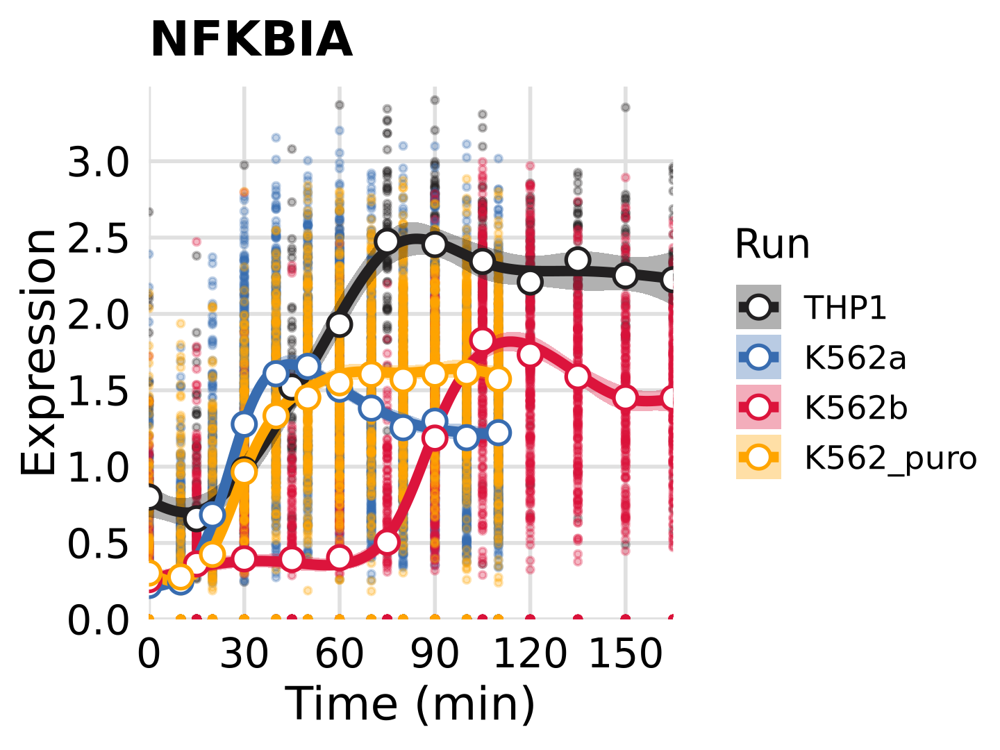

In [21]:
options(repr.plot.width = 4.8, repr.plot.height = 3.6, repr.plot.res = 300)

time_map <- c(K562a = 110, K562_puro = 110, THP1 = 165, K562b = 165)  # adjust as needed
offset_map   = c(K562a = 0, K562_puro = 0, THP1 = -10, K562b = -68)

p <- plot_tradeSeq_gene_multirun_pub(
  gamList_ls     = gamList.ls,
  sce_ls         = sce.ls,
  counts_sub_ls  = counts_sub.ls,
  PT_ls          = PT.ls,
  sf_ls          = sf.ls,
  CW_ls          = CW.ls,          # or NULL
  keys           = c("THP1","K562a","K562b", "K562_puro"),



  key_labels     = NULL,
  colours        = c(THP1="#222021", K562a="#386cb0", K562b="#DC143C", K562_puro="#FFA500"),

  # offset_map = offset_map,
  time_max_map   = time_map,
  plot_normalized_pt = FALSE,

  x_tick_step    = 30,
  color_points_by_run = TRUE,
  points_size    = 0.75,
  points_alpha   = 0.30,

  show_legend    = TRUE,
  gene = "NFKBIA"
)
print(p)

In [22]:
features.ls = list()
avail_genes.ls = list()

for (key in c('K562a', 'K562_puro', 'K562b', 'THP1')) {
    tmp = asso_df.ls[[key]]
    avail_genes.ls[[key]] = names(gamList.ls[[key]])

    tmp = tmp[tmp$pvalue_1 < 0.05, ]
    features.ls[[key]] = rownames(tmp)
}

features = union(union(features.ls[['K562a']], features.ls[['K562b']]), features.ls[['THP1']])
features = union(features, features.ls[['K562_puro']])

avail_genes = intersect(intersect(avail_genes.ls[['K562a']], avail_genes.ls[['K562b']]), avail_genes.ls[['THP1']])
avail_genes = intersect(avail_genes, avail_genes.ls[['K562_puro']])

length(features)
length(avail_genes)
length(intersect(features, avail_genes))

[1] 4477

[1] 3146

[1] 3146

In [23]:
traj.ls = list()

for (key in c('K562a', 'K562_puro', 'K562b', 'THP1')) {
    if (key %in% c('K562a', 'K562_puro')) {
        t_max = 110
        t_interval = 10
    } else {
        t_max = 165
        t_interval = 15
    }

    nPoints = 1+((length(unique(PT.ls[[key]]))-1)*t_interval)
    
    tmp <- .get_traj_from_predictSmooth(gamList.ls[[key]], features, nPoints = nPoints, lineage_pick = 1, 
                                        sce = sce.ls[[key]], sizeFactors = sf.ls[[key]])
    print(tmp$tt * t_max)
    traj.ls[[key]] = tmp
    rm(tmp) 
}

Using lineage = 1 (predict(gam,...) w/ reference offset)



  [1]   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
 [19]  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
 [37]  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
 [55]  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
 [73]  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
 [91]  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
[109] 108 109 110


Using lineage = 1 (predict(gam,...) w/ reference offset)



  [1]   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
 [19]  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
 [37]  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
 [55]  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
 [73]  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
 [91]  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
[109] 108 109 110


Using lineage = 1 (predict(gam,...) w/ reference offset)



  [1]   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
 [19]  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
 [37]  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
 [55]  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
 [73]  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
 [91]  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
[109] 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
[127] 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
[145] 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
[163] 162 163 164 165


Using lineage = 1 (predict(gam,...) w/ reference offset)



  [1]   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
 [19]  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
 [37]  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
 [55]  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
 [73]  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
 [91]  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
[109] 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
[127] 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
[145] 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
[163] 162 163 164 165


In [24]:
dim(traj.ls[['K562a']]$traj_mat)
dim(traj.ls[['K562_puro']]$traj_mat)
dim(traj.ls[['K562b']]$traj_mat)
dim(traj.ls[['THP1']]$traj_mat)

[1] 3362  111

[1] 4317  111

[1] 3655  166

[1] 3667  166

In [25]:
# ============================================================
# Apply manual offsets to traj_mat.ls (list(traj_mat=..., tt=...))
# and truncate all to the shortest aligned duration.
#
# EXPECTED:
#   traj_mat.ls[[k]]$traj_mat : genes x T matrix
#   traj_mat.ls[[k]]$tt       : length T numeric in [0,1]
#   time_map[[k]]             : experiment duration in minutes (e.g. 110, 165)
#   offset_map[[k]]           : shift in minutes, applied as aligned_time = time + offset
# ============================================================

stopifnot(exists("traj.ls"), exists("time_map"), exists("offset_map"))

keys_use <- intersect(intersect(names(traj.ls), names(time_map)), names(offset_map))
stopifnot(length(keys_use) >= 2)

# ---- build per-key aligned matrices (drop negative aligned times) ----
traj_shifted <- list()
t_aligned_by_key <- list()

for (k in keys_use) {
  obj <- traj.ls[[k]]

  mat <- obj$traj_mat
  tt  <- as.numeric(obj$tt)
  stopifnot(is.matrix(mat), length(tt) == ncol(mat))

  TMAX <- as.numeric(time_map[[k]])
  off  <- as.numeric(offset_map[[k]])

  # real time grid in minutes
  t_real <- tt * TMAX

  # If you expect exact integer minutes, round very slightly to kill 1e-15 noise
  t_real <- round(t_real, 6)

  # apply offset
  t_aligned <- t_real + off

  keep <- which(is.finite(t_aligned) & t_aligned >= 0)
  if (!length(keep)) stop(sprintf("[%s] offset=%g removes all timepoints.", k, off))

  mat2 <- mat[, keep, drop = FALSE]
  t2   <- t_aligned[keep]

  # set aligned time as column names (this is what you want downstream)
  colnames(mat2) <- as.character(t2)

  traj_shifted[[k]] <- mat2
  t_aligned_by_key[[k]] <- t2

  cat(sprintf("[%s] TMAX=%g, offset=%g => aligned range %.2f..%.2f (n=%d)\n",
              k, TMAX, off, min(t2), max(t2), length(t2)))
}

# ---- truncate to the shortest aligned duration across keys ----
t_end <- min(vapply(t_aligned_by_key, max, numeric(1), na.rm = TRUE))
t_end <- floor(t_end + 1e-9)  # ensure stable endpoint if near-integer

cat("Shortest aligned end time across keys:", t_end, "min\n")

# Because each run has its own grid (but you constructed these to be per-minute),
# we subset to aligned times in [0, t_end]. If grids are exactly integer minutes,
# this will give identical lengths.
traj_trunc <- lapply(keys_use, function(k) {
  m <- traj_shifted[[k]]
  t <- as.numeric(colnames(m))
  keep <- which(is.finite(t) & t >= 0 & t <= t_end)
  m2 <- m[, keep, drop = FALSE]

  # Optional: if you want strict 0: t_end naming (integers)
  # and your times are essentially integer minutes:
  t_int <- round(as.numeric(colnames(m2)))
  colnames(m2) <- as.character(t_int)

  m2
})
names(traj_trunc) <- keys_use

# (Optional) also force shared genes across keys
# shared_genes <- Reduce(intersect, lapply(traj_trunc, rownames))
# traj_trunc_shifted.ls <- lapply(traj_trunc, function(m) m[shared_genes, , drop = FALSE])
traj_trunc_shifted.ls <- traj_trunc

# ---- outputs ----
# traj_trunc_shifted.ls[[k]] : genes x (0..t_end) aligned minutes (after applying offsets)
traj_trunc_shifted.ls 

[K562a] TMAX=110, offset=0 => aligned range 0.00..110.00 (n=111)
[K562_puro] TMAX=110, offset=0 => aligned range 0.00..110.00 (n=111)
[K562b] TMAX=165, offset=-68 => aligned range 0.00..97.00 (n=98)
[THP1] TMAX=165, offset=-10 => aligned range 0.00..155.00 (n=156)
Shortest aligned end time across keys: 97 min


,0,1,2,3,4,5,6,7,8,9,...,88,89,90,91,92,93,94,95,96,97
NFKBIA,0.208316442,0.211178401,0.214271554,0.217802748,0.221992154,0.227077836,0.233322360,0.241021725,0.250517019,0.262209318,...,1.25463323,1.25064935,1.24696454,1.24356168,1.24042386,1.23753430,1.23487640,1.23243366,1.23018971,1.22812831
CXCL3,0.071459868,0.075631228,0.080087695,0.084904085,0.090169321,0.095989101,0.102489378,0.109820865,0.118164819,0.127740438,...,0.86729994,0.86521268,0.86294202,0.86052255,0.85798871,0.85537470,0.85271450,0.85004184,0.84739016,0.84479267
CD69,0.029772538,0.031878498,0.034157883,0.036655111,0.039424468,0.042532351,0.046060259,0.050108771,0.054802838,0.060298815,...,0.56243191,0.55575158,0.54938195,0.54344083,0.53804249,0.53329835,0.52931804,0.52621048,0.52408534,0.52305460
CD83,0.024998619,0.025841400,0.026713455,0.027617094,0.028554835,0.029529418,0.030543826,0.031601303,0.032705379,0.033859893,...,0.31953525,0.32374039,0.32804377,0.33244801,0.33695584,0.34157003,0.34629342,0.35112895,0.35607961,0.36114848
ARL4A,1.103874059,1.103865440,1.103906359,1.104046358,1.104335007,1.104821929,1.105556845,1.106589629,1.107970374,1.109749468,...,1.48520407,1.48627861,1.48700775,1.48736881,1.48733921,1.48689651,1.48601843,1.48468286,1.48286791,1.48055194
ICAM1,0.015832844,0.016298625,0.016782796,0.017291119,0.017829997,0.018406560,0.019028773,0.019705577,0.020447059,0.021264676,...,0.33847034,0.33580920,0.33325069,0.33084833,0.32865440,0.32672021,0.32509641,0.32383340,0.32298176,0.32259280
CXCL8,0.021931708,0.023481320,0.025148971,0.026954711,0.028922388,0.031080349,0.033462314,0.036108467,0.039066818,0.042394913,...,0.41800921,0.41653461,0.41534329,0.41448857,0.41402400,0.41400373,0.41448296,0.41551847,0.41716916,0.41949672
BTG2,0.104611048,0.109772110,0.115197277,0.120924617,0.126997419,0.133464805,0.140382448,0.147813413,0.155829141,0.164510600,...,0.49797889,0.49379544,0.48969564,0.48569631,0.48181382,0.47806417,0.47446296,0.47102545,0.46776663,0.46470121
BIRC3,0.010236747,0.009587813,0.008989367,0.008446031,0.007960722,0.007535136,0.007170203,0.006866514,0.006624734,0.006446005,...,0.24707336,0.24954711,0.25222273,0.25511287,0.25823087,0.26159089,0.26520795,0.26909802,0.27327808,0.27776626
DDIT4,0.148665373,0.152857985,0.157166944,0.161602494,0.166175688,0.170898440,0.175783573,0.180844880,0.186097187,0.191556422,...,0.56314503,0.56404201,0.56491996,0.56576907,0.56657951,0.56734141,0.56804485,0.56867990,0.56923662,0.56970506


In [26]:
# ============================================================
# Apply time rescaling + manual offsets to traj.ls (list(traj_mat=..., tt=...))
# then resample each trajectory to EVERY MINUTE on the aligned time axis,
# and finally truncate all to the shortest aligned duration.
#
# DEFAULT RESCALING:
#   K562a -> 1.00
#   K562b -> 1.00
#   THP1  -> 0.75   (condense THP1 in time)
#
# EXPECTED:
#   traj.ls[[k]]$traj_mat : genes x T matrix
#   traj.ls[[k]]$tt       : length T numeric in [0,1]
#   time_map[[k]]         : experiment duration in minutes
#   offset_map[[k]]       : shift in minutes, applied after rescaling
#
# OPTIONAL:
#   scale_map             : named list/vector overriding defaults
# ============================================================

stopifnot(exists("traj.ls"), exists("time_map"), exists("offset_map"))

keys_use <- intersect(intersect(names(traj.ls), names(time_map)), names(offset_map))
stopifnot(length(keys_use) >= 2)

# ---- default scale factors ----
default_scale_map <- stats::setNames(rep(1, length(keys_use)), keys_use)
if ("THP1" %in% keys_use) default_scale_map["THP1"] <- 0.65

# allow user override via scale_map
if (exists("scale_map")) {
  scale_map_use <- default_scale_map
  nm <- intersect(names(scale_map_use), names(scale_map))
  scale_map_use[nm] <- as.numeric(unlist(scale_map[nm]))
} else {
  scale_map_use <- default_scale_map
}

stopifnot(all(is.finite(scale_map_use)), all(scale_map_use > 0))

# ---- helper: interpolate each gene to a new time grid ----
.interpolate_rows <- function(mat, x, xout) {
  stopifnot(is.matrix(mat), length(x) == ncol(mat), length(xout) >= 1)

  ord <- order(x)
  x   <- x[ord]
  mat <- mat[, ord, drop = FALSE]

  if (anyDuplicated(x)) {
    stop("Duplicated time points encountered after rescaling; choose a different scale_factor or collapse duplicates first.")
  }

  out <- t(vapply(
    seq_len(nrow(mat)),
    function(i) {
      stats::approx(
        x = x,
        y = mat[i, ],
        xout = xout,
        method = "linear",
        rule = 1,
        ties = "ordered"
      )$y
    },
    numeric(length(xout))
  ))

  rownames(out) <- rownames(mat)
  colnames(out) <- as.character(xout)
  out
}

# ---- build per-key aligned + resampled matrices ----
traj_rescaled <- list()
t_aligned_by_key <- list()

for (k in keys_use) {
  obj <- traj.ls[[k]]

  mat <- obj$traj_mat
  tt  <- as.numeric(obj$tt)
  stopifnot(is.matrix(mat), length(tt) == ncol(mat))

  TMAX <- as.numeric(time_map[[k]])
  off  <- as.numeric(offset_map[[k]])
  sf   <- as.numeric(scale_map_use[[k]])

  # original real-time grid in minutes
  t_real <- round(tt * TMAX, 6)

  # rescale time axis first, then apply offset
  t_aligned <- (t_real * sf) + off

  # drop negative aligned times
  keep <- which(is.finite(t_aligned) & t_aligned >= 0)
  if (!length(keep)) {
    stop(sprintf("[%s] scale_factor=%g and offset=%g remove all timepoints.", k, sf, off))
  }

  mat_obs <- mat[, keep, drop = FALSE]
  t_obs   <- t_aligned[keep]

  # resample to every integer minute within observed nonnegative range
  t_grid <- seq(
    from = ceiling(min(t_obs) - 1e-9),
    to   = floor(max(t_obs) + 1e-9),
    by   = 1
  )
  if (!length(t_grid)) {
    stop(sprintf("[%s] no integer-minute grid remains after rescaling/offset.", k))
  }

  mat_resamp <- .interpolate_rows(mat_obs, x = t_obs, xout = t_grid)

  traj_rescaled[[k]] <- mat_resamp
  t_aligned_by_key[[k]] <- t_grid

  cat(sprintf(
    "[%s] TMAX=%g, scale=%g, offset=%g => aligned range %.2f..%.2f, resampled to %d minute points\n",
    k, TMAX, sf, off, min(t_obs), max(t_obs), length(t_grid)
  ))
}

# ---- truncate to shortest aligned end time across keys ----
t_end <- min(vapply(t_aligned_by_key, max, numeric(1), na.rm = TRUE))
t_end <- floor(t_end + 1e-9)

cat("Shortest aligned end time across keys after rescaling:", t_end, "min\n")

traj_trunc <- lapply(keys_use, function(k) {
  m <- traj_rescaled[[k]]
  t <- as.numeric(colnames(m))
  keep <- which(is.finite(t) & t >= 0 & t <= t_end)
  m2 <- m[, keep, drop = FALSE]
  colnames(m2) <- as.character(round(as.numeric(colnames(m2))))
  m2
})
names(traj_trunc) <- keys_use

# ---- ensure identical shared minute grid across all keys ----
shared_minutes <- Reduce(intersect, lapply(traj_trunc, colnames))
shared_minutes <- as.character(sort(as.numeric(shared_minutes)))

if (length(shared_minutes) == 0) {
  stop("No shared aligned minute grid remains across trajectories after rescaling.")
}

traj_trunc_rescaled.ls <- lapply(traj_trunc, function(m) {
  m[, shared_minutes, drop = FALSE]
})

# ---- optional: force shared genes across keys ----
# shared_genes <- Reduce(intersect, lapply(traj_trunc_rescaled.ls, rownames))
# traj_trunc_rescaled.ls <- lapply(traj_trunc_rescaled.ls, function(m) {
#   m[shared_genes, , drop = FALSE]
# })

# ---- output ----
# traj_trunc_rescaled.ls[[k]] : genes x shared aligned minutes
cat("Final shared aligned minute range:",
    min(as.numeric(shared_minutes)), "..", max(as.numeric(shared_minutes)),
    " (n =", length(shared_minutes), ")\n")

traj_trunc_rescaled.ls

[K562a] TMAX=110, scale=1, offset=0 => aligned range 0.00..110.00, resampled to 111 minute points
[K562_puro] TMAX=110, scale=1, offset=0 => aligned range 0.00..110.00, resampled to 111 minute points
[K562b] TMAX=165, scale=1, offset=-68 => aligned range 0.00..97.00, resampled to 98 minute points
[THP1] TMAX=165, scale=0.65, offset=-10 => aligned range 0.40..97.25, resampled to 97 minute points
Shortest aligned end time across keys after rescaling: 97 min
Final shared aligned minute range: 1 .. 97  (n = 97 )


,1,2,3,4,5,6,7,8,9,10,...,88,89,90,91,92,93,94,95,96,97
NFKBIA,0.211178401,0.214271554,0.217802748,0.221992154,0.227077836,0.233322360,0.241021725,0.250517019,0.262209318,0.276578511,...,1.25463323,1.25064935,1.24696454,1.24356168,1.24042386,1.23753430,1.23487640,1.23243366,1.23018971,1.22812831
CXCL3,0.075631228,0.080087695,0.084904085,0.090169321,0.095989101,0.102489378,0.109820865,0.118164819,0.127740438,0.138814249,...,0.86729994,0.86521268,0.86294202,0.86052255,0.85798871,0.85537470,0.85271450,0.85004184,0.84739016,0.84479267
CD69,0.031878498,0.034157883,0.036655111,0.039424468,0.042532351,0.046060259,0.050108771,0.054802838,0.060298815,0.066793826,...,0.56243191,0.55575158,0.54938195,0.54344083,0.53804249,0.53329835,0.52931804,0.52621048,0.52408534,0.52305460
CD83,0.025841400,0.026713455,0.027617094,0.028554835,0.029529418,0.030543826,0.031601303,0.032705379,0.033859893,0.035069023,...,0.31953525,0.32374039,0.32804377,0.33244801,0.33695584,0.34157003,0.34629342,0.35112895,0.35607961,0.36114848
ARL4A,1.103865440,1.103906359,1.104046358,1.104335007,1.104821929,1.105556845,1.106589629,1.107970374,1.109749468,1.111977690,...,1.48520407,1.48627861,1.48700775,1.48736881,1.48733921,1.48689651,1.48601843,1.48468286,1.48286791,1.48055194
ICAM1,0.016298625,0.016782796,0.017291119,0.017829997,0.018406560,0.019028773,0.019705577,0.020447059,0.021264676,0.022171514,...,0.33847034,0.33580920,0.33325069,0.33084833,0.32865440,0.32672021,0.32509641,0.32383340,0.32298176,0.32259280
CXCL8,0.023481320,0.025148971,0.026954711,0.028922388,0.031080349,0.033462314,0.036108467,0.039066818,0.042394913,0.046161973,...,0.41800921,0.41653461,0.41534329,0.41448857,0.41402400,0.41400373,0.41448296,0.41551847,0.41716916,0.41949672
BTG2,0.109772110,0.115197277,0.120924617,0.126997419,0.133464805,0.140382448,0.147813413,0.155829141,0.164510600,0.173949620,...,0.49797889,0.49379544,0.48969564,0.48569631,0.48181382,0.47806417,0.47446296,0.47102545,0.46776663,0.46470121
BIRC3,0.009587813,0.008989367,0.008446031,0.007960722,0.007535136,0.007170203,0.006866514,0.006624734,0.006446005,0.006332357,...,0.24707336,0.24954711,0.25222273,0.25511287,0.25823087,0.26159089,0.26520795,0.26909802,0.27327808,0.27776626
DDIT4,0.152857985,0.157166944,0.161602494,0.166175688,0.170898440,0.175783573,0.180844880,0.186097187,0.191556422,0.197239694,...,0.56314503,0.56404201,0.56491996,0.56576907,0.56657951,0.56734141,0.56804485,0.56867990,0.56923662,0.56970506


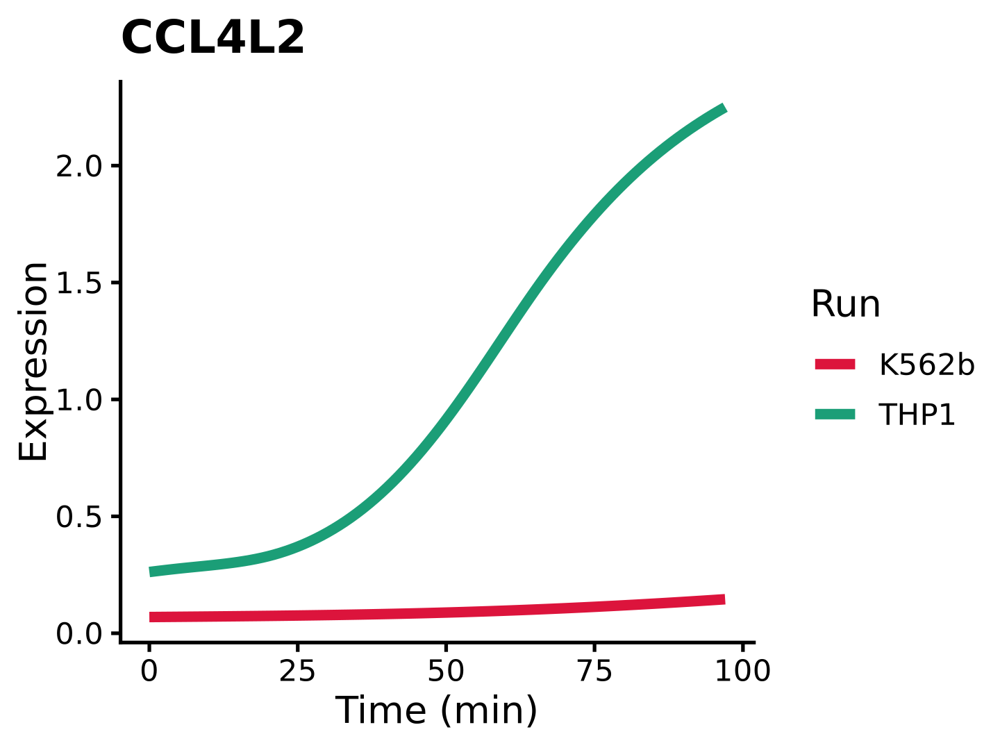

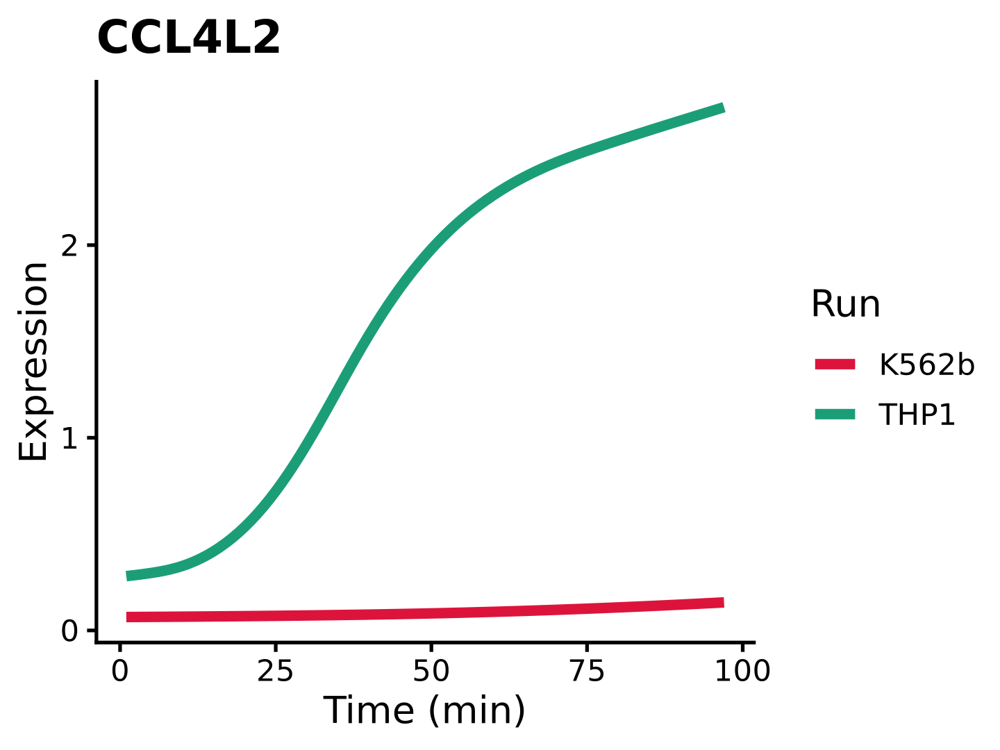

In [27]:
# ---- examples ----
gene_query <- "CCL4L2"

print(plot_traj_trunc_gene(traj_trunc_shifted.ls, gene_query, mode = "expr"))
print(plot_traj_trunc_gene(traj_trunc_rescaled.ls, gene_query, mode = "expr"))

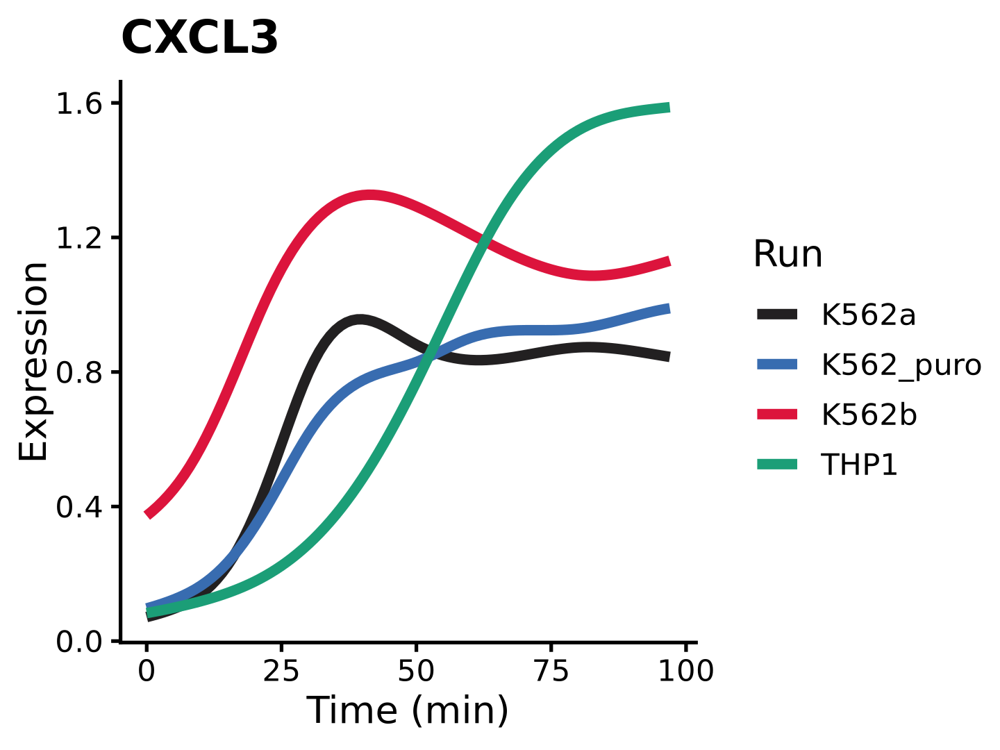

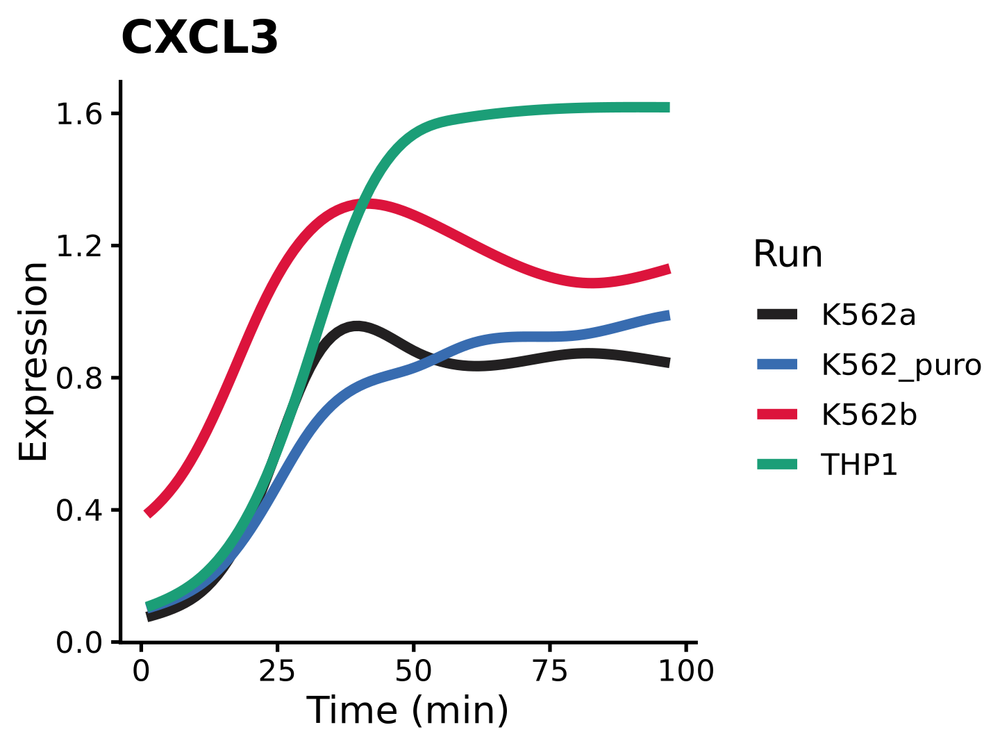

In [28]:
# ---- examples ----
gene_query <- "CXCL3"

print(plot_traj_trunc_gene(traj_trunc_shifted.ls, gene_query, mode = "expr"))
print(plot_traj_trunc_gene(traj_trunc_rescaled.ls, gene_query, mode = "expr"))

In [29]:
ConstructTrajMat = function(traj) {
    t_max = dim(traj[['K562a']])[2]
    tt = c(1:t_max)/t_max
    
    cn0 <- colnames(traj[[1]])
    stopifnot(all(vapply(traj, function(m) is.matrix(m) && identical(colnames(m), cn0), logical(1))))
    
    traj_all <- do.call(rbind, Map(function(mat, key) {
      rownames(mat) <- paste0(rownames(mat), "_", key)
      mat
    }, traj, names(traj)))
    
    dim(traj_all)
    
    traj_mat = as.matrix(traj_all)
    storage.mode(traj_mat) <- "double"
    message("Valid trajectories: ", nrow(traj_mat), " genes x ", ncol(traj_mat), " timepoints.")
    orig_label = rownames(traj_mat)
    
    return(list(a = tt, b = traj_mat))
}                     

# Dimensionality reduction

In [32]:
z_row <- function(M) {
  mu <- rowMeans(M, na.rm = TRUE)
  sd <- matrixStats::rowSds(M, na.rm = TRUE)
  sd[!is.finite(sd) | sd == 0] <- 1
  sweep(sweep(M, 1, mu, "-"), 1, sd, "/")
}

sil_to_alpha <- function(s) {
  s <- pmax(-0.2, pmin(0.8, s))
  0.15 + (s + 0.2) / (0.8 + 0.2) * (1.0 - 0.15)
}

In [33]:
set.seed(1)

res = ConstructTrajMat(traj_trunc_rescaled.ls)
tt = res$a
traj_mat = res$b
# desc = get_descriptors(traj_mat, tt, N_minutes = 10/length(tt), z_diff_threshold = 0.2, require_consecutive = 5)
# desc = get_descriptors(traj_mat, tt, N_minutes = 10/length(tt), z_diff_threshold = 0.2, require_consecutive = 30, onset_mode = 'horizontal')
# desc = get_descriptors(traj_mat, tt, N_minutes = 10/length(tt), z_diff_threshold = 0.2, require_consecutive = 30, onset_mode = 'horizontal', pseudocount=1e-1)
desc = get_descriptors(traj_mat, tt, N_minutes = 10/length(tt), z_diff_threshold = 0.2, require_consecutive = 30, onset_mode = 'horizontal', pseudocount=1e-3)


X <- z_row(traj_mat)
gene_celltype <- rownames(traj_mat)

pc <- prcomp(X, center = FALSE, scale. = FALSE)
# pc <- prcomp(X, center = TRUE, scale. = FALSE)

Valid trajectories: 15001 genes x 97 timepoints.



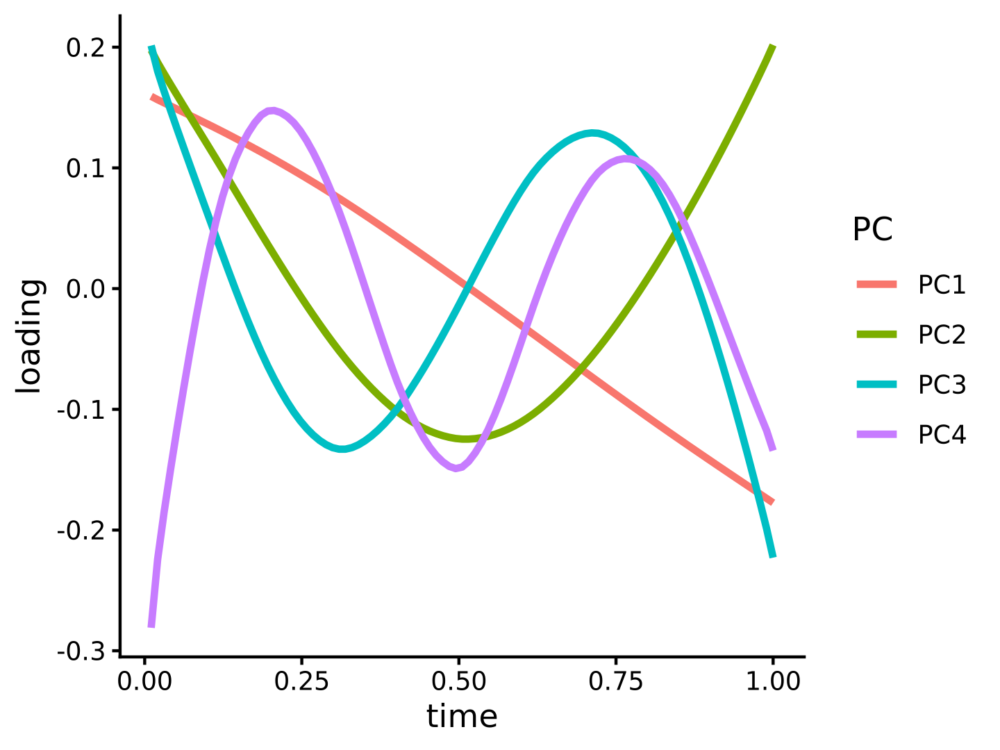

In [124]:
options(repr.plot.width = 4.8, repr.plot.height = 3.6, repr.plot.res = 300)

load_df <- data.frame(
  time = tt,
  PC1 = pc$rotation[, 1],
  PC2 = pc$rotation[, 2],
  PC3 = pc$rotation[, 3],
  PC4 = pc$rotation[, 4]
  # PC5 = pc$rotation[, 5],
  # PC6 = pc$rotation[, 6]
)

load_df_long <- load_df %>%
  pivot_longer(-time, names_to = "PC", values_to = "loading")

ggplot(load_df_long, aes(x = time, y = loading, color = PC)) +
  geom_line(linewidth = 1.2) +
  theme_classic()

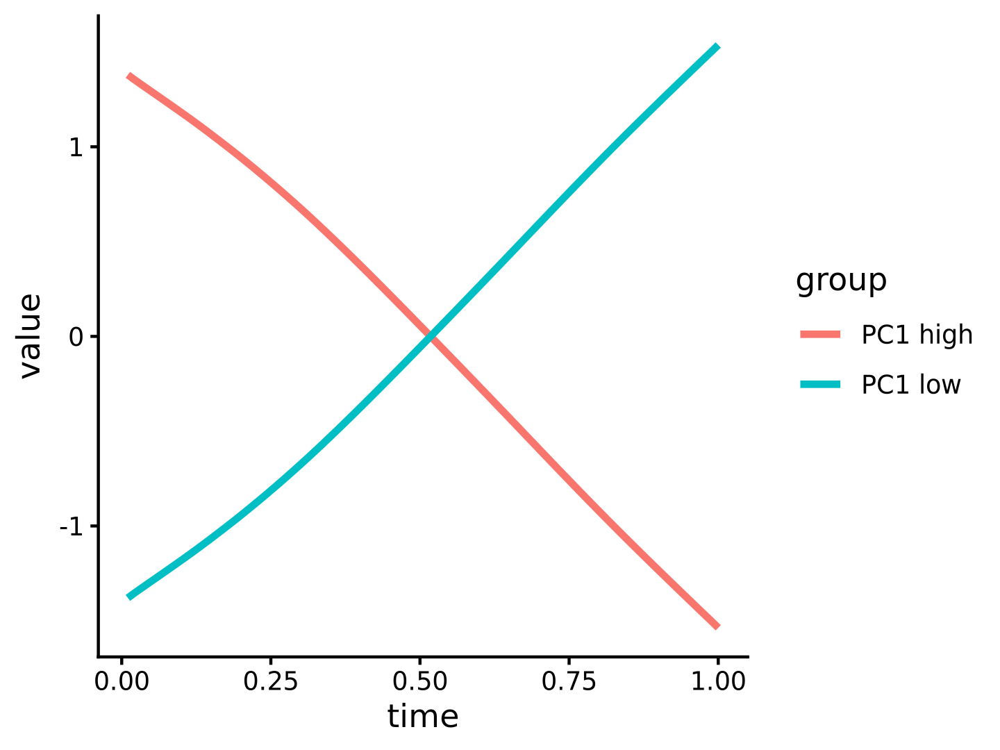

In [125]:
pc1_sd <- sd(pc$x[, 1])

traj_pc1_high <- pc$center + pc1_sd * pc$rotation[, 1]
traj_pc1_low  <- pc$center - pc1_sd * pc$rotation[, 1]

plot_df <- data.frame(
  time = rep(tt, 2),
  value = c(traj_pc1_high, traj_pc1_low),
  group = rep(c("PC1 high", "PC1 low"), each = length(tt))
)

ggplot(plot_df, aes(time, value, color = group)) +
  geom_line(linewidth = 1.2) +
  theme_classic()

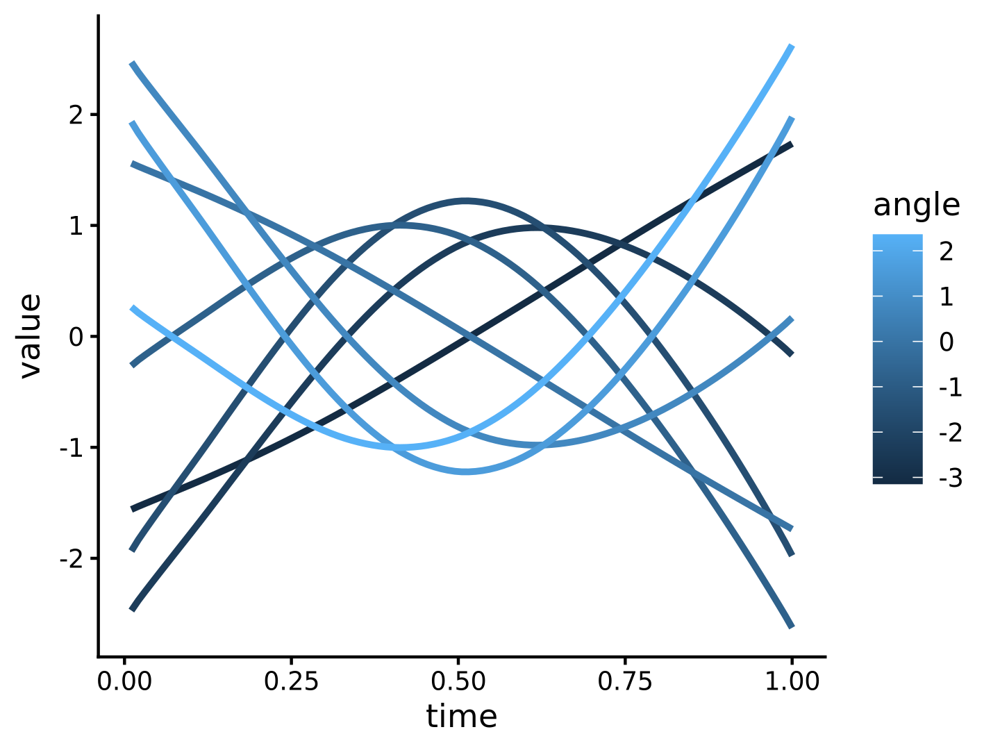

In [126]:
r_use <- median(sqrt(pc$x[,1]^2 + pc$x[,2]^2))

angles <- seq(-pi, pi, length.out = 9)[-9]

arch <- lapply(seq_along(angles), function(i) {
  theta <- angles[i]
  
  traj <- pc$center +
    r_use * cos(theta) * pc$rotation[, 1] +
    r_use * sin(theta) * pc$rotation[, 2]
  
  data.frame(
    time = tt,
    value = traj,
    angle = theta,
    archetype = paste0("angle_", i)
  )
}) %>%
  bind_rows()

ggplot(arch, aes(time, value, group = archetype, color = angle)) +
  geom_line(linewidth = 1.1) +
  theme_classic()

In [206]:
pc_df <- data.frame(
  gene_celltype = gene_celltype,
  gene = sapply(gene_celltype, function(x) { strsplit(x, '_')[[1]][1] }, USE.NAMES = F),
  cell_type = sub("^[^_]+_", "", gene_celltype),  PC1 = pc$x[, 1],
  PC2 = pc$x[, 2],
  PC3 = pc$x[, 3]
) %>% left_join(desc, by = c('gene_celltype'))

rownames(pc_df) = pc_df$gene_celltype
pc_df = pc_df %>% select(-gene_celltype)

for (nm in c("waldStat_1", "meanLogFC", "pvalue_1", "qval_1")) {
    pc_df[[nm]] <- NA_real_
}

# Build lookup table from asso_df.ls
lookup_df <- do.call(
  rbind,
  lapply(names(asso_df.ls), function(ct) {
    df <- asso_df.ls[[ct]]
    if (is.null(df) || nrow(df) == 0) return(NULL)

    out <- data.frame(
      cell_type = ct,
      gene = rownames(df),
      stringsAsFactors = FALSE,
      row.names = NULL
    )

    for (nm in c("waldStat_1", "meanLogFC", "pvalue_1", "qval_1")) {
      out[[paste0(nm, "_lookup")]] <- if (nm %in% colnames(df)) df[[nm]] else NA_real_
    }

    out
  })
)

In [207]:
pc_df <- pc_df %>%
  rownames_to_column("row_id") %>%
  left_join(lookup_df, by = c("cell_type", "gene")) %>%
  mutate(
    waldStat_1 = ifelse(is.na(waldStat_1), waldStat_1_lookup, waldStat_1),
    meanLogFC  = ifelse(is.na(meanLogFC),  meanLogFC_lookup,  meanLogFC),
    pvalue_1   = ifelse(is.na(pvalue_1),   pvalue_1_lookup,   pvalue_1),
    qval_1     = ifelse(is.na(qval_1),     qval_1_lookup,     qval_1)
  ) %>%
  select(
    -waldStat_1_lookup,
    -meanLogFC_lookup,
    -pvalue_1_lookup,
    -qval_1_lookup
  ) %>%
  column_to_rownames("row_id")

In [209]:
# Quick sanity check
cat("Remaining NA counts:\n")
print(colSums(is.na(pc_df[, c("waldStat_1", "meanLogFC", "pvalue_1", "qval_1")])))
print(head(pc_df[, c("gene", "waldStat_1", "meanLogFC", "pvalue_1", "qval_1")], 10))

Remaining NA counts:
waldStat_1  meanLogFC   pvalue_1     qval_1 
         4          4          4          4 
               gene waldStat_1 meanLogFC pvalue_1 qval_1
NFKBIA_K562a NFKBIA  1967.3776 2.8062932        0      0
CXCL3_K562a   CXCL3   742.3239 2.7863760        0      0
CD69_K562a     CD69   602.3647 3.4546323        0      0
CD83_K562a     CD83   566.9987 2.1289979        0      0
ARL4A_K562a   ARL4A   466.5694 0.3653517        0      0
ICAM1_K562a   ICAM1   439.2142 2.9057450        0      0
CXCL8_K562a   CXCL8   426.5580 3.1128228        0      0
BTG2_K562a     BTG2   351.1097 1.7552631        0      0
BIRC3_K562a   BIRC3   322.0169 3.6008999        0      0
DDIT4_K562a   DDIT4   302.2627 1.3388896        0      0


# Cluster gene expression trajectories

In [128]:
cl.ls = list()
sil_df.ls = list()
D.ls = list()

# ORIGINAL

In [129]:
res = ConstructTrajMat(traj_trunc_shifted.ls)
tt = res$a
traj_mat = res$b
desc = get_descriptors(traj_mat, tt)

# CONFIG
set.seed(1)

X  <- z_row(traj_mat)
dt <- diff(tt)
Xd <- traj_mat[, -1, drop = FALSE] - traj_mat[, -ncol(traj_mat), drop = FALSE]
Xd <- sweep(Xd, 2, dt, "/")
Xd <- z_row(Xd)
stopifnot(nrow(X) == nrow(Xd)) # sanity

D_x  <- as.dist(1 - cor(t(X),  use = "pairwise.complete.obs"))
D_dx <- as.dist(1 - cor(t(Xd), use = "pairwise.complete.obs"))
alpha  <- 0.95      # weight on expression shape vs derivative shape (0.6–0.85 is typical)
D <- alpha * as.matrix(D_x) + (1 - alpha) * as.matrix(D_dx)
D <- as.dist(D)

# =========================
# 3) Hierarchical clustering + choose K by silhouette
# =========================
hc <- hclust(D, method = "average")

K_grid = c(30)
sil <- sapply(K_grid, function(K) {
  cl <- cutree(hc, k = K)
  mean(silhouette(cl, D)[, 3])
})

# K_best <- K_grid[which.max(sil)]
# cat("Approach C: alpha =", alpha, " | silhouette-selected K =", K_best, "\n")

# plot(K_grid, sil, type = "b", xlab = "K", ylab = "Mean silhouette",
#      main = paste0("Approach C: K selection (alpha=", alpha, ")"))
K_best = 30

cl <- factor(cutree(hc, k = K_best))
head(cl)

Valid trajectories: 15001 genes x 98 timepoints.



NFKBIA_K562a  CXCL3_K562a   CD69_K562a   CD83_K562a  ARL4A_K562a  ICAM1_K562a 
           1            1            1            2            2            2 
30 Levels: 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 ... 30

In [130]:
sil_obj <- cluster::silhouette(as.integer(cl), D)
sil_df <- data.frame(gene = names(cl),
                     cluster = cl,
                     sil_width = sil_obj[, "sil_width"],
                     alpha = sil_to_alpha(sil_obj[, "sil_width"]),
                     stringsAsFactors = FALSE)

In [131]:
cl.ls[['shifted_a095_k30']] = cl
sil_df.ls[['shifted_a095_k30']] = sil_df
D.ls[['shifted_a095_k30']] = D

# NEW

In [388]:
res = ConstructTrajMat(traj_trunc_rescaled.ls)
tt = res$a
traj_mat = res$b

# CONFIG
K_grid <- 59:60
set.seed(1)

X  <- z_row(traj_mat)
dt <- diff(tt)
Xd <- traj_mat[, -1, drop = FALSE] - traj_mat[, -ncol(traj_mat), drop = FALSE]
Xd <- sweep(Xd, 2, dt, "/")
Xd <- z_row(Xd)
stopifnot(nrow(X) == nrow(Xd)) # sanity

D_x  <- as.dist(1 - cor(t(X),  use = "pairwise.complete.obs"))
D_dx <- as.dist(1 - cor(t(Xd), use = "pairwise.complete.obs"))
alpha  <- 0.85
D <- alpha * as.matrix(D_x) + (1 - alpha) * as.matrix(D_dx)
D <- as.dist(D)
hc <- hclust(D, method = "average")

K_grid = c(100)
sil <- sapply(K_grid, function(K) {
  cl <- cutree(hc, k = K)
  mean(silhouette(cl, D)[, 3])
})

# K_best <- K_grid[which.max(sil)]
# cat("Approach C: alpha =", alpha, " | silhouette-selected K =", K_best, "\n")

# options(repr.plot.width = 4, repr.plot.height = 4)
# plot(K_grid, sil, type = "b", xlab = "K", ylab = "Mean silhouette",
#      main = paste0("Approach C: K selection (alpha=", alpha, ")"))

K_best = 60

cl <- factor(cutree(hc, k = K_best))

sil_obj <- cluster::silhouette(as.integer(cl), D)
sil_df <- data.frame(gene = names(cl),
                     cluster = cl,
                     sil_width = sil_obj[, "sil_width"],
                     alpha = sil_to_alpha(sil_obj[, "sil_width"]),
                     stringsAsFactors = FALSE)

cl.ls[['rescaled_k30_a085']] = cl
sil_df.ls[['rescaled_k30_a085']] = sil_df
D.ls[['rescaled_k30_a085']] = D

Valid trajectories: 15001 genes x 97 timepoints.



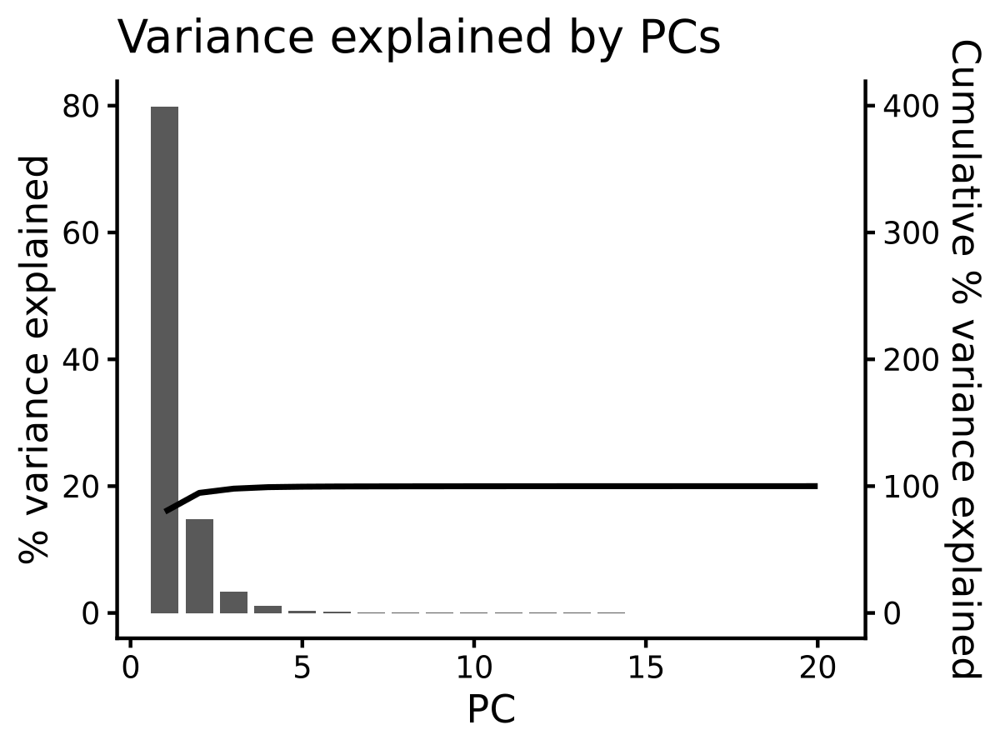

In [134]:
# Percent variance explained by each PC
pve <- 100 * (pc$sdev^2) / sum(pc$sdev^2)

# Optional: cumulative variance explained
cum_pve <- cumsum(pve)

# Put into a data frame
pve_df <- data.frame(
  PC = seq_along(pve),
  PVE = pve,
  CumPVE = cum_pve
)

options(repr.plot.width = 4, repr.plot.height = 3)

ggplot(pve_df[1:20, ], aes(x = PC, y = PVE)) +
  geom_col(width = 0.8) +
  geom_line(aes(y = CumPVE / 5), group = 1, linewidth = 0.8) +
  scale_y_continuous(
    name = "% variance explained",
    sec.axis = sec_axis(~ . * 5, name = "Cumulative % variance explained")
  ) +
  theme_classic(base_size = 11) +
  labs(title = "Variance explained by PCs")

In [135]:
sum(pve[c(1:3)])

[1] 98.0213

In [136]:
pc3_mat <- as.matrix(pc$x[, 1:3, drop = FALSE])
D_pc3 <- dist(pc3_mat, method = "euclidean")

K_grid_pc3 <- c(3:100)
hc_pc3 <- hclust(D_pc3, method = "average")

sil_pc3 <- sapply(K_grid_pc3, function(K) {
  cl_tmp <- cutree(hc_pc3, k = K)
  mean(cluster::silhouette(cl_tmp, D_pc3)[, 3])
})

# K_best_pc3 <- K_grid_pc3[which.max(sil_pc3)]
# cat("PC3-space clustering | silhouette-selected K =", K_best_pc3, "\n")

# options(repr.plot.width = 4.5, repr.plot.height = 3.2)

# plot(
#   K_grid_pc3, sil_pc3, type = "b",
#   xlab = "K", ylab = "Mean silhouette",
#   main = "Top-3 PC clustering: K selection"
# )

K_best_pc3 <- 60
cl_pc3 <- cutree(hc_pc3, k = K_best_pc3)

sil_obj_pc3 <- cluster::silhouette(as.integer(cl_pc3), D_pc3)
sil_df_pc3 <- data.frame(
  gene = names(cl_pc3),
  cluster = cl_pc3,
  sil_width = sil_obj_pc3[, "sil_width"],
  alpha = sil_to_alpha(sil_obj_pc3[, "sil_width"]),
  stringsAsFactors = FALSE
)

cl.ls[['rescaled_k60_pc3']] = cl_pc3
sil_df.ls[['rescaled_k60_pc3']] = sil_df_pc3
D.ls[['rescaled_k60_pc3']] = D_pc3

In [389]:
for (name in names(cl.ls)) {
    pc_df[[paste0('cluster_', name)]] = as.factor(cl.ls[[name]][rownames(pc_df)])
    pc_df[[paste0('sil_width_', name)]] = sil_df.ls[[name]][rownames(pc_df), 'sil_width']
}

table(pc_df$cluster_rescaled_k60_pc3)


   1    2    3    4    5    6    7    8    9   10   11   12   13   14   15   16 
 256  277 3935  242  752   53  166   34  202   11  804   56 5307  335  702  141 
  17   18   19   20   21   22   23   24   25   26   27   28   29   30   31   32 
  20   37   31   71   52   14   15  123   82   19   14   13    9   19   46   27 
  33   34   35   36   37   38   39   40   41   42   43   44   45   46   47   48 
 253   37    6   67   50   36   28   44   38  144   30    8   30   16  163   23 
  49   50   51   52   53   54   55   56   57   58   59   60 
  14   21   43   18   12   17    3   13   10    6    4    2 

Warning message in feature_plot_pc_simple(pc_df, feature = "cluster_rescaled_k60_pc3", :
"plot_order based on feature magnitude is only applied for numeric features."


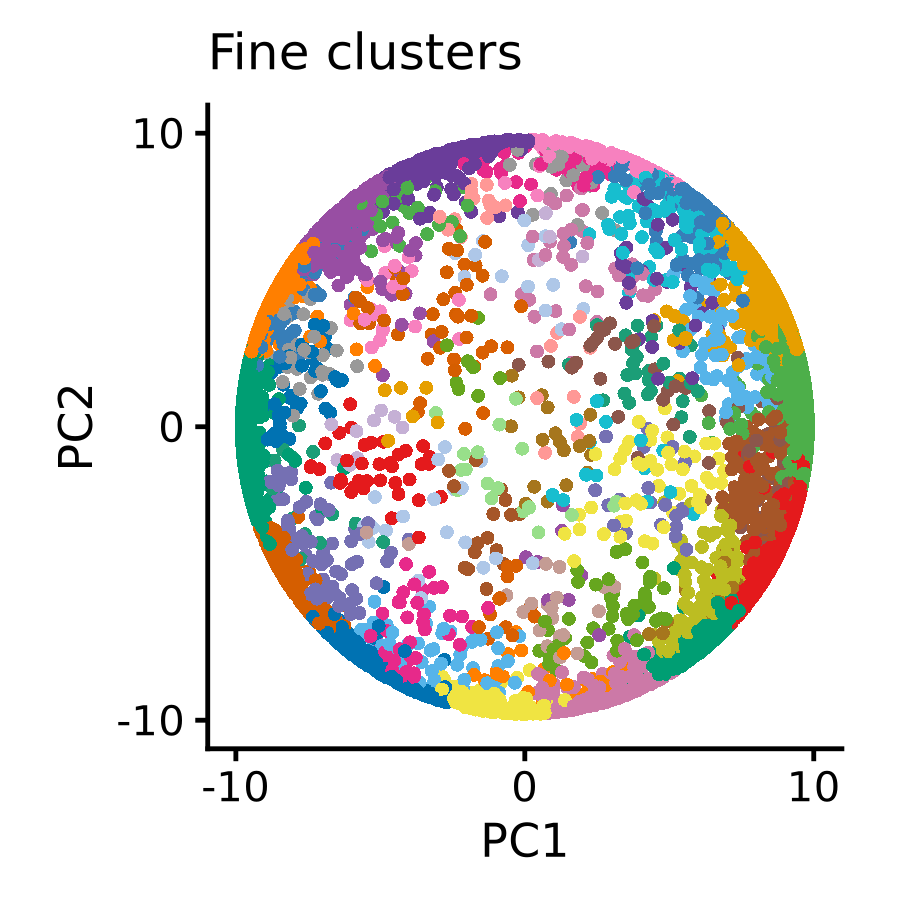

In [211]:
cat_colors = c("#0072B2","#D55E00","#009E73","#CC79A7","#E69F00","#56B4E9","#F0E442","#8C564B","#6A3D9A","#66A61E",
               "#E41A1C","#377EB8","#4DAF4A","#984EA3","#FF7F00","#A65628","#F781BF","#999999","#1B9E77","#7570B3",
               "#E7298A","#A6761D","#D95F02","#17BECF","#BCBD22","#AEC7E8","#FF9896","#98DF8A","#C5B0D5","#C49C94")

options(repr.plot.width = 3, repr.plot.height = 3)
p1 = feature_plot_pc_simple(pc_df, feature = "cluster_rescaled_k60_pc3", cat_colors = c(cat_colors, cat_colors, cat_colors, cat_colors), alpha_col = NULL, plot_order = 'plot_highest_last', show_legend = FALSE) + ggtitle('Fine clusters')

p2 <- plot_cluster_medoids_and_top_genes(seed = 10,
  traj_mat = traj_mat,
  X = X,
  tt = tt,
  cl = pc_df$cluster_rescaled_k60_pc3,
  D = D_pc3,
  asso_df.ls = asso_df.ls,
  top_n = 50,
  show_sil_text = TRUE,
  cat_colors = c(cat_colors, cat_colors, cat_colors, cat_colors)
)

options(repr.plot.width = 3, repr.plot.height = 3)
print(p1)

options(repr.plot.width = 20, repr.plot.height = 60)
print(p2)

In [495]:
# Subset original cluster 2
idx_c2 <- names(cl_pc3)[cl_pc3 == 2]
pc3_c2 <- pc3_mat[idx_c2, , drop = FALSE]

# Recluster cluster 2 at k = 10
D_c2 <- dist(pc3_c2)
hc_c2 <- hclust(D_c2, method = "average")
cl_c2_k10 <- cutree(hc_c2, k = 10)

# Add subcluster labels
pc_df_subset$cluster2_k10 <- NA_integer_
pc_df_subset[names(cl_c2_k10), "cluster2_k10"] <- cl_c2_k10

table(
  pc_df_subset$broad_cluster_v2,
  pc_df_subset$cluster2_k10
)

              
                1  2  3  4  5  6  7  8  9 10
  down_then_up  0  0  0  0  0  0  0  0  0  0
  impulse_up    5  3  9  1 10 13  1  8  0  0
  other         0  0  0  0  0  0  0  0  0  0
  trend_down    0  0  0  0  0  0  0  0  0  0
  trend_up      0  0  0  0  0  0  0  0  0  0

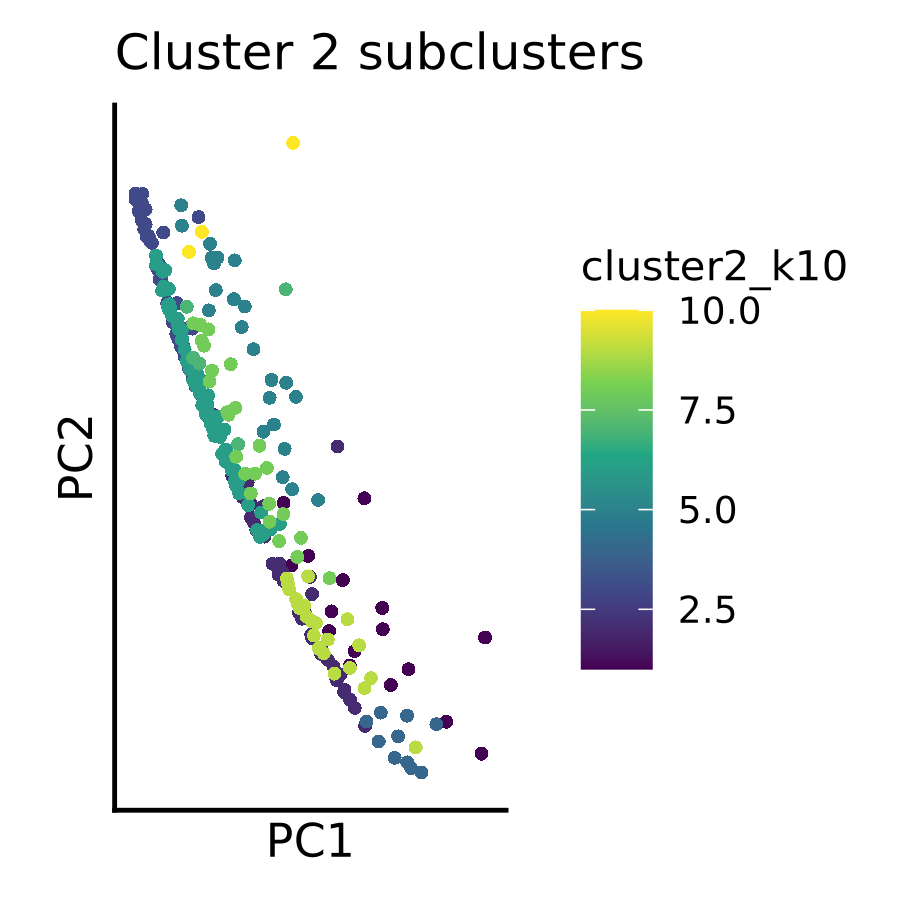

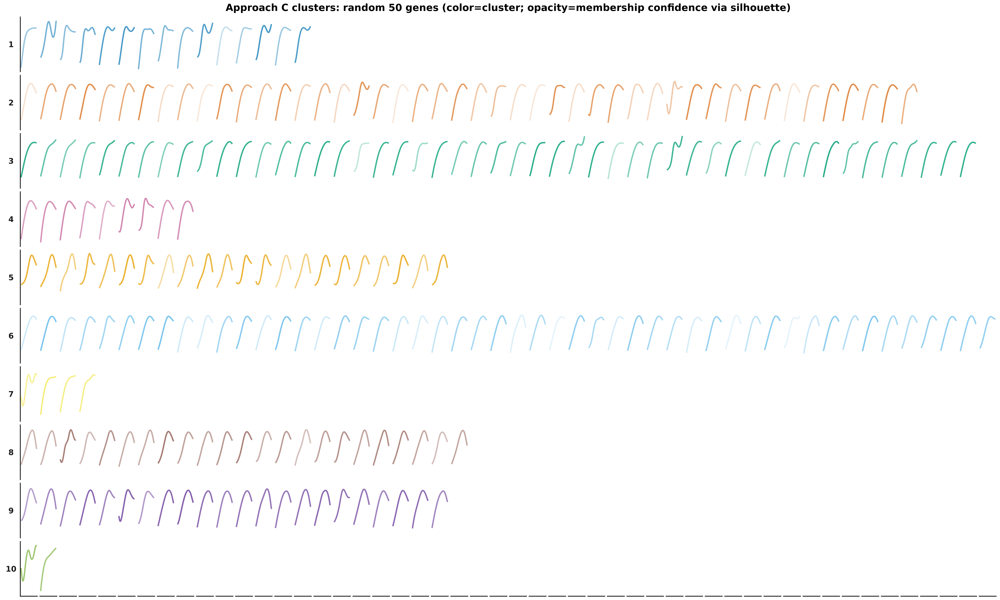

In [514]:
# Original cluster 2 genes
idx_c2 <- names(cl_pc3)[cl_pc3 == 2]

# Subset PC data and add the k=10 subcluster labels
pc_df_c2 <- pc_df[idx_c2, , drop = FALSE]
pc_df_c2$cluster2_k10 <- cl_c2_k10[rownames(pc_df_c2)]

# PC-space visualization
p1 <- feature_plot_pc_simple(
  pc_df_c2,
  feature = "cluster2_k10",
  cat_colors = cat_colors,
  alpha_col = NULL,
  plot_order = "plot_highest_last",
  show_legend = TRUE
) +
  ggtitle("Cluster 2 subclusters")

# Trajectory curves for the 10 subclusters
p2 <- plot_cluster_medoids_and_top_genes(
  seed = 10,
  traj_mat = traj_mat[idx_c2, , drop = FALSE],
  X = X[idx_c2, , drop = FALSE],
  tt = tt,
  cl = cl_c2_k10[idx_c2],
  D = D_c2,
  asso_df.ls = asso_df.ls,
  top_n = 50,
  show_sil_text = FALSE,
  cat_colors = cat_colors
)

options(repr.plot.width = 3, repr.plot.height = 3)
print(p1)

options(repr.plot.width = 20, repr.plot.height = 12)
print(p2)

In [ ]:
# impulse-like: 1, 2, 4, 5, 8, 9
# trend-like: 3, 6, 7, 10

In [ ]:
pc_df$cluster_rescaled_k60_pc3 <- as.character(pc_df$cluster_rescaled_k60_pc3)

pc_df[idx_c2, "cluster_rescaled_k60_pc3"] <-
  paste0("2_", cl_c2_k10[idx_c2])

pc_df$cluster_rescaled_k60_pc3 <- factor(pc_df$cluster_rescaled_k60_pc3)

In [1097]:
RenameClusters = function(x) {
 if (x %in% c(3, 14, 15, 18)) {return('trend_up')}
 if (x %in% c(5, 8, 11, 13, 16, 42)) {return('trend_down')}
 if (x %in% c(1, 4, 6, 7, 20, 25, 30, 33, 40, 45)) {return('impulse_up')}
 if (x %in% c(9, 12, 17, 21, 24, 43, 47, 48)) {return('down_then_up')}
 if (x %in% c('2_1', '2_2', '2_4', '2_5', '2_8', '2_9')) {return('impulse_up')}
 if (x %in% c('2_3', '2_6', '2_7', '2_10')) {return('trend_up')}    
 return('other')
}

pc_df$broad_cluster = sapply(pc_df$cluster_rescaled_k60_pc3, RenameClusters, USE.NAMES = F)


pc_df_subset <- pc_df %>% rownames_to_column('rn') %>% filter(abs(peak_log2fc) >= 0.5) %>% dplyr::group_by(cell_type) %>% 
                      dplyr::slice_max(order_by = waldStat_1, n = 300, with_ties = FALSE) %>% 
                      dplyr::ungroup() %>% as.data.frame() %>% column_to_rownames('rn')

Warning message in feature_plot_pc_simple(pc_df, feature = "cluster_rescaled_k30_a085", :
"plot_order based on feature magnitude is only applied for numeric features."
Warning message in feature_plot_pc_simple(pc_df, feature = "cluster_rescaled_k60_pc3", :
"plot_order based on feature magnitude is only applied for numeric features."
Warning message in feature_plot_pc_simple(pc_df_subset, feature = "cluster_rescaled_k30_a085", :
"plot_order based on feature magnitude is only applied for numeric features."
Warning message in feature_plot_pc_simple(pc_df_subset, feature = "cluster_rescaled_k60_pc3", :
"plot_order based on feature magnitude is only applied for numeric features."


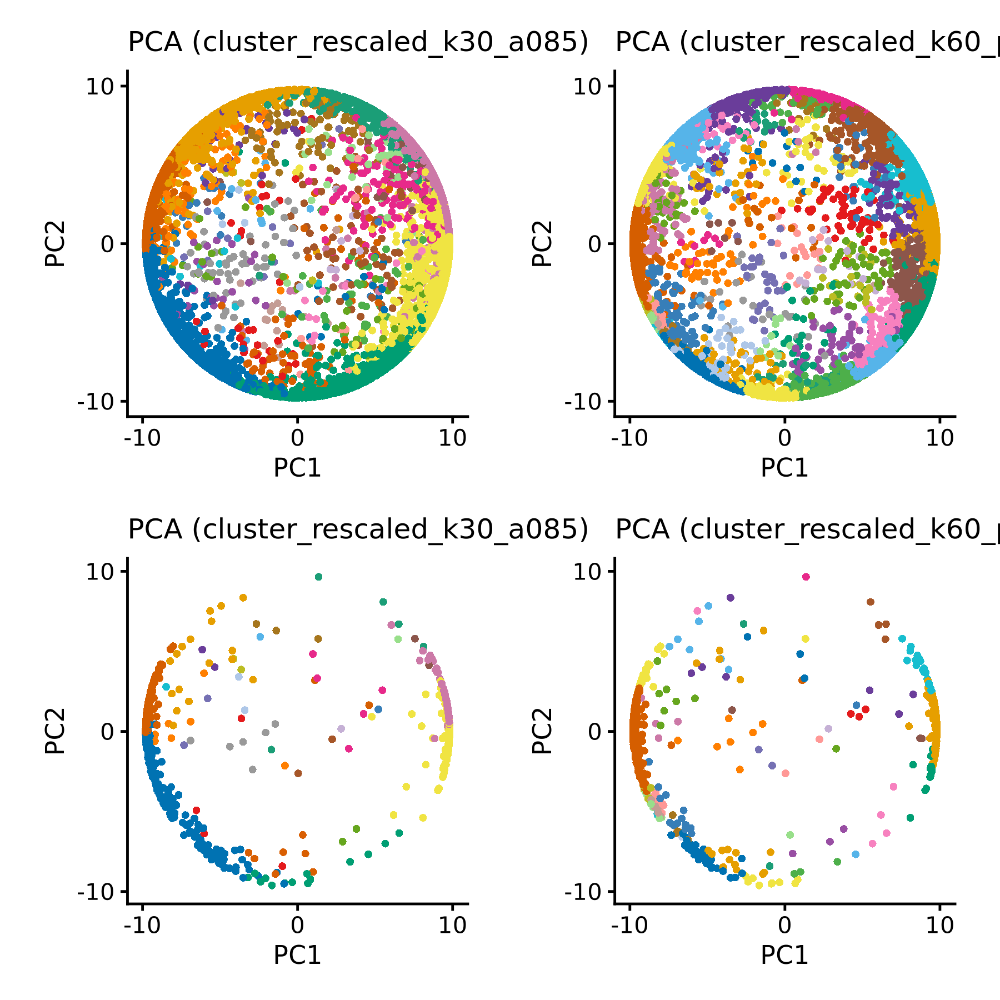

In [1098]:
library(patchwork)

options(repr.plot.width = 6, repr.plot.height = 6)

p1 = feature_plot_pc_simple(pc_df, feature = "cluster_rescaled_k30_a085", cat_colors = c(cat_colors, cat_colors, cat_colors, cat_colors), alpha_col = NULL, plot_order = 'plot_highest_last', show_legend = FALSE)
p2 = feature_plot_pc_simple(pc_df, feature = "cluster_rescaled_k60_pc3", cat_colors = c(cat_colors, cat_colors, cat_colors, cat_colors), alpha_col = NULL, plot_order = 'plot_highest_last', show_legend = FALSE)

p3 = feature_plot_pc_simple(pc_df_subset, feature = "cluster_rescaled_k30_a085", cat_colors = c(cat_colors, cat_colors, cat_colors, cat_colors), plot_order = 'plot_highest_last', show_legend = FALSE)
p4 = feature_plot_pc_simple(pc_df_subset, feature = "cluster_rescaled_k60_pc3", cat_colors = c(cat_colors, cat_colors, cat_colors, cat_colors), plot_order = 'plot_highest_last', show_legend = FALSE)

(p1 + p2)/(p3 + p4)

Warning message in feature_plot_pc_simple(pc_df, feature = "broad_cluster", cat_colors = cat_colors, :
"plot_order based on feature magnitude is only applied for numeric features."
Warning message in feature_plot_pc_simple(pc_df_subset, feature = "broad_cluster", :
"plot_order based on feature magnitude is only applied for numeric features."
Warning message in feature_plot_pc_simple(pc_df, feature = "broad_cluster_v2", cat_colors = cat_colors, :
"plot_order based on feature magnitude is only applied for numeric features."
Warning message in feature_plot_pc_simple(pc_df_subset, feature = "broad_cluster_v2", :
"plot_order based on feature magnitude is only applied for numeric features."



down_then_up   impulse_up        other   trend_down     trend_up 
           8          108           37          206          327 

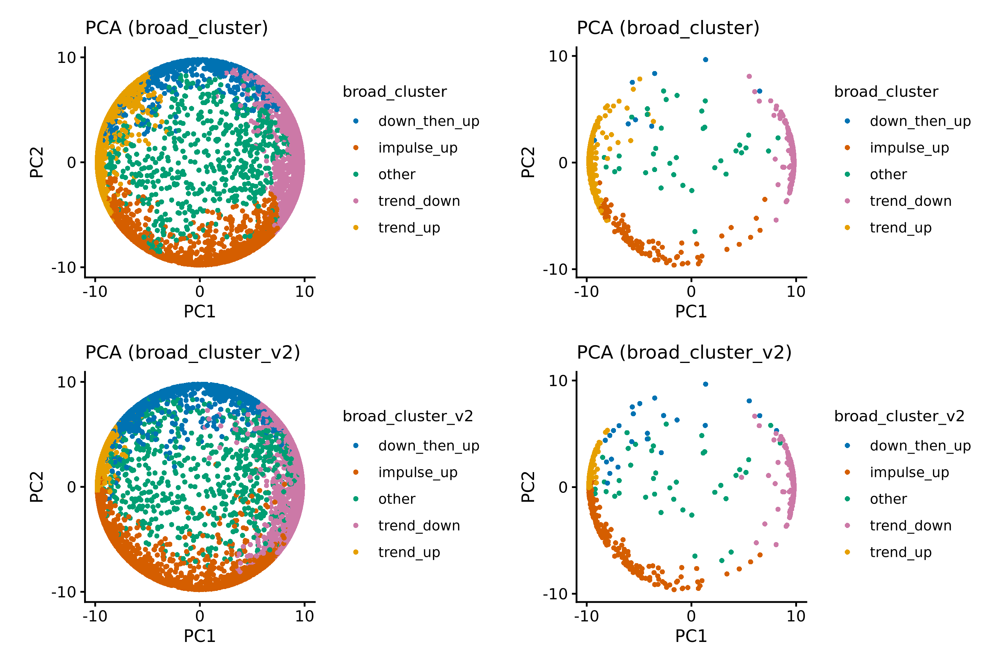

In [1099]:
p1 = feature_plot_pc_simple(pc_df, feature = "broad_cluster", cat_colors = cat_colors, alpha_col = NULL, plot_order = 'plot_highest_last', show_legend = TRUE)
p2 = feature_plot_pc_simple(pc_df_subset, feature = "broad_cluster", cat_colors = cat_colors, alpha_col = NULL, plot_order = 'plot_highest_last', show_legend = TRUE)

p3 = feature_plot_pc_simple(pc_df, feature = "broad_cluster_v2", cat_colors = cat_colors, alpha_col = NULL, plot_order = 'plot_highest_last', show_legend = TRUE)
p4 = feature_plot_pc_simple(pc_df_subset, feature = "broad_cluster_v2", cat_colors = cat_colors, alpha_col = NULL, plot_order = 'plot_highest_last', show_legend = TRUE)

options(repr.plot.width = 9, repr.plot.height = 6)

(p1 + p2)/(p3 + p4)

table(pc_df_subset$broad_cluster)

In [1100]:
pc_df_subset <- pc_df %>% rownames_to_column('rn') %>% filter(abs(peak_log2fc) >= 0.5) %>% dplyr::group_by(cell_type) %>% 
                      dplyr::slice_max(order_by = waldStat_1, n = 100, with_ties = FALSE) %>% 
                      dplyr::ungroup() %>% as.data.frame() %>% column_to_rownames('rn')

round(table(pc_df_subset$broad_cluster, pc_df_subset$cell_type)/100, 2)

              
               K562_puro K562a K562b THP1
  down_then_up      0.01  0.01  0.00 0.00
  impulse_up        0.07  0.21  0.18 0.26
  other             0.07  0.03  0.01 0.00
  trend_down        0.22  0.07  0.28 0.17
  trend_up          0.63  0.29  0.53 0.57

In [1101]:
pc_df_subset <- pc_df %>% rownames_to_column('rn') %>% filter(abs(peak_log2fc) >= 0.5) %>% dplyr::group_by(cell_type) %>% 
                      dplyr::slice_max(order_by = waldStat_1, n = 300, with_ties = FALSE) %>% 
                      dplyr::ungroup() %>% as.data.frame() %>% column_to_rownames('rn')

round(table(pc_df_subset$broad_cluster, pc_df_subset$cell_type)/300, 2)

              
               K562_puro K562a K562b THP1
  down_then_up      0.01  0.00  0.00 0.01
  impulse_up        0.03  0.07  0.10 0.16
  other             0.07  0.01  0.03 0.01
  trend_down        0.15  0.02  0.16 0.35
  trend_up          0.24  0.10  0.28 0.47

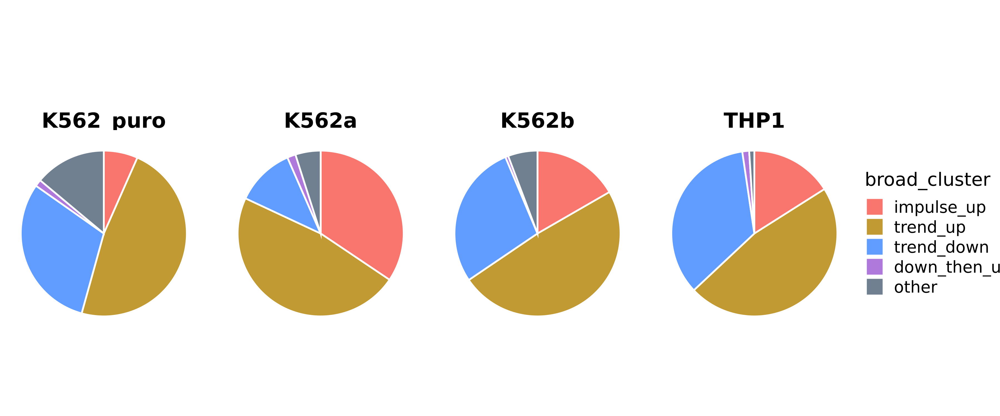

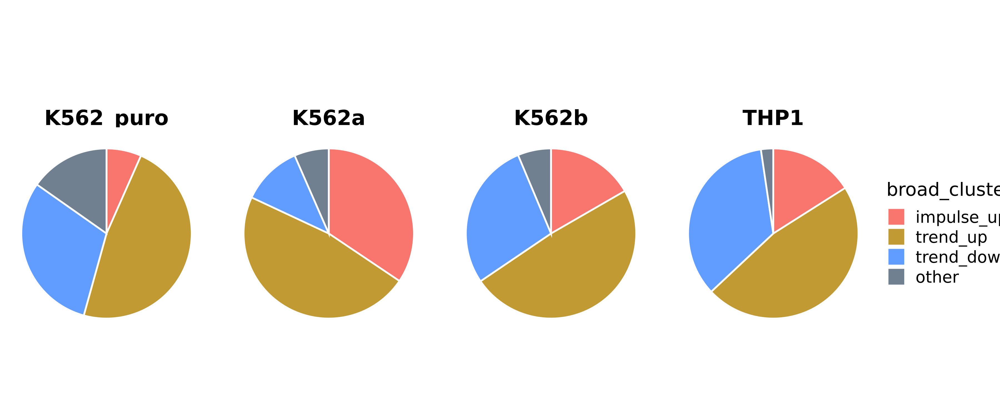

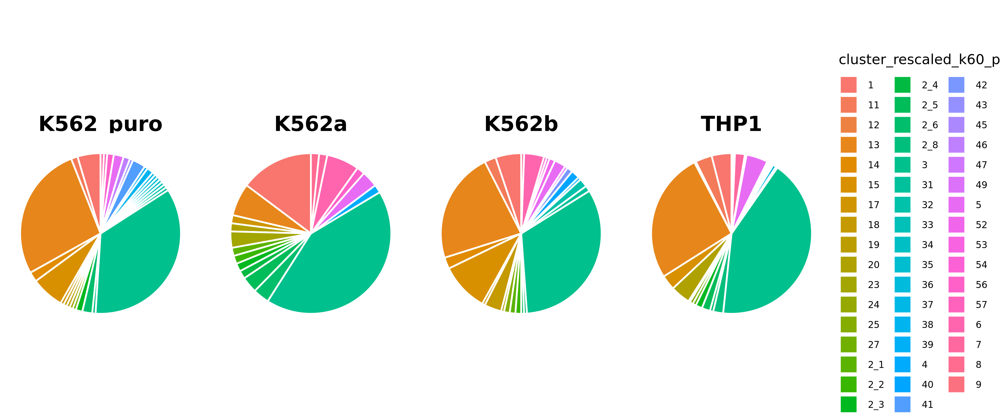

In [1102]:
options(repr.plot.width = 12, repr.plot.height = 5)

cluster_order <- c(
  "impulse_up",
  "trend_up",
  "trend_down",
  "down_then_up",
  "other"
)

pie_df <- pc_df_subset %>%
  mutate(
    broad_cluster = factor(broad_cluster, levels = cluster_order)
  ) %>%
  dplyr::count(cell_type, broad_cluster, .drop = FALSE) %>%
  group_by(cell_type) %>%
  mutate(prop = n / sum(n)) %>%
  ungroup()

ggplot(pie_df, aes(x = "", y = prop, fill = broad_cluster)) +
  geom_col(width = 1, color = "white") +
  coord_polar(theta = "y", direction = -1) +
  facet_wrap(~cell_type, nrow = 1) +
  theme_void(base_size = 16) +
  theme(
    strip.text = element_text(face = "bold", size = 18),
    plot.title = element_text(hjust = 0.5, size = 20),
    legend.title = element_text(size = 16),
    legend.text = element_text(size = 14)
  ) +
  labs(
    title = "",
    fill = "broad_cluster"
  ) +
  scale_fill_manual(
    breaks = cluster_order,
    drop = FALSE,
    values = c(
      impulse_up     = "#F8766D",
      trend_up   = "#C29A33",
      trend_down = "#619CFF",
      down_then_up   = "#AF78DB",
      other          = "#708090"
    )
  )

cluster_order <- c(
  "impulse_up",
  "trend_up",
  "trend_down",
  "other"
)

RenameCluster = function(x) {
    if (x == 'down_then_up') { return('other') }
    return (paste0(x))
}

pie_df <- pc_df_subset %>%
  mutate(
    broad_cluster = vapply(as.character(broad_cluster), RenameCluster, character(1)),
    broad_cluster = factor(broad_cluster, levels = cluster_order)
  ) %>%
  dplyr::count(cell_type, broad_cluster, .drop = FALSE) %>%
  group_by(cell_type) %>%
  mutate(prop = n / sum(n)) %>%
  ungroup()

ggplot(pie_df, aes(x = "", y = prop, fill = broad_cluster)) +
  geom_col(width = 1, color = "white") +
  coord_polar(theta = "y", direction = -1) +
  facet_wrap(~cell_type, nrow = 1) +
  theme_void(base_size = 16) +
  theme(
    strip.text = element_text(face = "bold", size = 18),
    plot.title = element_text(hjust = 0.5, size = 20),
    legend.title = element_text(size = 16),
    legend.text = element_text(size = 14)
  ) +
  labs(
    title = "",
    fill = "broad_cluster"
  ) +
  scale_fill_manual(
    breaks = cluster_order,
    drop = FALSE,
    values = c(
      impulse_up     = "#F8766D",
      trend_up   = "#C29A33",
      trend_down = "#619CFF",
      down_then_up   = "#AF78DB",
      other          = "#708090"
    )
  )

pie_df <- pc_df_subset %>%
  dplyr::count(cell_type, cluster_rescaled_k60_pc3) %>%
  group_by(cell_type) %>%
  mutate(prop = n / sum(n)) %>%
  ungroup()

p = ggplot(pie_df, aes(x = "", y = prop, fill = cluster_rescaled_k60_pc3)) +
  geom_col(width = 1, color = "white") +
  coord_polar(theta = "y") +
  facet_wrap(~cell_type, nrow = 1) +
  theme_void(base_size = 16) +
  theme(
    strip.text = element_text(face = "bold", size = 18),
    plot.title = element_text(hjust = 0.5, size = 20),
    legend.title = element_text(size = 12),
    legend.text = element_text(size = 8)
  ) +
  labs(
    title = "",
    fill = "cluster_rescaled_k60_pc3"
  )

p

[1] "TNF_K562_puro" "TNF_K562a"     "TNF_K562b"     "TNF_THP1"     


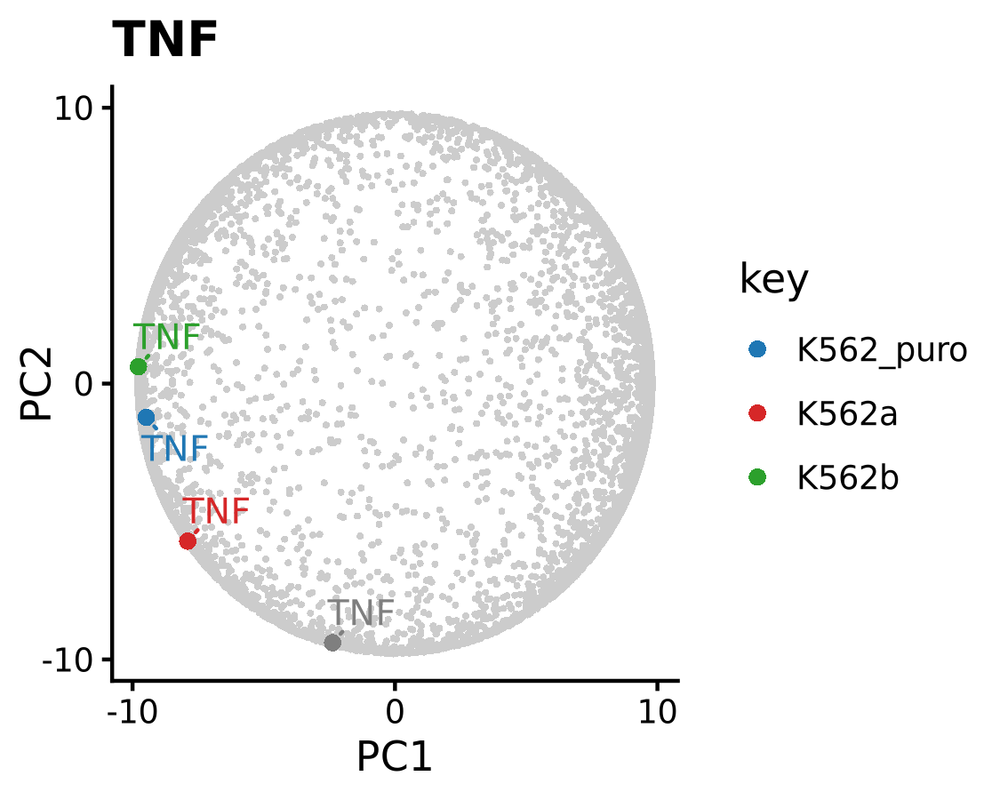

In [1103]:
query_gene = 'TNF'

res1 = PlotGeneKeyHighlight(query_gene, pc_df, width = 3.75, height = 3)

In [216]:
plot_cluster_reassignment_sankey <- function(
  pc_df,
  source_cell_type = "K562a",
  target_cell_type = "THP1",
  cluster_col = "cluster",
  gene_col = "gene",
  rank_col = "waldStat_1",
  top_k = 300,
  rank_desc = TRUE,
  clusters_use = c(1, 2, 3, 4, 9),
  min_flow = 1,
  stratum_gap = NULL,
  stratum_width = 0.28,
  show_legend = FALSE,
  cluster_palette = NULL,

  # Missing-assignment handling
  low_significance_label = "low_significance",
  low_significance_col = "grey80",
  treat_missing_as_low_significance = FALSE,

  title = NULL,
  subtitle = NULL,
  base_size = 13
) {
  stopifnot(is.data.frame(pc_df))
  stopifnot(all(c("cell_type", cluster_col, gene_col, rank_col) %in% colnames(pc_df)))

  arrange_by_rank <- function(df, rank_var) {
    if (isTRUE(rank_desc)) {
      dplyr::arrange(df, dplyr::desc(.data[[rank_var]]))
    } else {
      dplyr::arrange(df, .data[[rank_var]])
    }
  }

  get_gene_annotations <- function(df, cell_type_value, cluster_name, rank_name) {
    out <- df %>%
      dplyr::filter(.data$cell_type == cell_type_value) %>%
      dplyr::transmute(
        gene = as.character(.data[[gene_col]]),
        cluster = as.character(.data[[cluster_col]]),
        rank_val = .data[[rank_col]]
      ) %>%
      dplyr::filter(!is.na(.data$rank_val), is.finite(.data$rank_val))

    out <- arrange_by_rank(out, "rank_val")

    out %>%
      dplyr::distinct(.data$gene, .keep_all = TRUE) %>%
      dplyr::rename(
        !!cluster_name := .data$cluster,
        !!rank_name := .data$rank_val
      )
  }

  # ----------------------------
  # All per-gene annotations, one row/gene/cell_type
  # ----------------------------
  df_src_all <- get_gene_annotations(
    pc_df,
    cell_type_value = source_cell_type,
    cluster_name = "source_cluster",
    rank_name = "source_rank"
  )

  df_tgt_all <- get_gene_annotations(
    pc_df,
    cell_type_value = target_cell_type,
    cluster_name = "target_cluster",
    rank_name = "target_rank"
  )

  # ----------------------------
  # Cluster universe
  # ----------------------------
  if (is.null(clusters_use)) {
    clusters_chr <- sort(unique(c(
      as.character(df_src_all$source_cluster),
      as.character(df_tgt_all$target_cluster)
    )))
  } else {
    clusters_chr <- as.character(clusters_use)
  }

  # If missing genes are treated as low_significance, make sure that label
  # is considered a valid cluster even if it was not supplied in clusters_use.
  if (isTRUE(treat_missing_as_low_significance) &&
      !(low_significance_label %in% clusters_chr)) {
    clusters_chr <- c(clusters_chr, low_significance_label)
  }

  clusters_chr <- unique(clusters_chr)
  cluster_labels <- clusters_chr

  # ----------------------------
  # Top-k per cell type
  # ----------------------------
  df_src_topk <- df_src_all %>% dplyr::slice_head(n = top_k)
  df_tgt_topk <- df_tgt_all %>% dplyr::slice_head(n = top_k)

  # Union of top-k genes from both cell types
  union_genes <- union(df_src_topk$gene, df_tgt_topk$gene)

  if (length(union_genes) == 0) {
    stop("No genes remain in the union of top-k source and target genes.")
  }

  # ----------------------------
  # Map union genes using full source/target annotations
  # ----------------------------
  source_map <- df_src_all %>%
    dplyr::filter(.data$gene %in% union_genes)

  target_map <- df_tgt_all %>%
    dplyr::filter(.data$gene %in% union_genes)

  flow_genes_pre <- data.frame(
    gene = union_genes,
    stringsAsFactors = FALSE,
    check.names = FALSE
  ) %>%
    dplyr::left_join(source_map, by = "gene") %>%
    dplyr::left_join(target_map, by = "gene") %>%
    dplyr::mutate(
      missing_source_assignment = is.na(.data$source_cluster),
      missing_target_assignment = is.na(.data$target_cluster)
    )

  genes_with_missing_assignments <- unique(
    flow_genes_pre$gene[
      flow_genes_pre$missing_source_assignment |
        flow_genes_pre$missing_target_assignment
    ]
  )

  imputed_missing_assignments_df <- dplyr::bind_rows(
    flow_genes_pre %>%
      dplyr::filter(.data$missing_source_assignment) %>%
      dplyr::transmute(
        gene = .data$gene,
        cell_type = source_cell_type,
        side = "source",
        imputed_cluster = low_significance_label
      ),
    flow_genes_pre %>%
      dplyr::filter(.data$missing_target_assignment) %>%
      dplyr::transmute(
        gene = .data$gene,
        cell_type = target_cell_type,
        side = "target",
        imputed_cluster = low_significance_label
      )
  )

  if (isTRUE(treat_missing_as_low_significance)) {
    flow_genes_pre$source_cluster[
      flow_genes_pre$missing_source_assignment
    ] <- low_significance_label

    flow_genes_pre$target_cluster[
      flow_genes_pre$missing_target_assignment
    ] <- low_significance_label
  }

  keep_valid <- with(
    flow_genes_pre,
    !is.na(source_cluster) &
      !is.na(target_cluster) &
      source_cluster %in% clusters_chr &
      target_cluster %in% clusters_chr
  )

  if (isTRUE(treat_missing_as_low_significance)) {
    dropped_incomplete_genes <- character(0)
  } else {
    dropped_incomplete_genes <- genes_with_missing_assignments
  }

  dropped_invalid_cluster_genes <- setdiff(
    flow_genes_pre$gene[!keep_valid],
    dropped_incomplete_genes
  )

  flow_genes <- flow_genes_pre %>%
    dplyr::filter(keep_valid)

  if (nrow(flow_genes) == 0) {
    if (isTRUE(treat_missing_as_low_significance)) {
      stop("No union top-k genes remain after imputing missing assignments as low_significance and filtering clusters_use.")
    } else {
      stop("No union top-k genes remain after matching to both cell types and filtering clusters_use.")
    }
  }

  # ----------------------------
  # All cluster-pair counts before applying min_flow
  # ----------------------------
  flow_df_all <- flow_genes %>%
    dplyr::count(.data$source_cluster, .data$target_cluster, name = "n") %>%
    dplyr::arrange(.data$source_cluster, .data$target_cluster)

  # Visible flows only
  flow_df <- flow_df_all %>%
    dplyr::filter(.data$n >= min_flow) %>%
    dplyr::arrange(.data$source_cluster, .data$target_cluster)

  # ----------------------------
  # Palette
  # ----------------------------
  if (is.null(cluster_palette)) {
    pal_vals <- grDevices::hcl.colors(length(cluster_labels), palette = "Dark 3")
    cluster_palette <- stats::setNames(pal_vals, cluster_labels)

    if (low_significance_label %in% names(cluster_palette)) {
      cluster_palette[low_significance_label] <- low_significance_col
    }
  } else {
    if (is.list(cluster_palette)) {
      cluster_palette <- unlist(cluster_palette)
    }

    missing_palette_clusters <- setdiff(cluster_labels, names(cluster_palette))

    if (length(missing_palette_clusters) > 0) {
      if (all(missing_palette_clusters %in% low_significance_label)) {
        cluster_palette <- c(
          cluster_palette,
          stats::setNames(low_significance_col, low_significance_label)
        )
      } else {
        stop("cluster_palette must be a named vector with names matching as.character(clusters_use).")
      }
    }

    cluster_palette <- cluster_palette[cluster_labels]
  }

  # ----------------------------
  # Spacer strata
  # Use all pair counts before min_flow so empty-box sizing
  # behaves sensibly even if no visible flows remain.
  # ----------------------------
  side_totals <- c(
    flow_df_all %>%
      dplyr::count(.data$source_cluster, wt = .data$n, name = "tot") %>%
      dplyr::pull(.data$tot),
    flow_df_all %>%
      dplyr::count(.data$target_cluster, wt = .data$n, name = "tot") %>%
      dplyr::pull(.data$tot)
  )

  if (is.null(stratum_gap)) {
    stratum_gap <- max(0.015 * max(side_totals), 0.6)
  }

  if (length(cluster_labels) > 1) {
    gap_labels <- paste0(".gap", seq_len(length(cluster_labels) - 1))
    axis_levels <- c(
      rbind(cluster_labels[-length(cluster_labels)], gap_labels),
      tail(cluster_labels, 1)
    )
    axis_levels <- as.character(axis_levels)

    gap_df <- data.frame(
      source_cluster = gap_labels,
      target_cluster = gap_labels,
      n = stratum_gap,
      stringsAsFactors = FALSE
    )
  } else {
    gap_labels  <- character(0)
    axis_levels <- cluster_labels
    gap_df      <- flow_df_all[0, c("source_cluster", "target_cluster", "n")]
  }

  # ----------------------------
  # Add invisible dummy rows so clusters with no visible
  # source/target flow still get a stratum box
  # ----------------------------
  visible_source_clusters <- unique(as.character(flow_df$source_cluster))
  visible_target_clusters <- unique(as.character(flow_df$target_cluster))

  missing_source_clusters <- setdiff(cluster_labels, visible_source_clusters)
  missing_target_clusters <- setdiff(cluster_labels, visible_target_clusters)

  empty_box_size <- max(0.15, 0.25 * stratum_gap)

  dummy_source_df <- if (length(missing_source_clusters) > 0) {
    data.frame(
      source_cluster = missing_source_clusters,
      target_cluster = if (length(gap_labels) > 0) gap_labels[1] else missing_source_clusters,
      n = empty_box_size,
      stringsAsFactors = FALSE
    )
  } else {
    flow_df_all[0, c("source_cluster", "target_cluster", "n")]
  }

  dummy_target_df <- if (length(missing_target_clusters) > 0) {
    data.frame(
      source_cluster = if (length(gap_labels) > 0) tail(gap_labels, 1) else missing_target_clusters,
      target_cluster = missing_target_clusters,
      n = empty_box_size,
      stringsAsFactors = FALSE
    )
  } else {
    flow_df_all[0, c("source_cluster", "target_cluster", "n")]
  }

  plot_df <- dplyr::bind_rows(
    flow_df %>% dplyr::mutate(row_type = "flow"),
    gap_df %>% dplyr::mutate(row_type = "gap"),
    dummy_source_df %>% dplyr::mutate(row_type = "dummy"),
    dummy_target_df %>% dplyr::mutate(row_type = "dummy")
  ) %>%
    dplyr::mutate(
      source_cluster = factor(.data$source_cluster, levels = axis_levels),
      target_cluster = factor(.data$target_cluster, levels = axis_levels),
      source_id = factor(
        paste0("src__", as.character(.data$source_cluster)),
        levels = paste0("src__", axis_levels)
      ),
      target_id = factor(
        paste0("tgt__", as.character(.data$target_cluster)),
        levels = paste0("tgt__", axis_levels)
      ),
      flow_alpha = dplyr::case_when(
        .data$row_type == "flow"  ~ 0.65,
        .data$row_type == "gap"   ~ 0,
        .data$row_type == "dummy" ~ 0,
        TRUE ~ 0
      )
    )

  # ----------------------------
  # Stratum geometry
  # ----------------------------
  p_tmp <- ggplot2::ggplot(
    plot_df,
    ggplot2::aes(axis1 = source_id, axis2 = target_id, y = n)
  ) +
    ggalluvial::geom_stratum(width = stratum_width)

  gb <- ggplot2::ggplot_build(p_tmp)

  stratum_df <- gb$data[[1]] %>%
    dplyr::transmute(
      xmin = .data$xmin,
      xmax = .data$xmax,
      ymin = .data$ymin,
      ymax = .data$ymax,
      stratum_raw = as.character(.data$stratum)
    ) %>%
    dplyr::filter(!grepl("^(src__|tgt__)\\.gap", .data$stratum_raw)) %>%
    dplyr::mutate(
      side = dplyr::if_else(grepl("^src__", .data$stratum_raw), "source", "target"),
      cluster = sub("^(src__|tgt__)", "", .data$stratum_raw),
      x = (.data$xmin + .data$xmax) / 2,
      y = (.data$ymin + .data$ymax) / 2
    )

  n_src_topk <- nrow(df_src_topk)
  n_tgt_topk <- nrow(df_tgt_topk)
  n_union    <- length(union_genes)
  n_mapped   <- nrow(flow_genes)
  n_imputed_assignments <- if (isTRUE(treat_missing_as_low_significance)) {
    nrow(imputed_missing_assignments_df)
  } else {
    0L
  }

  if (is.null(title)) {
    title <- paste0(source_cell_type, " \u2192 ", target_cell_type, " mode reassignments")
  }


  subtitle <- paste0("Union of top ", top_k, " genes = ", scales::comma(n_union))

  p <- ggplot2::ggplot(
    plot_df,
    ggplot2::aes(axis1 = source_id, axis2 = target_id, y = n)
  ) +
    ggalluvial::geom_alluvium(
      ggplot2::aes(alpha = flow_alpha),
      fill = "grey70",
      width = stratum_width,
      knot.pos = 0.42,
      color = NA,
      show.legend = FALSE
    ) +
    ggplot2::scale_alpha_identity() +
    ggplot2::geom_rect(
      data = stratum_df,
      ggplot2::aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, fill = cluster),
      inherit.aes = FALSE,
      color = "grey25",
      linewidth = 0.6
    ) +
    ggplot2::scale_x_discrete(
      limits = c(source_cell_type, target_cell_type),
      expand = c(0.08, 0.08)
    ) +
    ggplot2::scale_fill_manual(
      values = cluster_palette,
      breaks = cluster_labels,
      drop = FALSE
    ) +
    ggplot2::labs(
      title = title,
      subtitle = subtitle,
      x = NULL,
      y = NULL,
      fill = "Cluster"
    ) +
    ggplot2::theme_classic(base_size = base_size) +
    ggplot2::theme(
      legend.position = if (show_legend) "right" else "none",
      axis.line.x = ggplot2::element_blank(),
      axis.ticks.x = ggplot2::element_blank(),
      axis.line.y = ggplot2::element_blank(),
      axis.ticks.y = ggplot2::element_blank(),
      axis.text.y = ggplot2::element_blank(),
      axis.title.y = ggplot2::element_blank(),
      plot.title.position = "plot",
      plot.margin = ggplot2::margin(8, 12, 8, 8)
    )

  invisible(list(
    plot = p,
    flow_df = flow_df,
    flow_df_all = flow_df_all,
    flow_genes = flow_genes,
    flow_genes_pre = flow_genes_pre,
    union_genes = union_genes,
    df_src_topk = df_src_topk,
    df_tgt_topk = df_tgt_topk,
    df_src_all = df_src_all,
    df_tgt_all = df_tgt_all,
    stratum_df = stratum_df,
    stratum_gap = stratum_gap,
    missing_source_clusters = missing_source_clusters,
    missing_target_clusters = missing_target_clusters,
    empty_box_size = empty_box_size,
    genes_with_missing_assignments = genes_with_missing_assignments,
    imputed_missing_assignments_df = imputed_missing_assignments_df,
    dropped_incomplete_genes = dropped_incomplete_genes,
    dropped_invalid_cluster_genes = dropped_invalid_cluster_genes,
    low_significance_label = low_significance_label,
    treat_missing_as_low_significance = treat_missing_as_low_significance
  ))
}

In [1105]:
table(pc_df_subset$cell_type)


K562_puro     K562a     K562b      THP1 
      151        61       174       300 

In [213]:
pc_df_subset <- pc_df %>% rownames_to_column('rn') %>% 
                          # filter(abs(peak_log2fc) > 0.5) %>% 
                          dplyr::group_by(cell_type) %>% 
                          dplyr::slice_max(order_by = waldStat_1, n = 300, with_ties = FALSE) %>% 
                          dplyr::ungroup() %>% as.data.frame() %>% column_to_rownames('rn')

In [214]:
dim(pc_df_subset)

[1] 1200   32

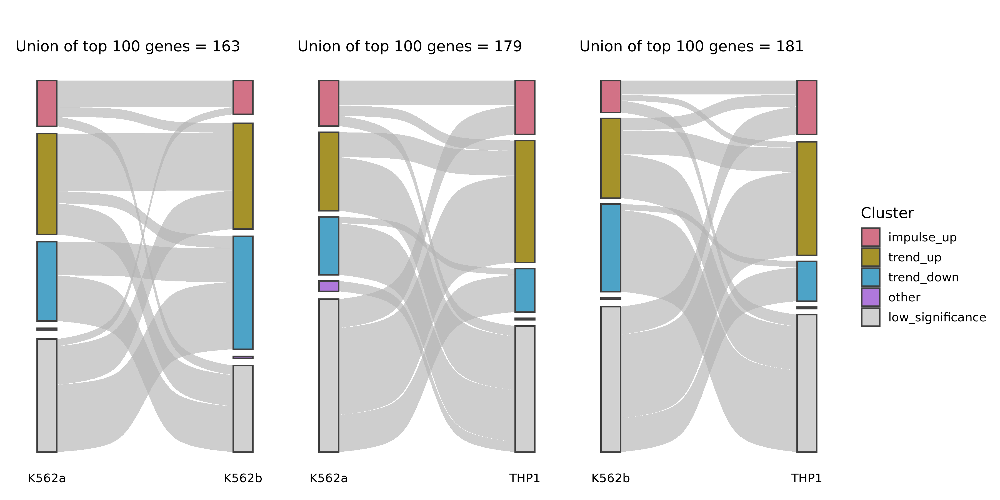

In [1202]:
p1 = (plot_cluster_reassignment_sankey(pc_df = pc_df_subset, top_k = 100,
                                           source_cell_type = "K562a", target_cell_type = "K562b", treat_missing_as_low_significance = TRUE,
                                           cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
                                           clusters_use = c("impulse_up", "trend_up", "trend_down", "other", "low_significance"),
                                           min_flow = 3, stratum_gap = 3, stratum_width = 0.10,
                                           cluster_palette = list(impulse_up = '#D27286', trend_up = '#A5922A', trend_down = '#4DA3C7', other = '#AF78DB', low_significance = '#D1D1D1'),
                                           show_legend = FALSE))$plot + ggtitle('')

p2 = (plot_cluster_reassignment_sankey(pc_df = pc_df_subset, top_k = 100,
                                           source_cell_type = "K562a", target_cell_type = "THP1", treat_missing_as_low_significance = TRUE,
                                           cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
                                           clusters_use = c("impulse_up", "trend_up", "trend_down", "other", "low_significance"),
                                           min_flow = 3, stratum_gap = 3, stratum_width = 0.10,
                                           cluster_palette = list(impulse_up = '#D27286', trend_up = '#A5922A', trend_down = '#4DA3C7', other = '#AF78DB', low_significance = '#D1D1D1'),
                                           show_legend = FALSE))$plot + ggtitle('')

p3 = (plot_cluster_reassignment_sankey(pc_df = pc_df_subset, top_k = 100,
                                           source_cell_type = "K562b", target_cell_type = "THP1", treat_missing_as_low_significance = TRUE,
                                           cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
                                           clusters_use = c("impulse_up", "trend_up", "trend_down", "other", "low_significance"),
                                           min_flow = 3, stratum_gap = 3, stratum_width = 0.10,
                                           cluster_palette = list(impulse_up = '#D27286', trend_up = '#A5922A', trend_down = '#4DA3C7', other = '#AF78DB', low_significance = '#D1D1D1'),
                                           show_legend = TRUE))$plot + ggtitle('')

options(repr.plot.width = 12, repr.plot.height = 6)
p1 + p2 + p3

In [218]:
tmp = (plot_cluster_reassignment_sankey(pc_df = pc_df_subset, top_k = 100,
                                           source_cell_type = "K562a", target_cell_type = "THP1", treat_missing_as_low_significance = TRUE,
                                           cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
                                           clusters_use = c("impulse_up", "trend_up", "trend_down", "other", "low_significance"),
                                           min_flow = 3, stratum_gap = 3, stratum_width = 0.10,
                                           cluster_palette = list(impulse_up = '#D27286', trend_up = '#A5922A', trend_down = '#4DA3C7', other = '#AF78DB', low_significance = '#D1D1D1'),
                                           show_legend = FALSE))

src_to_tgt <- tmp$flow_df_all %>%
  filter(source_cluster != "low_significance") %>%
  group_by(broad_cluster = source_cluster) %>%
  summarise(
    pct_source_to_target =
      100 * sum(n[source_cluster == target_cluster]) / sum(n)
  )

tgt_to_src <- tmp$flow_df_all %>%
  filter(target_cluster != "low_significance") %>%
  group_by(broad_cluster = target_cluster) %>%
  summarise(
    pct_target_to_source =
      100 * sum(n[source_cluster == target_cluster]) / sum(n)
  )

full_join(src_to_tgt, tgt_to_src, by = "broad_cluster") %>%
  mutate(
    pct_conserved = rowMeans(
      across(c(pct_source_to_target, pct_target_to_source)),
      na.rm = TRUE
    )
  )

broad_cluster,pct_source_to_target,pct_target_to_source,pct_conserved
<chr>,<dbl>,<dbl>,<dbl>
impulse_up,52.17391,42.85714,47.51553
other,0.00000,NA,0.00000
trend_down,10.34483,13.63636,11.99060
trend_up,30.00000,20.00000,25.00000


In [221]:
0.47*30

[1] 14.1

In [1204]:
# K562a <--> K562b
# induced modes are 50-60% conserved (30-50% @ n=300)
# repression is 30-40% (10-20% @ n=300)

# K562a <--> THP1
# induced modes are 20-50% conserved (20-30% for trend_up, 40-50% for impulse_up) (10-30% @ n=300)
# repression is 10-15% (3% @ n=300)

[1] 1200   32

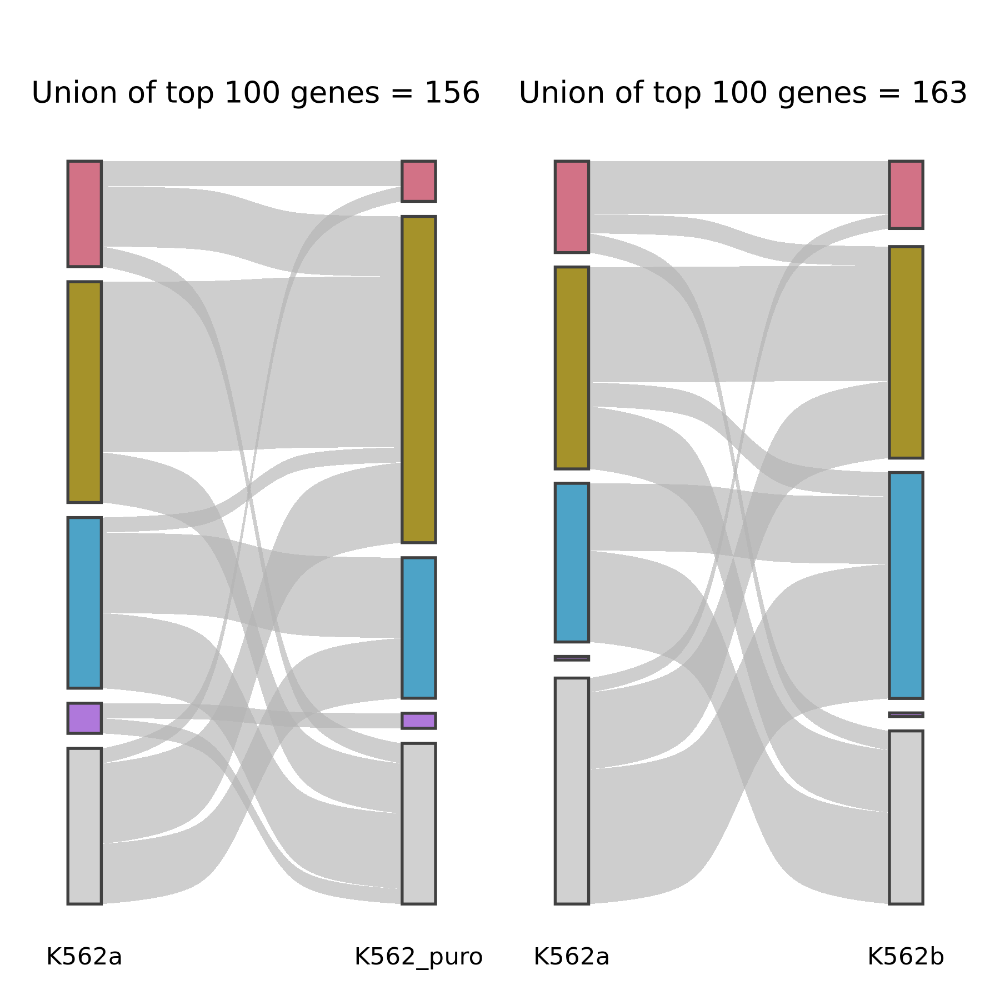

In [1209]:
p1 = (plot_cluster_reassignment_sankey(pc_df = pc_df_subset, top_k = 100,
                                           source_cell_type = "K562a", target_cell_type = "K562_puro", treat_missing_as_low_significance = TRUE,
                                           cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
                                           clusters_use = c("impulse_up", "trend_up", "trend_down", "other", "low_significance"),
                                           min_flow = 3, stratum_gap = 3, stratum_width = 0.10,
                                           cluster_palette = list(impulse_up = '#D27286', trend_up = '#A5922A', trend_down = '#4DA3C7', other = '#AF78DB', low_significance = '#D1D1D1'),
                                           show_legend = FALSE))$plot + ggtitle('')

p2 = (plot_cluster_reassignment_sankey(pc_df = pc_df_subset, top_k = 100,
                                           source_cell_type = "K562a", target_cell_type = "K562b", treat_missing_as_low_significance = TRUE,
                                           cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
                                           clusters_use = c("impulse_up", "trend_up", "trend_down", "other", "low_significance"),
                                           min_flow = 3, stratum_gap = 3, stratum_width = 0.10,
                                           cluster_palette = list(impulse_up = '#D27286', trend_up = '#A5922A', trend_down = '#4DA3C7', other = '#AF78DB', low_significance = '#D1D1D1'),
                                           show_legend = FALSE))$plot + ggtitle('')


options(repr.plot.width = 6, repr.plot.height = 6)
p1 + p2

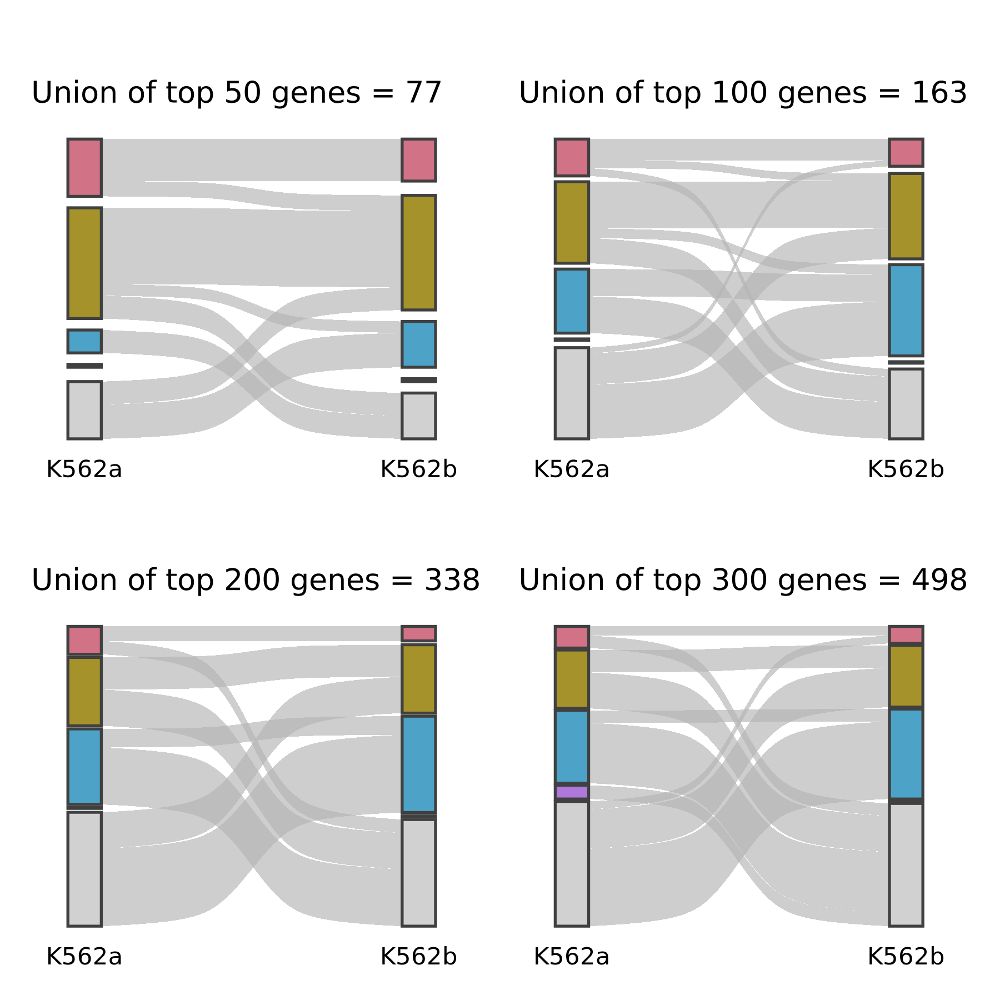

In [1210]:
p1 = (plot_cluster_reassignment_sankey(pc_df = pc_df_subset, top_k = 50,
                                           source_cell_type = "K562a", target_cell_type = "K562b", treat_missing_as_low_significance = TRUE,
                                           cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
                                           clusters_use = c("impulse_up", "trend_up", "trend_down", "other", "low_significance"),
                                           min_flow = 3, stratum_gap = 3, stratum_width = 0.10,
                                           cluster_palette = list(impulse_up = '#D27286', trend_up = '#A5922A', trend_down = '#4DA3C7', other = '#AF78DB', low_significance = '#D1D1D1'),
                                           show_legend = FALSE))$plot + ggtitle('')

p2 = (plot_cluster_reassignment_sankey(pc_df = pc_df_subset, top_k = 100,
                                           source_cell_type = "K562a", target_cell_type = "K562b", treat_missing_as_low_significance = TRUE,
                                           cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
                                           clusters_use = c("impulse_up", "trend_up", "trend_down", "other", "low_significance"),
                                           min_flow = 3, stratum_gap = 3, stratum_width = 0.10,
                                           cluster_palette = list(impulse_up = '#D27286', trend_up = '#A5922A', trend_down = '#4DA3C7', other = '#AF78DB', low_significance = '#D1D1D1'),
                                           show_legend = FALSE))$plot + ggtitle('')

p3 = (plot_cluster_reassignment_sankey(pc_df = pc_df_subset, top_k = 200,
                                           source_cell_type = "K562a", target_cell_type = "K562b", treat_missing_as_low_significance = TRUE,
                                           cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
                                           clusters_use = c("impulse_up", "trend_up", "trend_down", "other", "low_significance"),
                                           min_flow = 10, stratum_gap = 3, stratum_width = 0.10,
                                           cluster_palette = list(impulse_up = '#D27286', trend_up = '#A5922A', trend_down = '#4DA3C7', other = '#AF78DB', low_significance = '#D1D1D1'),
                                           show_legend = FALSE))$plot + ggtitle('')

p4 = (plot_cluster_reassignment_sankey(pc_df = pc_df_subset, top_k = 300,
                                           source_cell_type = "K562a", target_cell_type = "K562b", treat_missing_as_low_significance = TRUE,
                                           cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
                                           clusters_use = c("impulse_up", "trend_up", "trend_down", "other", "low_significance"),
                                           min_flow = 10, stratum_gap = 3, stratum_width = 0.10,
                                           cluster_palette = list(impulse_up = '#D27286', trend_up = '#A5922A', trend_down = '#4DA3C7', other = '#AF78DB', low_significance = '#D1D1D1'),
                                           show_legend = FALSE))$plot + ggtitle('')



options(repr.plot.width = 6, repr.plot.height = 6)
(p1 + p2) / (p3 + p4)

In [1114]:
# saveRDS(pc_df, 'pc_df.rds')

In [1115]:
plot_cluster_pair_representative_genes <- function(
  pc_df,
  cluster_list = c(1, 2),
  row_cell_type = "K562a",
  col_cell_type = "THP1",
  cluster_col = "cluster",
  gamList_ls, sce_ls, counts_sub_ls, PT_ls, sf_ls,
  CW_ls = NULL,
  colours = c(THP1 = "#222021", K562a = "#386cb0"),
  cluster_palette = NULL,
  rank_by = c("row", "col", "sum", "min"),
  qval_cut = 0.05,
  show_legend = FALSE,
  print_gene_table = TRUE,
  overall_title = NULL,
  border_colour = "grey65",
  border_linewidth = 0.7,
  annotation_box_linewidth = 2.2,
  annotation_box_rel_size = 0.16,
  top_annotation_box_rel_size = 0.24,
  axis_label_rel_size = 0.08,
  gene_title_size = 9,
  label_size = 5.2,
  hide_subplot_axes = TRUE,
  hide_mean_fit_points = FALSE,
  ...
) {
  rank_by <- match.arg(rank_by)

  stopifnot(is.data.frame(pc_df))
  stopifnot(all(c("gene", "cell_type", cluster_col, "waldStat_1", "qval_1") %in% colnames(pc_df)))
  stopifnot(length(cluster_list) >= 1)

  if (is.na(colours[[row_cell_type]]) || is.na(colours[[col_cell_type]])) {
    stop("colours must be a named vector containing both row_cell_type and col_cell_type.")
  }

  row_clusters <- as.character(cluster_list)
  col_clusters <- as.character(cluster_list)
  n_cl <- length(cluster_list)
  cluster_ids <- as.character(unique(cluster_list))

  if (is.null(cluster_palette)) {
    pal_vals <- hcl.colors(length(cluster_ids), palette = "Dark 3")
    cluster_palette <- stats::setNames(pal_vals, cluster_ids)
  } else {
    if (!all(cluster_ids %in% names(cluster_palette))) {
      stop("cluster_palette must be a named vector with names matching as.character(cluster_list).")
    }
    cluster_palette <- cluster_palette[cluster_ids]
  }

  # -----------------------------------
  # prepare shared-gene assignment table
  # -----------------------------------
  df_row <- pc_df %>%
    dplyr::filter(.data$cell_type == row_cell_type) %>%
    dplyr::transmute(
      gene = .data$gene,
      cluster_row = as.character(.data[[cluster_col]]),
      wald_row = .data$waldStat_1,
      qval_row = .data$qval_1
    )

  df_col <- pc_df %>%
    dplyr::filter(.data$cell_type == col_cell_type) %>%
    dplyr::transmute(
      gene = .data$gene,
      cluster_col = as.character(.data[[cluster_col]]),
      wald_col = .data$waldStat_1,
      qval_col = .data$qval_1
    )

  shared_df <- dplyr::inner_join(df_row, df_col, by = "gene") %>%
    dplyr::mutate(
      pass_qval_both = !is.na(.data$qval_row) & !is.na(.data$qval_col) &
        (.data$qval_row < qval_cut) & (.data$qval_col < qval_cut),
      score = dplyr::case_when(
        rank_by == "row" ~ .data$wald_row,
        rank_by == "col" ~ .data$wald_col,
        rank_by == "sum" ~ .data$wald_row + .data$wald_col,
        rank_by == "min" ~ pmin(.data$wald_row, .data$wald_col),
        TRUE ~ .data$wald_row
      )
    )

  # -----------------------------------
  # helpers
  # -----------------------------------
  add_box_theme <- function(p) {
    p +
      theme(
        panel.border = element_rect(
          colour = border_colour,
          fill = NA,
          linewidth = border_linewidth
        ),
        plot.margin = margin(2, 2, 2, 2)
      )
  }

  hide_axes_theme <- theme(
    axis.title = element_blank(),
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    axis.line = element_blank()
  )

  remove_point_layers <- function(p) {
    keep <- vapply(
      p$layers,
      function(lyr) !inherits(lyr$geom, "GeomPoint"),
      logical(1)
    )
    p$layers <- p$layers[keep]
    p
  }

  make_empty_panel <- function() {
    add_box_theme(
      ggplot() +
        xlim(0, 1) + ylim(0, 1) +
        theme_void()
    )
  }

  make_annotation_panel <- function(cluster_id) {
    fill_col <- cluster_palette[[as.character(cluster_id)]]

    ggplot() +
      annotate(
        "rect",
        xmin = 0, xmax = 1, ymin = 0, ymax = 1,
        fill = fill_col,
        colour = fill_col,
        linewidth = annotation_box_linewidth
      ) +
      xlim(0, 1) + ylim(0, 1) +
      theme_void() +
      theme(plot.margin = margin(2, 2, 2, 2))
  }

  make_axis_label_panel <- function(label, angle = 0, face = "bold") {
    ggplot() +
      annotate(
        "text",
        x = 0.5, y = 0.5,
        label = label,
        angle = angle,
        hjust = 0.5,
        vjust = 0.5,
        size = label_size,
        fontface = face
      ) +
      xlim(0, 1) + ylim(0, 1) +
      theme_void() +
      theme(plot.margin = margin(0, 0, 0, 0))
  }

  # -----------------------------------
  # choose representative gene for each cell
  # require qval pass in both cell types
  # -----------------------------------
  chosen_df <- do.call(
    rbind,
    lapply(row_clusters, function(rcl) {
      do.call(
        rbind,
        lapply(col_clusters, function(ccl) {
          cand_all <- shared_df %>%
            dplyr::filter(
              .data$cluster_row == as.character(rcl),
              .data$cluster_col == as.character(ccl)
            )

          cand <- cand_all %>%
            dplyr::filter(.data$pass_qval_both) %>%
            dplyr::arrange(dplyr::desc(.data$score), dplyr::desc(.data$wald_row))

          if (nrow(cand) == 0) {
            data.frame(
              row_cluster = rcl,
              col_cluster = ccl,
              gene = NA_character_,
              wald_row = NA_real_,
              wald_col = NA_real_,
              qval_row = NA_real_,
              qval_col = NA_real_,
              score = NA_real_,
              n_candidates_all = nrow(cand_all),
              n_candidates_qpass = 0L,
              stringsAsFactors = FALSE
            )
          } else {
            data.frame(
              row_cluster = rcl,
              col_cluster = ccl,
              gene = cand$gene[1],
              wald_row = cand$wald_row[1],
              wald_col = cand$wald_col[1],
              qval_row = cand$qval_row[1],
              qval_col = cand$qval_col[1],
              score = cand$score[1],
              n_candidates_all = nrow(cand_all),
              n_candidates_qpass = nrow(cand),
              stringsAsFactors = FALSE
            )
          }
        })
      )
    })
  )

  rownames(chosen_df) <- NULL

  if (print_gene_table) {
    print(chosen_df)
  }

  # -----------------------------------
  # interior plot panels
  # -----------------------------------
  keys_use <- c(row_cell_type, col_cell_type)
  colours_use <- colours[keys_use]

  panel_lookup <- vector("list", nrow(chosen_df))

  for (i in seq_len(nrow(chosen_df))) {
    g <- chosen_df$gene[i]

    if (is.na(g)) {
      panel_lookup[[i]] <- make_empty_panel()
      next
    }

    utils::capture.output({
      p <- suppressMessages(
        suppressWarnings(
          plot_tradeSeq_gene_multirun_pub(
            gamList_ls = gamList_ls,
            sce_ls = sce_ls,
            counts_sub_ls = counts_sub_ls,
            PT_ls = PT_ls,
            sf_ls = sf_ls,
            CW_ls = CW_ls,
            keys = keys_use,
            colours = colours_use,
            key_labels = NULL,
            gene = g,
            show_legend = show_legend,
            ...
          )
        )
      )
    })

    if (isTRUE(hide_mean_fit_points)) {
      p <- remove_point_layers(p)
    }

    p <- p +
      ggtitle(g) +
      theme(
        plot.title = element_text(size = gene_title_size, face = "bold", hjust = 0.5),
        plot.margin = margin(2, 2, 2, 2)
      )

    if (isTRUE(hide_subplot_axes)) {
      p <- p + hide_axes_theme
    }

    panel_lookup[[i]] <- add_box_theme(p)
  }

  # -----------------------------------
  # assemble central grid
  # -----------------------------------
  full_panels <- list()
  full_panels[[1]] <- patchwork::plot_spacer()

  for (ccl in col_clusters) {
    full_panels[[length(full_panels) + 1]] <- make_annotation_panel(ccl)
  }

  idx <- 1
  for (rcl in row_clusters) {
    full_panels[[length(full_panels) + 1]] <- make_annotation_panel(rcl)
    for (ccl in col_clusters) {
      full_panels[[length(full_panels) + 1]] <- panel_lookup[[idx]]
      idx <- idx + 1
    }
  }

  main_grid <- wrap_plots(full_panels, ncol = n_cl + 1, byrow = TRUE) +
    plot_layout(
      widths = c(annotation_box_rel_size, rep(1, n_cl)),
      heights = c(top_annotation_box_rel_size, rep(1, n_cl))
    )

  y_axis_panel <- make_axis_label_panel(
    label = row_cell_type,
    angle = 90
  )

  x_axis_panel <- make_axis_label_panel(
    label = col_cell_type,
    angle = 0
  )

  x_label_row <- wrap_plots(
    list(patchwork::plot_spacer(), x_axis_panel),
    ncol = 2,
    widths = c(axis_label_rel_size, 1)
  )

  grid_row <- wrap_plots(
    list(y_axis_panel, main_grid),
    ncol = 2,
    widths = c(axis_label_rel_size, 1)
  )

  p_out <- x_label_row / grid_row +
    plot_layout(heights = c(axis_label_rel_size, 1))

  if (!is.null(overall_title)) {
    p_out <- p_out + plot_annotation(title = overall_title)
  }

  print(p_out)

  invisible(list(
    plot = p_out,
    chosen_genes = chosen_df,
    shared_df = shared_df,
    cluster_palette = cluster_palette
  ))
}

In [1116]:
table(pc_df$cell_type)


K562_puro     K562a     K562b      THP1 
     4317      3362      3655      3667 

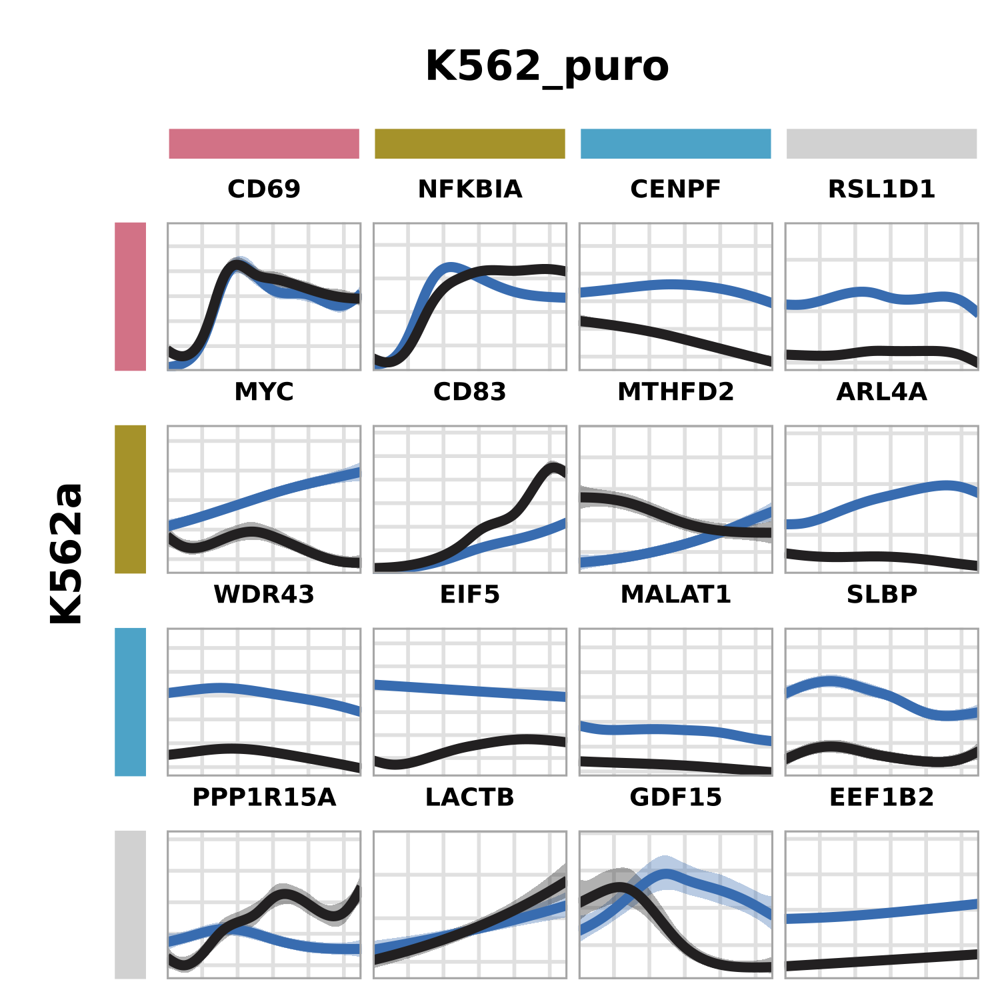

In [1211]:
top_k <- 300  # set this to whatever k you want

keep_ids <- pc_df %>%
  mutate(.row_id = seq_len(n())) %>%
  group_by(cell_type) %>%
  slice_max(order_by = waldStat_1, n = top_k, with_ties = FALSE) %>%
  ungroup() %>%
  pull(.row_id)

pc_df <- pc_df %>%
  mutate(
    .row_id = seq_len(n()),
    broad_cluster2 = if_else(.row_id %in% keep_ids, broad_cluster, "low_significance")
  ) %>%
  select(-.row_id)

options(repr.plot.width = 5, repr.plot.height = 5)

res_conf <- plot_cluster_pair_representative_genes(
  pc_df = pc_df,
  cluster_list = c('impulse_up', 'trend_up', 'trend_down', 'low_significance'),
  row_cell_type = "K562a", col_cell_type = "K562_puro", cluster_col = 'broad_cluster2',
  gamList_ls = gamList.ls, sce_ls = sce.ls,
  counts_sub_ls = counts_sub.ls, PT_ls = PT.ls, sf_ls = sf.ls, CW_ls = CW.ls,
  colours = c(K562_puro = "#222021", K562a = "#386cb0"),
  qval_cut = 1, time_max_map = time_map,
  hide_subplot_axes = TRUE, hide_mean_fit_points = TRUE, omit_points = TRUE, print_gene_table = FALSE,
  cluster_palette = c(impulse_up = "#D27286", trend_up = "#A5922A", trend_down = "#4DA3C7", low_significance = "#D1D1D1"),
  top_annotation_box_rel_size = 0.20)

# ggsave(
#   "cluster_reassignment_genes.pdf",
#   plot = res_conf$plot,
#   width = 5,
#   height = 5,
#   units = "in",
#   dpi = 300,
#   bg = "white"
# )

# ggsave(
#   "cluster_reassignment_genes.png",
#   plot = res_conf$plot,
#   width = 5,
#   height = 5,
#   units = "in",
#   dpi = 300,
#   bg = "white"
# )

In [1118]:
set1 = (pc_df_subset %>% filter(cell_type == 'K562a', broad_cluster == 'impulse_up'))$gene
set2 = (pc_df_subset %>% filter(cell_type == 'K562_puro', broad_cluster == 'trend_up'))$gene
intersect(set1, set2)

[1] "NFKBIA"  "CXCL3"   "CXCL8"   "CXCL1"   "IRF1"    "KLF6"    "JUN"    
 [8] "CXCL2"   "TIFA"    "PIM3"    "GADD45B" "NAB2"

      K562a   K562_puro 
    "K562a" "K562_puro" 


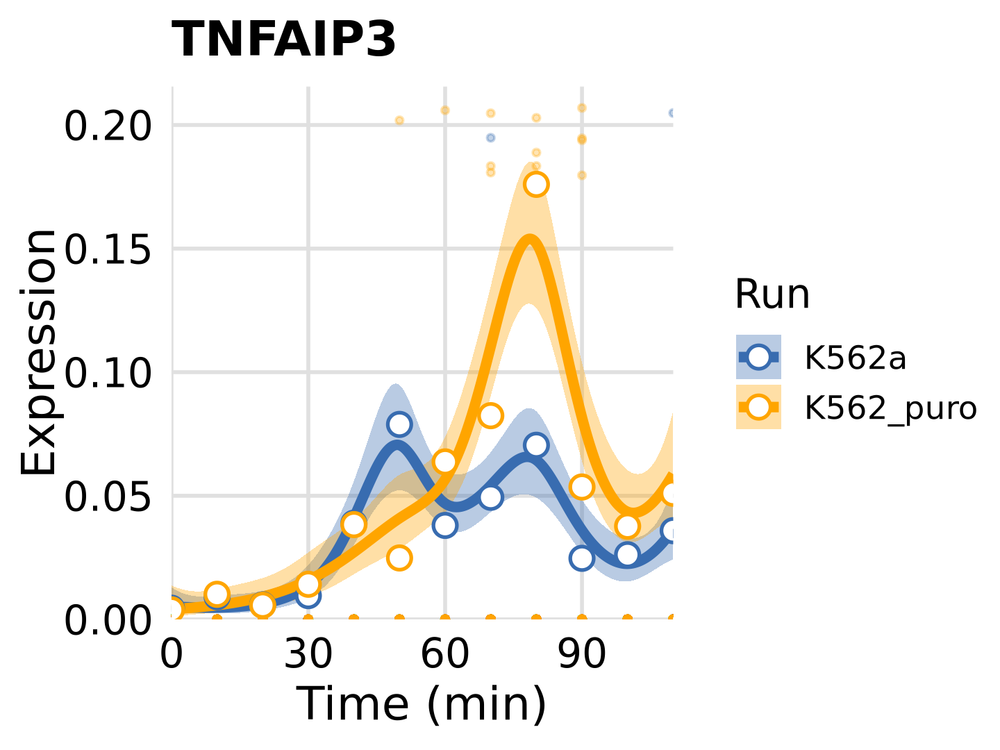

In [1119]:
options(repr.plot.width = 4.8, repr.plot.height = 3.6, repr.plot.res = 300)

time_map <- c(K562a = 110, K562_puro = 110, THP1 = 165, K562b = 165)  # adjust as needed
offset_map   = c(K562a = 0, K562_puro = 0, THP1 = -10, K562b = -68)

p <- plot_tradeSeq_gene_multirun_pub(
  gamList_ls     = gamList.ls,
  sce_ls         = sce.ls,
  counts_sub_ls  = counts_sub.ls,
  PT_ls          = PT.ls,
  sf_ls          = sf.ls,
  CW_ls          = CW.ls,          # or NULL
  keys           = c("K562a", "K562_puro"),

  key_labels     = NULL,
  colours        = c(K562a="#386cb0",K562_puro="#FFA500"),

  # offset_map = offset_map,
  time_max_map   = time_map,
  plot_normalized_pt = FALSE,

  x_tick_step    = 30,
  color_points_by_run = TRUE,
  points_size    = 0.75,
  points_alpha   = 0.30,

  show_legend    = TRUE,
  gene = "TNFAIP3"
)
print(p)

      K562a   K562_puro 
    "K562a" "K562_puro" 


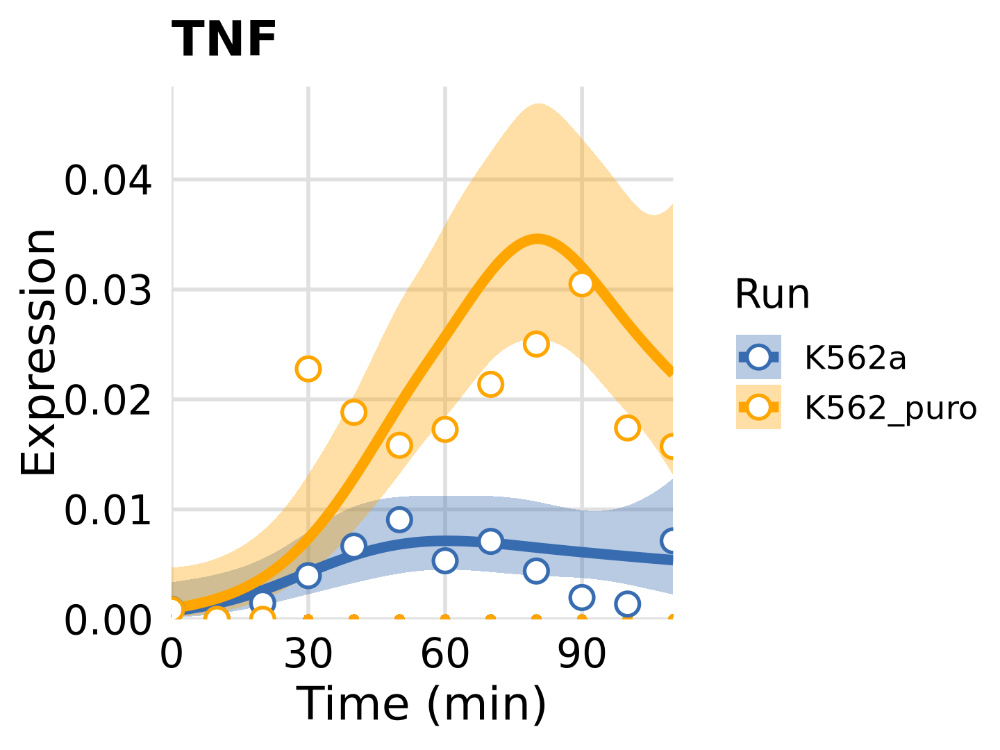

In [1214]:
options(repr.plot.width = 4.8, repr.plot.height = 3.6, repr.plot.res = 300)

time_map <- c(K562a = 110, K562_puro = 110, THP1 = 165, K562b = 165)  # adjust as needed
offset_map   = c(K562a = 0, K562_puro = 0, THP1 = -10, K562b = -68)

p <- plot_tradeSeq_gene_multirun_pub(
  gamList_ls     = gamList.ls,
  sce_ls         = sce.ls,
  counts_sub_ls  = counts_sub.ls,
  PT_ls          = PT.ls,
  sf_ls          = sf.ls,
  CW_ls          = CW.ls,          # or NULL
  keys           = c("K562a", "K562_puro"),

  key_labels     = NULL,
  colours        = c(K562a="#386cb0",K562_puro="#FFA500"),

  # offset_map = offset_map,
  time_max_map   = time_map,
  plot_normalized_pt = FALSE,

  x_tick_step    = 30,
  color_points_by_run = TRUE,
  points_size    = 0.75,
  points_alpha   = 0.30,

  show_legend    = TRUE,
  gene = "TNF"
)
print(p)

In [651]:
pc_df = pc_df %>% mutate(t_onset = t_onset*97, t_peak = t_peak*97)
# update only THP1 rows
pc_df <- pc_df %>%
  dplyr::mutate(
    t_peak = dplyr::if_else(cell_type == "THP1", t_peak / 0.65, t_peak),
    t_onset = dplyr::if_else(cell_type == "THP1", t_onset / 0.65, t_onset)
  )

In [1121]:
pc_df_subset <- pc_df %>% rownames_to_column('rn') %>% filter(abs(peak_log2fc) >= 0.5) %>% dplyr::group_by(cell_type) %>% 
                      dplyr::slice_max(order_by = waldStat_1, n = 300, with_ties = FALSE) %>% 
                      dplyr::ungroup() %>% as.data.frame() %>% column_to_rownames('rn')

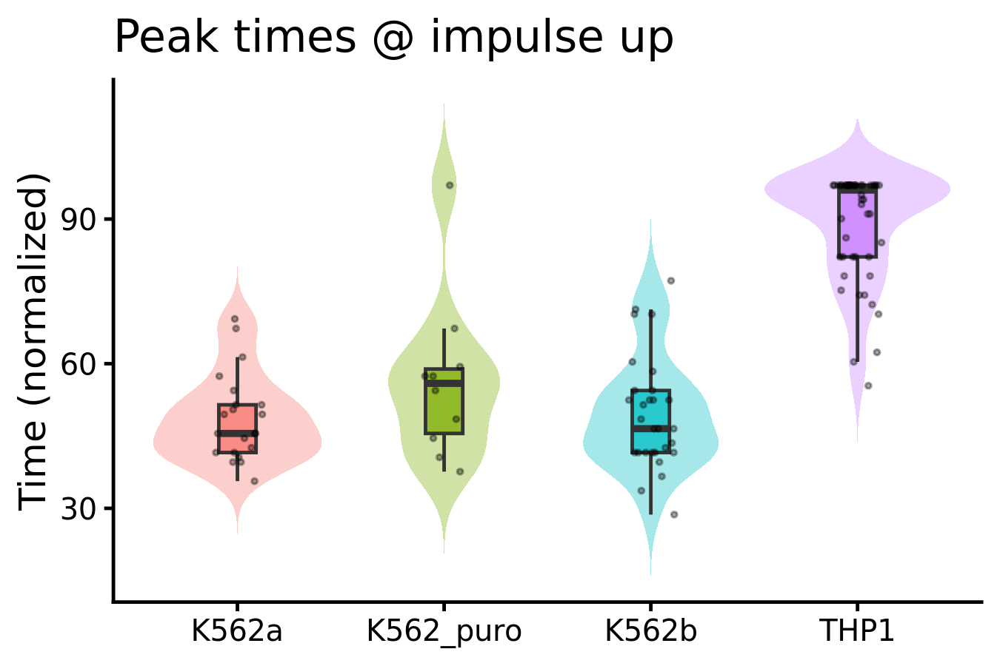

Warning message:
"Groups with fewer than two datapoints have been dropped.
i Set `drop = FALSE` to consider such groups for position adjustment purposes."


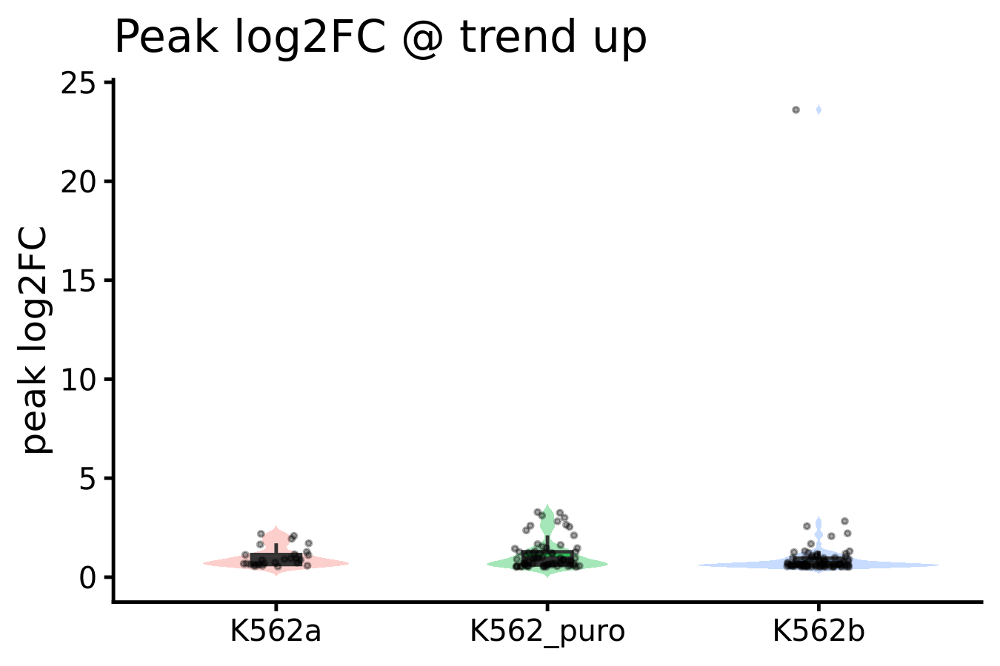

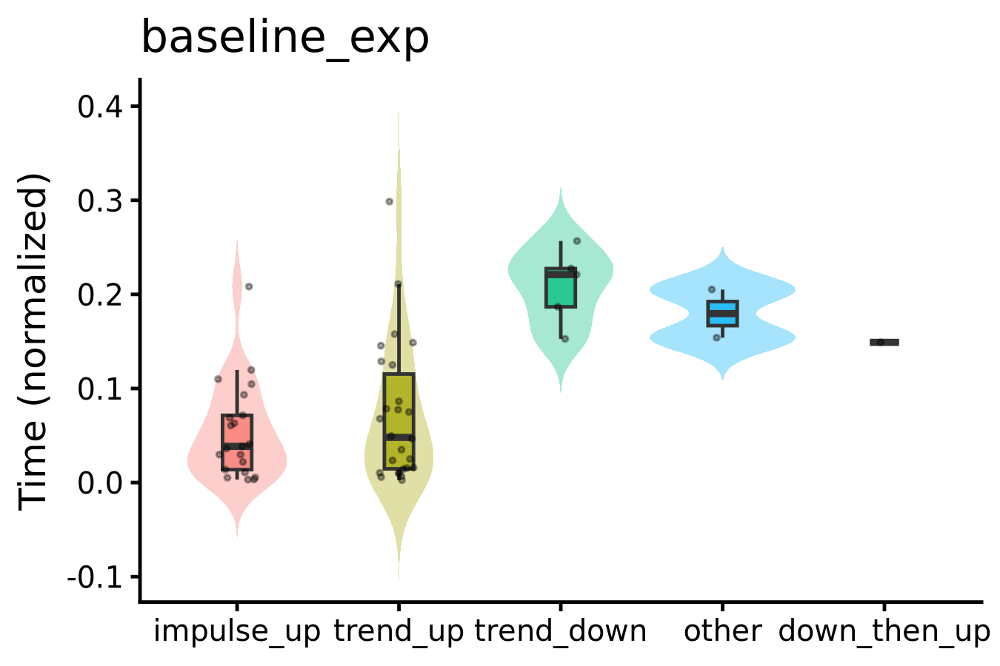

In [1122]:
plot_cluster_violin(y_title = 'Time (normalized)', plot_title = 'Peak times @ impulse up', 
                    plot_width = 4.5, plot_height = 3, 
                    print_summary = FALSE, print_top_genes = FALSE,
                    pc_df_subset, feature = 't_peak',
                    keys_use = c("K562a", "K562_puro", "K562b", "THP1"), cluster_col = 'broad_cluster',
                    compare_mode = "across_keys_for_cluster", cluster_use = 'impulse_up',
                    use_top_k = TRUE, top_k = 100, topk_mode = "per_key",
                    trim_percentiles = TRUE, trim_lower = 0, trim_upper = 1)

plot_cluster_violin(y_title = 'peak log2FC', plot_title = 'Peak log2FC @ trend up', 
                    plot_width = 4.5, plot_height = 3, 
                    print_summary = FALSE, print_top_genes = FALSE,
                    pc_df_subset, feature = 'peak_log2fc',
                    keys_use = c("K562a", "K562_puro", "K562b"), cluster_col = 'broad_cluster',
                    compare_mode = "across_keys_for_cluster", cluster_use = 'trend_up',
                    use_top_k = TRUE, top_k = 100, topk_mode = "per_key",
                    trim_percentiles = TRUE, trim_lower = 0.05, trim_upper = 1)

plot_cluster_violin(y_title = 'Time (normalized)', plot_title = 'baseline_exp', 
                    plot_width = 4.5, plot_height = 3, 
                    print_summary = FALSE, print_top_genes = FALSE,
                    pc_df_subset, feature = 'baseline_exp',
                    keys_use = c("K562a", "K562_puro", "K562b"), cluster_col = 'broad_cluster',
                    compare_mode = "across_clusters_for_key", key_use = 'K562a',
                    use_top_k = TRUE, top_k = 100, topk_mode = "per_key",
                    trim_percentiles = TRUE, trim_lower = 0.05, trim_upper = 0.95)

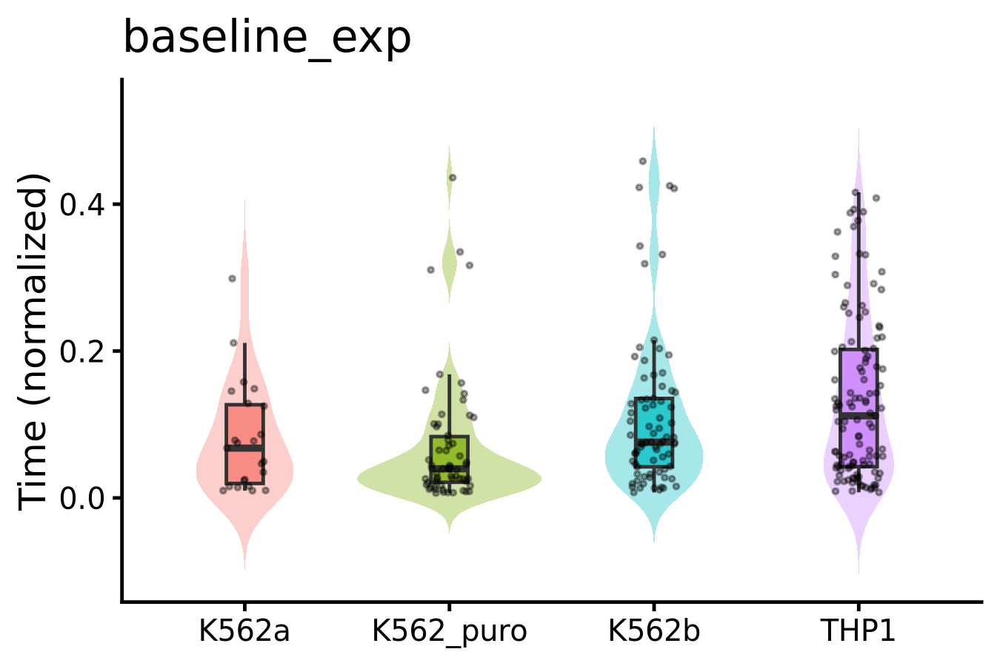

In [1179]:
plot_cluster_violin(y_title = 'Time (normalized)', plot_title = 'baseline_exp', 
                    plot_width = 4.5, plot_height = 3, 
                    print_summary = FALSE, print_top_genes = FALSE,
                    pc_df_subset, feature = 'baseline_exp',
                    keys_use = c("K562a", "K562_puro", "K562b", "THP1"), cluster_col = 'broad_cluster',
                    compare_mode = "across_keys_for_cluster", cluster_use = 'trend_up',
                    use_top_k = TRUE, top_k = 300, topk_mode = "per_key",
                    trim_percentiles = TRUE, trim_lower = 0.05, trim_upper = 0.9)

In [1195]:
quantile(counts_sub.ls[['K562a']], 0.99999)
quantile(counts_sub.ls[['K562b']], 0.99999)
quantile(counts_sub.ls[['THP1']], 0.99999)

99.999% 
275.5691

99.999% 
    240

99.999% 
    270

In [1198]:
table((pc_df %>% filter(abs(peak_log2fc) > 0.5))$cell_type)


K562_puro     K562a     K562b      THP1 
      151        61       174       986 

In [1123]:
RenameClusters = function(x) {
 if (x %in% c('impulse_up', 'trend_up')) {return('induced')}
 if (x == 'trend_down') {return('repressed')}
 if (x %in% c('down_then_up', 'other')) {return('mixed')}
}

pc_df$tmp = sapply(pc_df$broad_cluster, RenameClusters, USE.NAMES = F)

In [1124]:
pc_df_subset <- pc_df %>% rownames_to_column('rn') %>% filter(abs(peak_log2fc) >= 0.5) %>% dplyr::group_by(cell_type) %>% 
                      dplyr::slice_max(order_by = waldStat_1, n = 300, with_ties = FALSE) %>% 
                      dplyr::ungroup() %>% as.data.frame() %>% column_to_rownames('rn')

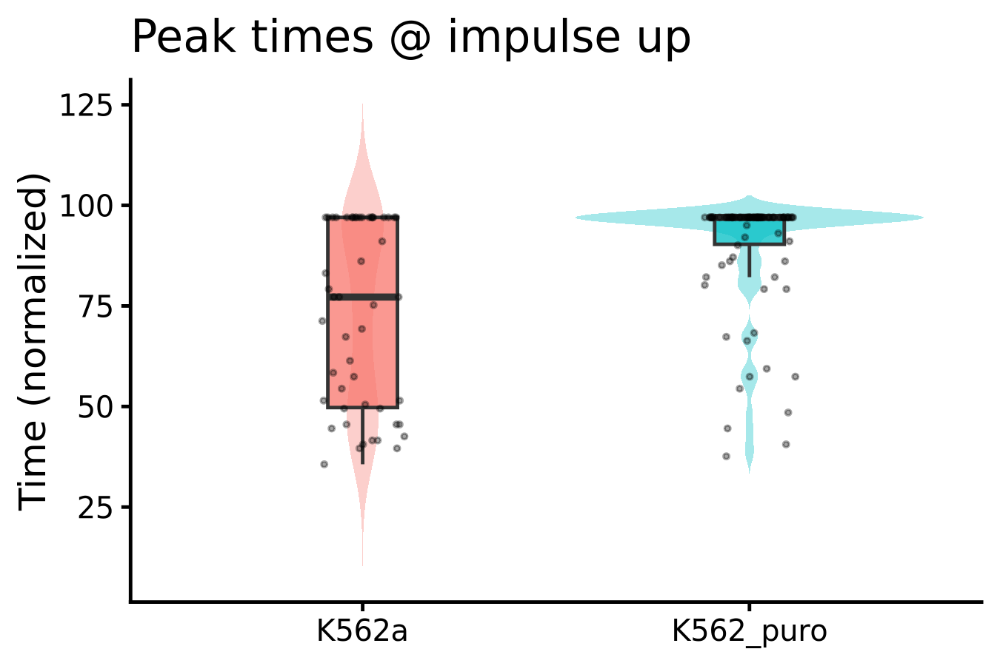

In [1125]:
plot_cluster_violin(y_title = 'Time (normalized)', plot_title = 'Peak times @ impulse up', 
                    plot_width = 4.5, plot_height = 3, 
                    print_summary = FALSE, print_top_genes = FALSE,
                    pc_df_subset, feature = 't_peak',
                    keys_use = c("K562a", "K562_puro"), cluster_col = 'tmp',
                    compare_mode = "across_keys_for_cluster", cluster_use = 'induced',
                    use_top_k = TRUE, top_k = 100, topk_mode = "per_key",
                    trim_percentiles = TRUE, trim_lower = 0, trim_upper = 1)

      K562a   K562_puro 
    "K562a" "K562_puro" 


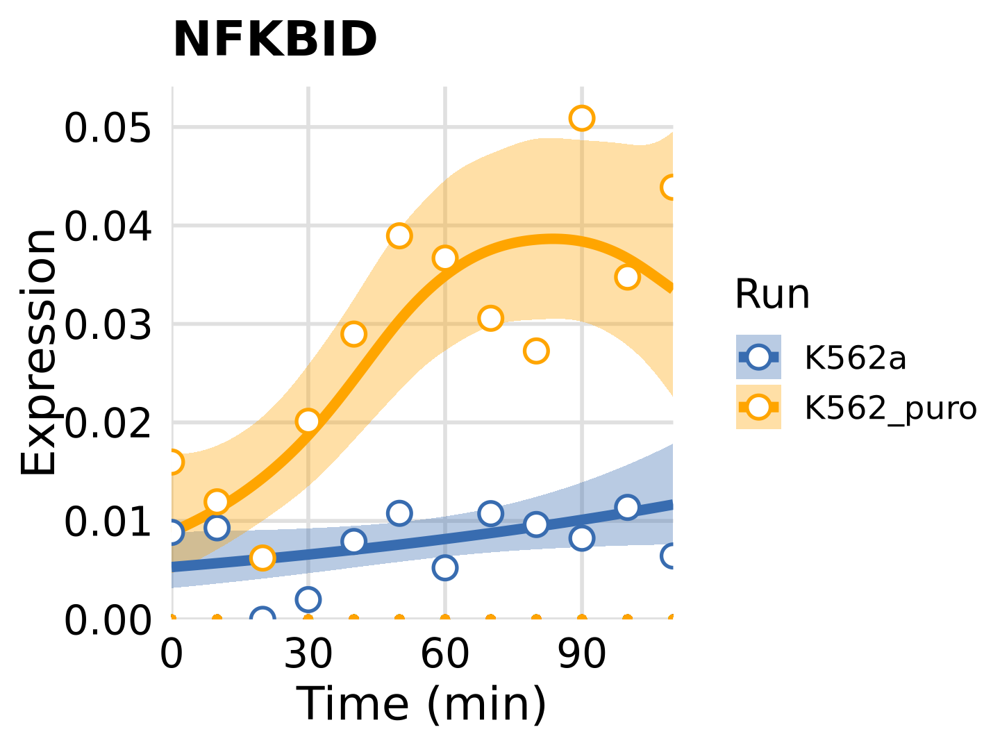

In [62]:
options(repr.plot.width = 4.8, repr.plot.height = 3.6, repr.plot.res = 300)

time_map <- c(K562a = 110, K562_puro = 110, THP1 = 165, K562b = 165)  # adjust as needed
offset_map   = c(K562a = 0, K562_puro = 0, THP1 = -10, K562b = -68)

p <- plot_tradeSeq_gene_multirun_pub(
  gamList_ls     = gamList.ls,
  sce_ls         = sce.ls,
  counts_sub_ls  = counts_sub.ls,
  PT_ls          = PT.ls,
  sf_ls          = sf.ls,
  CW_ls          = CW.ls,          # or NULL
  keys           = c("K562a", "K562_puro"),

  key_labels     = NULL,
  colours        = c(K562a="#386cb0",K562_puro="#FFA500", K562b="#FF0000"),

  offset_map = offset_map,
  time_max_map   = time_map,
  plot_normalized_pt = FALSE,

  x_tick_step    = 30,
  color_points_by_run = TRUE,
  points_size    = 0.75,
  points_alpha   = 0.30,

  show_legend    = TRUE,
  gene = "NFKBID"
)
print(p)

In [1127]:
set1 = (pc_df_subset %>% filter(cell_type == 'K562a', broad_cluster == 'impulse_up'))$gene
set2 = (pc_df_subset %>% filter(cell_type == 'K562_puro', broad_cluster == 'trend_up'))$gene
intersect(set1, set2)

[1] "NFKBIA"  "CXCL3"   "CXCL8"   "CXCL1"   "IRF1"    "KLF6"    "JUN"    
 [8] "CXCL2"   "TIFA"    "PIM3"    "GADD45B" "NAB2"

In [950]:
# saveRDS(traj_mat, 'traj_mat.rds')
# saveRDS(X, 'X.rds')
# saveRDS(pc, 'pc.rds')
# saveRDS(tt, 'tt.rds')
# saveRDS(asso_df.ls, 'asso_df_ls.rds')

# saveRDS(gamList.ls, 'gamList_ls.rds')
# saveRDS(sce.ls, 'sce_ls.rds')
# saveRDS(counts_sub.ls, 'counts_sub_ls.rds')
# saveRDS(PT.ls, 'PT_ls.rds')
# saveRDS(CW.ls, 'CW_ls.rds')
# saveRDS(sf.ls, 'sf_ls.rds')

In [1330]:
# desc = get_descriptors(traj_mat, tt, N_minutes = 10/length(tt), z_diff_threshold = 0.2, require_consecutive = 30, onset_mode = 'horizontal', pseudocount=1e-3)
# pc_df$peak_log2fc = desc[rownames(pc_df), 'peak_log2fc']